# Dataset, per-(time point, condition) gene selection, human orthologs

Every shared condition label (e.g. "24h Af+O3") analysed separately,
start to finish. It is split into a measurement time and a
condition, gets its own top-N gene selection here (summarised
in the CELL 1 heatmap), its own interaction network in CELL 2, its own ranking in
CELL 3, Hex binding scores for its drawn edges in CELL 4, and its own panel in the
CELL 5 network graph figure (its docking results
are summarised in the CELL 6 Figure 3).

Run this cell first. Update the configuration values below for your dataset before running the remaining cells. Keep the CSV file in the notebook's working directory, or set `CSV_FILE` to its path.

In [2]:
import re
import sys
import json
import requests
import pandas as pd

WEBSITE_API = "https://rest.uniprot.org/"

def get_url(url, **kwargs):
    """Fetch a URL and return the response, exiting on an HTTP error."""
    response = requests.get(url, **kwargs)
    if not response.ok:
        print(response.text)
        response.raise_for_status()
        sys.exit()
    return response


CSV_FILE = "NewAffydata.csv"           # <-- the CSV file name

TARGET_STRAIN = "SP-D KO"              # the strain of interest (e.g. a knockout)
REFERENCE_STRAINS = ["BL/6", "Balb/c"] # exactly two reference strains to compare against (provisional)

EXCLUDE_NAMES = set()          

LABEL_COL = 0                          # column holding the "<strain> <condition>" labels
TOP_N = 15                             # number of top genes to select PER PANEL

TIME_REGEX = r"^\s*(\d+(?:\.\d+)?)\s*h\b\s*"   # group 1 = hours; matched at the label start
UNTIMED_TIME_LABEL = "No allergen"             # row for labels with no time token (air / O3 alone)
ALLERGEN_GROUP_LABEL = "Af challenged"   # bracket drawn beside the timed rows (None = off)
CONDITION_COLUMNS = {                          # label -> column, in column order
    "air":    "Filtered air",
    "Af+air": "Filtered air",
    "O3":     "Ozone (O3)",
    "Af+O3":  "Ozone (O3)",
}                                              


if len(REFERENCE_STRAINS) != 2:
    raise ValueError(
        f"REFERENCE_STRAINS must contain exactly two strains; got {REFERENCE_STRAINS}"
    )
REF_A, REF_B = REFERENCE_STRAINS
ALL_STRAINS = REFERENCE_STRAINS + [TARGET_STRAIN]
DIFF_A_COL = f"Diff ([{TARGET_STRAIN}] - [{REF_A}])"
DIFF_B_COL = f"Diff ([{TARGET_STRAIN}] - [{REF_B}])"

raw = pd.read_csv(CSV_FILE, header=None, dtype=str)
print(f"Loading data from: {CSV_FILE}")

DATA_COLS = list(range(1, raw.shape[1]))
gene_names = raw.loc[0, DATA_COLS].tolist()

def _dataset_clean(raw_name):
    return str(raw_name).split("///")[0].strip()

dataset_gene_symbols = {
    _dataset_clean(n).upper() for n in gene_names if _dataset_clean(n)
}


def search_symbol(raw_name):
    """First symbol before any '///' in a combined-probe label."""
    return raw_name.split("///")[0].strip()

gene_positions = {}                    # gene symbol -> its first data column
gene_query = {}                        # gene symbol -> symbol used for the UniProt search
for pos, name in enumerate(gene_names):
    clean = str(name).strip()
    if clean in gene_positions:
        continue                       # keep only the first column for this gene
    gene_positions[clean] = DATA_COLS[pos]
    gene_query[clean] = search_symbol(clean)


def row_values(line):
    """Value of each gene's column for one row of the file."""
    numeric = pd.to_numeric(raw.loc[line, DATA_COLS], errors="coerce")
    return {gene: numeric[col] for gene, col in gene_positions.items()}

row_label = {}                          # row index -> condition label
row_genes = {}                          # row index -> {gene: value}
for line in range(1, raw.shape[0]):     # every row after the header row
    label = raw.loc[line, LABEL_COL]
    if pd.isna(label):
        continue
    row_label[line] = str(label).strip()
    row_genes[line] = row_values(line)


_STRAINS_BY_LEN = sorted(ALL_STRAINS, key=len, reverse=True)

def split_label(label):
    for strain in _STRAINS_BY_LEN:
        if label.startswith(strain):
            return strain, label[len(strain):].strip()
    return None, label

rows_by_strain = {s: {} for s in ALL_STRAINS}
for line, label in row_label.items():
    strain, cond = split_label(label)
    if strain is not None:
        rows_by_strain[strain][cond] = line

SHARED_CONDITIONS = [
    cond for cond in rows_by_strain[TARGET_STRAIN]
    if all(cond in rows_by_strain[ref] for ref in REFERENCE_STRAINS)
]
print(f"Conditions compared (shared across target and both references): "
      f"{SHARED_CONDITIONS}\n")


def _cond_key(text):
    return re.sub(r"\s+", "", str(text)).lower()

_COLUMN_OF = {_cond_key(k): v for k, v in CONDITION_COLUMNS.items()}

def split_time_condition(cond_label):
    """'24h Af+O3' -> ('24h', 24.0, 'O3 + Af');   'air' -> (UNTIMED_TIME_LABEL, -1.0, 'air')."""
    m = re.match(TIME_REGEX, cond_label)
    if m:
        hours = float(m.group(1))
        time_label = f"{m.group(1)} h"
        rest = cond_label[m.end():]
    else:
        hours, time_label, rest = -1.0, UNTIMED_TIME_LABEL, cond_label   # untimed sorts first
    rest = rest.strip() or cond_label.strip()
    return time_label, hours, _COLUMN_OF.get(_cond_key(rest), rest)

PANEL_LABEL = {}                        # (time, condition) -> shared condition label
_time_hours = {}
CONDITION_COLS = list(dict.fromkeys(CONDITION_COLUMNS.values()))   # configured column order
for cond in SHARED_CONDITIONS:
    t, hrs, c = split_time_condition(cond)
    if (t, c) in PANEL_LABEL:
        raise ValueError(
            f"Condition labels '{PANEL_LABEL[(t, c)]}' and '{cond}' both map to panel "
            f"({t}, {c}); adjust TIME_REGEX / CONDITION_COLUMNS.")
    PANEL_LABEL[(t, c)] = cond
    _time_hours[t] = hrs
    if c not in CONDITION_COLS:
        CONDITION_COLS.append(c)
TIME_ROWS = sorted(_time_hours, key=_time_hours.get)       # grid rows, earliest first
_used_cols = {c for _, c in PANEL_LABEL}
CONDITION_COLS = [c for c in CONDITION_COLS if c in _used_cols]  # drop columns with no data
PANELS = [(t, c) for t in TIME_ROWS for c in CONDITION_COLS if (t, c) in PANEL_LABEL]

def panel_title(panel):
    """Short text name of a panel, e.g. '24h | O3'."""
    return f"{panel[0]} | {panel[1]}"

print(f"Panel grid: {len(TIME_ROWS)} time point(s) x {len(CONDITION_COLS)} condition(s)")
print(f"  rows    (time)      : {', '.join(TIME_ROWS)}")
print(f"  columns (condition) : {', '.join(CONDITION_COLS)}")
for _p in PANELS:
    print(f"    {panel_title(_p):<28} <- '{PANEL_LABEL[_p]}'")
print()


def select_top_genes(panel, top_n=TOP_N):
    """Return the list of item dicts (one per gene kept) for ONE panel."""
    cond = PANEL_LABEL[panel]
    tgt_vals = row_genes[rows_by_strain[TARGET_STRAIN][cond]]
    a_vals   = row_genes[rows_by_strain[REF_A][cond]]
    b_vals   = row_genes[rows_by_strain[REF_B][cond]]

    diffs = {}                          # gene -> (diff_vs_ref_a, diff_vs_ref_b)
    for gene in gene_positions:
        if gene.lower() in EXCLUDE_NAMES:
            continue
        d_a = tgt_vals[gene] - a_vals[gene]
        d_b = tgt_vals[gene] - b_vals[gene]
        if pd.isna(d_a) or pd.isna(d_b):
            continue
        diffs[gene] = (d_a, d_b)

    ranked = sorted(diffs.items(),
                    key=lambda kv: max(abs(kv[1][0]), abs(kv[1][1])),
                    reverse=True)[:top_n]
    return [{
        "Time": panel[0],
        "Condition": panel[1],
        "Condition label": cond,
        "Gene": gene,
        DIFF_A_COL: round(float(d_a), 3),
        DIFF_B_COL: round(float(d_b), 3),
        "Larger |difference|": round(float(max(abs(d_a), abs(d_b))), 3),
    } for gene, (d_a, d_b) in ranked]

panel_items = {p: select_top_genes(p) for p in PANELS}      # panel -> its own top-N items
selected_items = [it for p in PANELS for it in panel_items[p]]   # flat view (all panels)

from IPython.display import display
pd.set_option("display.max_colwidth", None)

def show(df, title):
    """Display a table with left-aligned columns."""
    print(title)
    try:
        display(df.style.set_properties(**{"text-align": "left"})
                        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))
    except Exception:
        print(df.to_string(index=False, justify="left"))

_distinct_genes = sorted({it["Gene"] for it in selected_items})
print(f"Selected top {TOP_N} genes in each of {len(PANELS)} panels "
      f"({len(selected_items)} (gene, panel) pairs; {len(_distinct_genes)} distinct genes).\n")


NCBI_DATASETS_API = "https://api.ncbi.nlm.nih.gov/datasets/v2"
MOUSE_TAXON = 10090                    # Mus musculus (source of the dataset)
HUMAN_TAXON = 9606                     # Homo sapiens (interaction-search target)
NCBI_API_KEY = None                    # optional: paste an NCBI API key to raise the rate limit
NCBI_ORTHO_TIMEOUT = 60

_ortho_cache = {}                      # mouse symbol (as queried) -> (human_symbol, human_gene_id)

ORTHOLOG_OVERRIDES = {}

def _normalize_override_key(symbol):
    """Match override keys loosely: lowercase, strip spaces, unify separators."""
    s = str(symbol).strip().lower()
    s = s.replace(" /// ", ",").replace("///", ",").replace(" ", "")
    return s

def _curated_ortholog(mouse_symbol):
    """Return (human_symbol, human_gene_id) if curated, else None."""
    key = _normalize_override_key(mouse_symbol)
    if key in ORTHOLOG_OVERRIDES:
        sym, gid = ORTHOLOG_OVERRIDES[key]
        return (sym, gid if gid is not None else "NA")
    return None

def _ncbi_headers():
    h = {"Accept": "application/json"}
    if NCBI_API_KEY:
        h["api-key"] = NCBI_API_KEY
    return h

def _resolve_mouse_gene_id(mouse_symbol):
    """Return the NCBI gene-id (string) for a mouse gene symbol, or None."""
    url = f"{NCBI_DATASETS_API}/gene/symbol/{mouse_symbol}/taxon/{MOUSE_TAXON}"
    try:
        r = requests.get(url, headers=_ncbi_headers(), timeout=NCBI_ORTHO_TIMEOUT)
    except Exception as exc:
        print(f"  [NCBI] gene-id request failed for {mouse_symbol} ({exc})")
        return None
    if not r.ok or not r.text.strip():
        return None
    try:
        reports = (r.json() or {}).get("reports") or []
    except ValueError:
        return None
    if not reports:
        return None
    want = str(mouse_symbol).strip().lower()
    taxon_only_gid = None
    for rep in reports:
        gene = rep.get("gene") or {}
        tax = gene.get("tax_id") or gene.get("taxId")
        try:
            tax = int(tax)
        except (TypeError, ValueError):
            tax = None
        if tax != MOUSE_TAXON:
            continue
        gid = gene.get("gene_id") or gene.get("geneId")
        sym = str(gene.get("symbol") or gene.get("name") or "").strip().lower()
        if sym == want:
            return str(gid) if gid else None      # exact, current-symbol match
        if taxon_only_gid is None and gid:
            taxon_only_gid = str(gid)              # remember first same-taxon hit
    if taxon_only_gid is not None:
        print(f"  [NCBI] '{mouse_symbol}': no exact symbol match, using "
              f"nearest same-taxon hit (verify) gene_id={taxon_only_gid}")
        return taxon_only_gid
    return None

def _human_ortholog_from_reports(reports):
    """Pull (human_symbol, human_gene_id) out of an orthologs 'reports' list."""
    for rep in reports:
        gene = rep.get("gene") if isinstance(rep, dict) else None
        if not isinstance(gene, dict):
            continue
        tax = gene.get("tax_id") or gene.get("taxId")
        try:
            tax = int(tax)
        except (TypeError, ValueError):
            tax = None
        if tax == HUMAN_TAXON:
            sym = gene.get("symbol") or gene.get("name")
            gid = gene.get("gene_id") or gene.get("geneId")
            if sym:
                return sym.strip(), (str(gid) if gid else "NA")
    return None, None

def lookup_human_ortholog(mouse_symbol):
    """Return (human_symbol, human_gene_id) for a mouse gene symbol via NCBI.

    Caches results. Returns ("NA", "NA") if no human ortholog is found or the
    service is unreachable, so a single miss never aborts the run.
    """
    if mouse_symbol in _ortho_cache:
        return _ortho_cache[mouse_symbol]

    curated = _curated_ortholog(mouse_symbol)
    if curated is not None:
        _ortho_cache[mouse_symbol] = curated
        return curated

    result = ("NA", "NA")
    gene_id = _resolve_mouse_gene_id(mouse_symbol)
    if gene_id:
        url = f"{NCBI_DATASETS_API}/gene/id/{gene_id}/orthologs"
        try:
            r = requests.get(url, headers=_ncbi_headers(),
                             params={"taxon_filter": HUMAN_TAXON},
                             timeout=NCBI_ORTHO_TIMEOUT)
        except Exception as exc:
            print(f"  [NCBI] ortholog request failed for {mouse_symbol} ({exc})")
            r = None
        if r is not None and r.ok and r.text.strip():
            try:
                reports = (r.json() or {}).get("reports") or []
            except ValueError:
                reports = []
            human_symbol, human_gene_id = _human_ortholog_from_reports(reports)
            if human_symbol:
                result = (human_symbol, human_gene_id or "NA")

    _ortho_cache[mouse_symbol] = result
    return result

print("Mapping selected mouse genes to human orthologs (NCBI Datasets)...")

mouse_to_human = {}
for gene in _distinct_genes:
    human_symbol, human_gene_id = lookup_human_ortholog(gene_query[gene])
    mouse_to_human[gene] = {"human_symbol": human_symbol,
                            "human_gene_id": human_gene_id}

for item in selected_items:
    m = item["Gene"]
    item["Human Ortholog"] = mouse_to_human[m]["human_symbol"]
    item["Human Gene ID"] = mouse_to_human[m]["human_gene_id"]

_n_mapped = sum(1 for g in _distinct_genes
                if mouse_to_human[g]["human_symbol"] not in ("NA", None))
print(f"  Human orthologs found for {_n_mapped} of {len(_distinct_genes)} "
      f"distinct mouse genes.")
for _p in PANELS:
    _hs = sorted({it["Human Ortholog"] for it in panel_items[_p]
                  if it["Human Ortholog"] not in ("NA", None)})
    print(f"    {panel_title(_p):<28} {len(_hs):>2} seed ortholog(s): {', '.join(_hs)}")
print()

selected_df = pd.DataFrame(selected_items)
_front = ["Time", "Condition", "Gene", "Human Ortholog", "Human Gene ID",
          DIFF_A_COL, DIFF_B_COL, "Larger |difference|"]
selected_df = selected_df[[c for c in _front if c in selected_df.columns]]

show(selected_df, "Selected genes per panel (time point x condition) with human orthologs")


Loading data from: NewAffydata.csv
Conditions compared (shared across target and both references): ['air', '24h Af+air', '168h Af+air', 'O3', '24h Af+O3', '168h Af+O3']

Panel grid: 3 time point(s) x 2 condition(s)
  rows    (time)      : No allergen, 24 h, 168 h
  columns (condition) : Filtered air, Ozone (O3)
    No allergen | Filtered air   <- 'air'
    No allergen | Ozone (O3)     <- 'O3'
    24 h | Filtered air          <- '24h Af+air'
    24 h | Ozone (O3)            <- '24h Af+O3'
    168 h | Filtered air         <- '168h Af+air'
    168 h | Ozone (O3)           <- '168h Af+O3'

Selected top 15 genes in each of 6 panels (90 (gene, panel) pairs; 25 distinct genes).

Mapping selected mouse genes to human orthologs (NCBI Datasets)...
  [NCBI] 'C1s': no exact symbol match, using nearest same-taxon hit (verify) gene_id=50908
  [NCBI] 'Ptpla': no exact symbol match, using nearest same-taxon hit (verify) gene_id=30963
  [NCBI] 'Ptplb': no exact symbol match, using nearest same-taxon hi

,Time,Condition,Gene,Human Ortholog,Human Gene ID,Diff ([SP-D KO] - [BL/6]),Diff ([SP-D KO] - [Balb/c]),Larger |difference|
0,No allergen,Filtered air,Ear1,NA,NA,1779.000000,1750.000000,1779.000000
1,No allergen,Filtered air,Padi2,PADI2,11240,-93.000000,-592.000000,592.000000
2,No allergen,Filtered air,Ear3,NA,NA,489.000000,478.000000,489.000000
3,No allergen,Filtered air,Srrm2,SRRM2,23524,447.000000,-21.000000,447.000000
4,No allergen,Filtered air,C1qa,C1QA,712,66.000000,-428.000000,428.000000
5,No allergen,Filtered air,Cfd,CFD,1675,73.000000,-332.000000,332.000000
6,No allergen,Filtered air,Prmt2,PRMT2,3275,301.000000,7.000000,301.000000
7,No allergen,Filtered air,C1s /// LOC100044326,NA,NA,248.000000,126.000000,248.000000
8,No allergen,Filtered air,Ptpla,HACD1,9200,244.000000,-122.000000,244.000000
9,No allergen,Filtered air,Nos1ap,NOS1AP,9722,12.000000,-221.000000,221.000000


# Figure 2: heatmap of every condition's top-N seed genes (Δ expression)

Runs after CELL 0 : it needs only the dataset and the per-condition gene
selection; nothing from the interaction, specificity or docking cells.

Input (from prev cell) : row_genes, rows_by_strain, gene_positions, panel_items, PANELS, PANEL_LABEL,
TIME_ROWS, TARGET_STRAIN, REF_A / REF_B, DIFF_A_COL / DIFF_B_COL, TOP_N (CELL 0).

Output: heatmap_df (one row per gene, one column per condition x comparison), the
figure, and seed_heatmap.pdf / seed_heatmap.png next to the notebook. Both files
are EXACTLY HEATMAP_SIZE_IN (the poster's Figure 2 box, 9.4 x 5.8 in), so they
drop into the poster at 100 % with no rescaling.

What is drawn (horizontal layout, to fill the landscape Figure 2 box)
Columns : every gene that is in the top TOP_N of AT LEAST ONE condition (the genes the
networks are seeded from), ordered by their mean signed Δ over all rows -- most
raised in the knockout on the LEFT, most lowered on the RIGHT. Genes listed in
HEATMAP_CONTROL_GENES (default Sftpd, the knocked-out gene) follow after a gap
as a sanity check.
Rows    : the conditions in the order of the Figure 1 grid (no allergen, then Af at each
time point; air above O3), each split into the two comparisons
TARGET - REF_A and TARGET - REF_B.
Cells   : the signed difference TARGET - reference in that condition, in the units of the
data file, printed in the cell. An outline (and a bold value) marks the
conditions in which the gene is one of that condition's top TOP_N; the other
cells give the same gene's difference elsewhere, for context.
Colour  : IDENTICAL to the node colours of the Figure 1 network grid (CELL 5): the same
red - white - green colour map (CELL 5's EXPR_COLORS) on the same LINEAR scale
-M .. +M, where M is the largest |Δ| of any seed that has a human ortholog,
SP-D excluded, exactly how CELL 5 computes _M. A heatmap cell and a network
node with the same Δ are therefore the same colour. If you change EXPR_COLORS,
SPD_NODE_SYMBOLS or SPD_MOUSE_GENES in CELL 5, change the matching
HEATMAP_* values below too.

Run after Step 1 has completed; this cell uses objects created by the earlier steps.

Saved /Users/aden/Desktop/seed_heatmap.pdf  (9.4 x 5.8 in -- place at 100 %)
Saved /Users/aden/Desktop/seed_heatmap.png  (9.4 x 5.8 in -- place at 100 %)


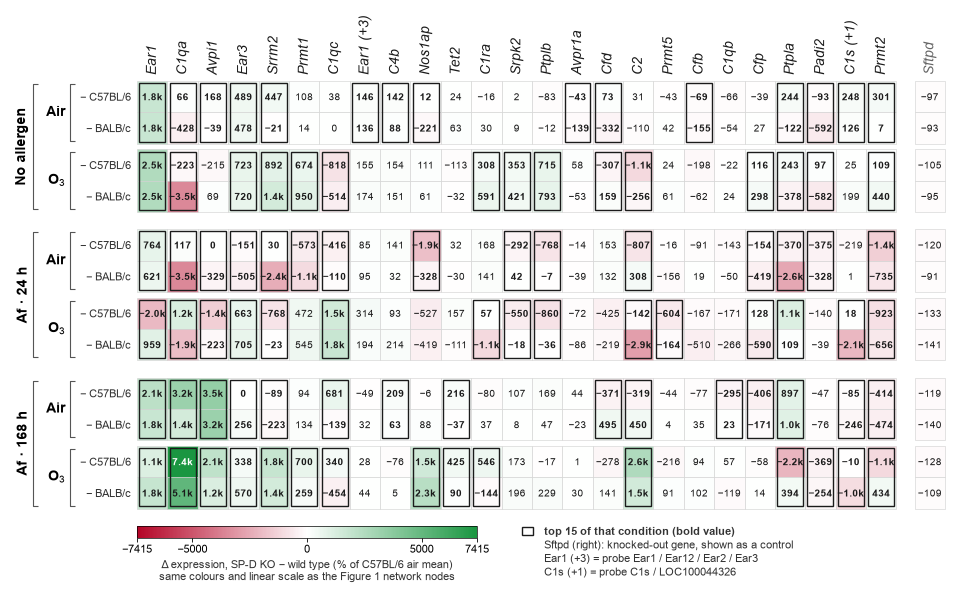


25 gene(s) are in the top 15 of at least one of the 6 conditions (14 higher and 11 lower in SP-D KO on average). Colour scale ±7,415, linear -- the Figure 1 node scale.
Cells are 0.30 x 0.31 in; cell values 7 pt, labels 10 pt, font Arial.
Δ expression (SP-D KO − reference, % of C57BL/6 air mean) behind the heatmap


,Gene,Human Ortholog,Top 15 in,No allergen | Filtered air | SP-D KO − C57BL/6,No allergen | Filtered air | SP-D KO − BALB/c,No allergen | Ozone (O3) | SP-D KO − C57BL/6,No allergen | Ozone (O3) | SP-D KO − BALB/c,24 h | Filtered air | SP-D KO − C57BL/6,24 h | Filtered air | SP-D KO − BALB/c,24 h | Ozone (O3) | SP-D KO − C57BL/6,24 h | Ozone (O3) | SP-D KO − BALB/c,168 h | Filtered air | SP-D KO − C57BL/6,168 h | Filtered air | SP-D KO − BALB/c,168 h | Ozone (O3) | SP-D KO − C57BL/6,168 h | Ozone (O3) | SP-D KO − BALB/c
0,Ear1,,"No allergen | Filtered air, No allergen | Ozone (O3), 24 h | Filtered air, 24 h | Ozone (O3), 168 h | Filtered air, 168 h | Ozone (O3)",1779.000000,1750.000000,2498.000000,2536.000000,764.000000,621.000000,-2042.000000,959.000000,2149.000000,1768.000000,1113.000000,1796.000000
1,C1qa,C1QA,"No allergen | Filtered air, No allergen | Ozone (O3), 24 h | Filtered air, 24 h | Ozone (O3), 168 h | Filtered air, 168 h | Ozone (O3)",66.000000,-428.000000,-223.000000,-3486.000000,117.000000,-3526.000000,1164.000000,-1930.000000,3207.000000,1443.000000,7415.000000,5143.000000
2,Avpi1,AVPI1,"No allergen | Filtered air, 24 h | Filtered air, 24 h | Ozone (O3), 168 h | Filtered air, 168 h | Ozone (O3)",168.000000,-39.000000,-215.000000,69.000000,0.000000,-329.000000,-1440.000000,-223.000000,3461.000000,3239.000000,2082.000000,1195.000000
3,Ear3,,"No allergen | Filtered air, No allergen | Ozone (O3), 24 h | Filtered air, 24 h | Ozone (O3), 168 h | Filtered air, 168 h | Ozone (O3)",489.000000,478.000000,723.000000,720.000000,-151.000000,-505.000000,663.000000,705.000000,0.000000,256.000000,338.000000,570.000000
4,Srrm2,SRRM2,"No allergen | Filtered air, No allergen | Ozone (O3), 24 h | Filtered air, 24 h | Ozone (O3), 168 h | Filtered air, 168 h | Ozone (O3)",447.000000,-21.000000,892.000000,1401.000000,30.000000,-2425.000000,-768.000000,-23.000000,-89.000000,-223.000000,1836.000000,1428.000000
5,Prmt1,PRMT1,"No allergen | Ozone (O3), 24 h | Filtered air, 168 h | Ozone (O3)",108.000000,14.000000,674.000000,950.000000,-573.000000,-1084.000000,472.000000,545.000000,94.000000,134.000000,700.000000,259.000000
6,C1qc,C1QC,"No allergen | Ozone (O3), 24 h | Filtered air, 24 h | Ozone (O3), 168 h | Filtered air, 168 h | Ozone (O3)",38.000000,0.000000,-818.000000,-514.000000,-416.000000,-110.000000,1484.000000,1786.000000,681.000000,-139.000000,340.000000,-454.000000
7,Ear1 /// Ear12 /// Ear2 /// Ear3,,No allergen | Filtered air,146.000000,136.000000,155.000000,174.000000,85.000000,95.000000,314.000000,194.000000,-49.000000,32.000000,28.000000,44.000000
8,C4b,,"No allergen | Filtered air, 168 h | Filtered air",142.000000,88.000000,154.000000,151.000000,141.000000,32.000000,93.000000,214.000000,209.000000,63.000000,-76.000000,5.000000
9,Nos1ap,NOS1AP,"No allergen | Filtered air, 24 h | Filtered air, 168 h | Ozone (O3)",12.000000,-221.000000,111.000000,61.000000,-1904.000000,-328.000000,-527.000000,-419.000000,-6.000000,88.000000,1537.000000,2305.000000


In [3]:
import math
import os
import textwrap
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator

for _req in ("row_genes", "rows_by_strain", "gene_positions", "panel_items", "PANELS",
             "PANEL_LABEL", "TIME_ROWS", "TARGET_STRAIN", "REF_A", "REF_B",
             "DIFF_A_COL", "DIFF_B_COL", "TOP_N"):
    if _req not in globals():
        raise RuntimeError(f"'{_req}' missing -- run CELL 0 (dataset / gene selection) first.")

HEATMAP_SIZE_IN     = (9.4, 5.8)  # (width, height) of the figure in inches -- the poster's
HEATMAP_GENE_ORDER  = "mean"      # "mean": by mean signed Δ (up on the left, down on the right)
HEATMAP_ANNOTATE    = True        # print the signed value in every cell
HEATMAP_CONTROL_GENES = ["Sftpd"] # drawn as separate columns on the right ([] = none);
HEATMAP_UNITS       = "% of C57BL/6 air mean"   # units of the values in the CSV file
HEATMAP_STRAIN_NAMES = {"BL/6": "C57BL/6", "Balb/c": "BALB/c"}       # display names
HEATMAP_CONDITION_NAMES = {"Filtered air": "Air", "Ozone (O3)": "O$_3$"}
HEATMAP_TIME_NAMES  = {"24 h": "Af · 24 h", "168 h": "Af · 168 h"}   # as in the poster's
HEATMAP_TITLE       = ""          # "" = no title (the poster's section heading and caption
HEATMAP_FONT_FAMILY = ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]
HEATMAP_FONT        = 10.0        # labels (pt); ticks and notes are 2 pt smaller
HEATMAP_VALUE_FONT  = 7.0         # cell values (pt); reduced automatically if a value would
HEATMAP_PDF         = "seed_heatmap.pdf"   # vector copy (None = skip) -- fonts embedded as text
HEATMAP_PNG         = "seed_heatmap.png"   # raster copy (None = skip)
HEATMAP_DPI         = 300

HEATMAP_EXPR_COLORS = ["#b40426", "#ffffff", "#1a9641"]   # = CELL 5 EXPR_COLORS:
HEATMAP_SPD_SYMBOLS = {"SFTPD"}   # = CELL 5 SPD_NODE_SYMBOLS  } SP-D is left out of the
HEATMAP_SPD_MOUSE   = {"sftpd"}   # = CELL 5 SPD_MOUSE_GENES   } scale, as in CELL 5

_hm_cmap = LinearSegmentedColormap.from_list("expr", HEATMAP_EXPR_COLORS)   # as CELL 5's cmap_expr


def _hm_strain(s):
    return HEATMAP_STRAIN_NAMES.get(s, s)


def _hm_gene_label(gene):
    """'C1s /// LOC100044326' -> 'C1s (+1)': first symbol, plus how many more the probe matches."""
    parts = [p.strip() for p in str(gene).split("///") if p.strip()]
    return parts[0] + (f" (+{len(parts) - 1})" if len(parts) > 1 else "") if parts else str(gene)


_hm_refs = [REF_A, REF_B]
_hm_slots = [(p, r) for p in PANELS for r in _hm_refs]          # the rows, top to bottom


def _hm_delta(gene, panel, ref):
    cond = PANEL_LABEL[panel]
    t = row_genes[rows_by_strain[TARGET_STRAIN][cond]].get(gene)
    v = row_genes[rows_by_strain[ref][cond]].get(gene)
    if t is None or v is None or pd.isna(t) or pd.isna(v):
        return np.nan
    return float(t) - float(v)


_hm_top = {p: {it["Gene"] for it in panel_items[p]} for p in PANELS}
_hm_seed_genes = list(dict.fromkeys(it["Gene"] for p in PANELS for it in panel_items[p]))

_hm_ctrl = []
for _want in HEATMAP_CONTROL_GENES:
    _hit = next((g for g in gene_positions
                 if g.strip().lower() == _want.strip().lower()
                 or _hm_gene_label(g).lower() == _want.strip().lower()), None)
    if _hit is None:
        print(f"Control gene '{_want}' is not in the dataset -- skipped.")
    elif _hit not in _hm_seed_genes and _hit not in _hm_ctrl:
        _hm_ctrl.append(_hit)

_hm_M = {g: np.array([_hm_delta(g, p, r) for p, r in _hm_slots]) for g in _hm_seed_genes + _hm_ctrl}

if HEATMAP_GENE_ORDER == "mean":
    _hm_order = sorted(_hm_seed_genes, key=lambda g: -np.nanmean(_hm_M[g]))
elif HEATMAP_GENE_ORDER == "cluster":
    try:
        from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
        _X = np.nan_to_num(np.vstack([_hm_M[g] for g in _hm_seed_genes]))
        _Z = optimal_leaf_ordering(linkage(_X, "average", metric="euclidean"), _X)
        _hm_order = [_hm_seed_genes[i] for i in leaves_list(_Z)]
        if np.nanmean(_hm_M[_hm_order[0]]) < np.nanmean(_hm_M[_hm_order[-1]]):
            _hm_order.reverse()                        # keep "up" on the left
    except ImportError:
        print("scipy is not installed -- ordering by mean Δ instead of clustering.")
        _hm_order = sorted(_hm_seed_genes, key=lambda g: -np.nanmean(_hm_M[g]))
else:
    _hm_order = list(_hm_seed_genes)
_hm_genes = _hm_order + _hm_ctrl                       # the columns, left to right


def _network_expr_max():
    """CELL 5's _M: the largest |Δ| (against either reference) of any panel seed that has a
    human ortholog, leaving out SP-D (matched by human symbol, or by the knocked-out mouse
    gene among the mouse genes behind that ortholog in the panel)."""
    want_h = {s.strip().upper() for s in HEATMAP_SPD_SYMBOLS}
    want_m = {g.strip().lower() for g in HEATMAP_SPD_MOUSE}
    top = 0.0
    for p in PANELS:
        by_h = defaultdict(list)
        for it in panel_items[p]:
            h = str(it.get("Human Ortholog") or "NA").strip().upper()
            if h and h != "NA":
                by_h[h].append(it)
        for h, its in by_h.items():
            if h in want_h or any(str(it["Gene"]).strip().lower() in want_m for it in its):
                continue
            for it in its:
                for col in (DIFF_A_COL, DIFF_B_COL):
                    try:
                        v = float(it.get(col))
                    except (TypeError, ValueError):
                        continue
                    if np.isfinite(v):
                        top = max(top, abs(v))
    return top or 1.0


HEATMAP_EXPR_MAX = _network_expr_max()                      # = CELL 5's _M
_hm_norm = Normalize(-HEATMAP_EXPR_MAX, HEATMAP_EXPR_MAX)   # = CELL 5's norm_expr (linear)
_hm_all = np.concatenate([_hm_M[g] for g in _hm_genes])
_hm_all = _hm_all[np.isfinite(_hm_all)]
_hm_lo = bool(_hm_all.size and _hm_all.min() < -HEATMAP_EXPR_MAX)
_hm_hi = bool(_hm_all.size and _hm_all.max() > HEATMAP_EXPR_MAX)
_hm_extend = {(True, True): "both", (True, False): "min",
              (False, True): "max"}.get((_hm_lo, _hm_hi), "neither")


def _hm_ortholog(gene):
    for p in PANELS:
        for it in panel_items[p]:
            if it["Gene"] == gene and it.get("Human Ortholog") not in (None, "NA"):
                return it["Human Ortholog"]
    return ""


_hm_col_names = [f"{p[0]} | {p[1]} | {TARGET_STRAIN} − {_hm_strain(r)}" for p, r in _hm_slots]
heatmap_df = pd.DataFrame(
    [[g, _hm_ortholog(g), "control" if g in _hm_ctrl else
      ", ".join(f"{p[0]} | {p[1]}" for p in PANELS if g in _hm_top[p])]
     + [round(float(v), 1) if np.isfinite(v) else np.nan for v in _hm_M[g]]
     for g in _hm_genes],
    columns=["Gene", "Human Ortholog", f"Top {TOP_N} in"] + _hm_col_names)


def _fmt_delta(v):
    """Compact signed value: 66, −428, 1.8k, −3.5k (true minus sign, no plus sign)."""
    if not np.isfinite(v):
        return "n/a"
    a = abs(v)
    s = f"{v / 1000:.0f}k" if a >= 9999.5 else f"{v / 1000:.1f}k" if a >= 999.5 else f"{v:.0f}"
    return "0" if s == "-0" else s.replace("-", "−")


def _fmt_tick(v):
    """Colour-bar tick: CELL 5's _fmt (whole numbers from 10 up), with a true minus sign."""
    s = f"{v:.0f}" if abs(v) >= 10 else f"{v:.2f}"
    return "0" if float(v) == 0 else s.replace("-", "−")


def _ink(face):
    r, g, b = to_rgb(face)
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else "#1b1b1b"


def _first_font(names):
    for n in names:
        try:
            font_manager.findfont(font_manager.FontProperties(family=n), fallback_to_default=False)
            return n
        except ValueError:
            continue
    return "DejaVu Sans"


_hm_family = _first_font(HEATMAP_FONT_FAMILY)
_hm_rc = {"font.family": [_hm_family],
          "mathtext.fontset": "custom", "mathtext.rm": _hm_family,      # O$_3$ in the same font
          "mathtext.it": f"{_hm_family}:italic", "mathtext.bf": f"{_hm_family}:bold",
          "mathtext.cal": _hm_family, "mathtext.sf": _hm_family,
          "pdf.fonttype": 42, "ps.fonttype": 42,                        # editable text in the PDF
          "svg.fonttype": "none"}

_W, _H = HEATMAP_SIZE_IN
_FS = HEATMAP_FONT
_SM = HEATMAP_FONT - 2.0          # comparison labels, colour-bar ticks and label, notes
_PAD = 0.05                       # outer margin
_GRID_BAND_GAP = 0.17             # grid bottom -> colour bar

_CTRL_GAP = 0.6
_col_pos, _u = [], 0.0
for _i, _g in enumerate(_hm_genes):
    if _g in _hm_ctrl and (_i == 0 or _hm_genes[_i - 1] not in _hm_ctrl):
        _u += _CTRL_GAP
    _col_pos.append(_u)
    _u += 1.0
_n_cols_u = _u

_COND_GAP, _TIME_GAP = 0.18, 0.55
_row_pos, _u = [], 0.0
for _k, (_p, _r) in enumerate(_hm_slots):
    _row_pos.append(_u)
    _u += 1.0
    if _k % 2 == 1 and _k + 1 < len(_hm_slots):
        _u += _TIME_GAP if _hm_slots[_k + 1][0][0] != _p[0] else _COND_GAP
_n_rows_u = _u

with plt.rc_context(_hm_rc):
    heatmap_fig = plt.figure(figsize=(_W, _H), facecolor="white")
    _rend = heatmap_fig.canvas.get_renderer()

    def _measure(text, size, weight="normal", style="normal"):
        """(width, height) of a text, inches."""
        t = heatmap_fig.text(0, 0, text, fontsize=size, weight=weight, style=style)
        bb = t.get_window_extent(_rend)
        t.remove()
        return bb.width / heatmap_fig.dpi, bb.height / heatmap_fig.dpi

    _lh_fs = _measure("Ag", _FS)[1]
    _lh_sm = _measure("Ag", _SM)[1]
    _cond_txt = {p: HEATMAP_CONDITION_NAMES.get(p[1], p[1]) for p in PANELS}
    _time_txt = {t: HEATMAP_TIME_NAMES.get(t, t) for t in TIME_ROWS}
    _cmp_txt = {r: f"− {_hm_strain(r)}" for r in _hm_refs}

    _gene_h = max(_measure(_hm_gene_label(g), _FS, style="italic")[0] for g in _hm_genes)
    _cond_w = max(_measure(s, _FS, "bold")[0] for s in _cond_txt.values())
    _cmp_w = max(_measure(s, _SM)[0] for s in _cmp_txt.values())
    _title_h = (_measure(HEATMAP_TITLE, _FS + 2, "bold")[1] + 0.1) if HEATMAP_TITLE else 0.0

    _multi = [g for g in _hm_genes if "///" in str(g)]
    _has_nan = any(not np.isfinite(v) for g in _hm_genes for v in _hm_M[g])
    _notes = [("box", f"top {TOP_N} of that condition (bold value)")]
    if _hm_ctrl:
        _notes.append((None, f"{', '.join(_hm_gene_label(g) for g in _hm_ctrl)} (right): "
                             f"knocked-out gene, shown as a control"))
    for g in _multi:
        _notes.append((None, f"{_hm_gene_label(g)} = probe "
                             + " / ".join(s.strip() for s in str(g).split("///"))))
    if _has_nan:
        _notes.append(("hatch", "no value in the data file"))
    _cb_lab = [f"Δ expression, {TARGET_STRAIN} − wild type ({HEATMAP_UNITS})",
               "same colours and linear scale as the Figure 1 network nodes"]

    def _time_labels(ch):
        """{time point: label}, broken onto two lines where one line is longer than its rows."""
        out = {}
        for t in TIME_ROWS:
            ks = [k for k, (p, _) in enumerate(_hm_slots) if p[0] == t]
            if not ks:
                continue
            span = (_row_pos[ks[-1]] + 1 - _row_pos[ks[0]]) * ch - 0.06
            txt = _time_txt[t]
            if _measure(txt, _FS, "bold")[0] > span and " " in txt:
                txt = txt.replace(" · ", "\n", 1) if " · " in txt else txt.replace(" ", "\n", 1)
            out[t] = txt
        return out

    _CB_H = 0.12                                             # colour-bar thickness
    _tick_h = _lh_sm + (3.0 + 2.0) / 72                      # tick length + pad + tick label
    _cb_block = _CB_H + _tick_h + 0.05 + len(_cb_lab) * _lh_sm * 1.15
    _time_lines = 1
    for _pass in range(2):
        _time_w = _lh_fs * _time_lines
        _BX0 = (_PAD + _time_w + 0.05 + 0.05 + 0.08 + _cond_w + 0.05 + 0.05 + 0.05 + _cmp_w
                + 0.06)                                      # box the grid may fill
        _BX1 = _W - _PAD
        _cb_w = min(3.4, 0.45 * (_BX1 - _BX0))
        _notes_x0 = _BX0 + _cb_w + 0.45
        _notes_w = _BX1 - _notes_x0 - 0.22                   # 0.22 = room for a swatch
        _note_lines = []
        for kind, txt in _notes:                             # wrap a note too wide to fit
            w = _measure(txt, _SM)[0]
            if w > _notes_w:
                per = max(12, int(len(txt) * _notes_w / w))
                for j, part in enumerate(textwrap.wrap(txt, per)):
                    _note_lines.append((kind if j == 0 else None, part))
            else:
                _note_lines.append((kind, txt))
        _band_h = max(_cb_block, len(_note_lines) * _lh_sm * 1.3)

        _GY0 = _PAD + _title_h + _gene_h + 0.07              # grid top
        _GY1 = _H - _PAD - _band_h - _GRID_BAND_GAP          # grid bottom
        _cw = (_BX1 - _BX0) / _n_cols_u
        _ch = (_GY1 - _GY0) / _n_rows_u
        _time_lbl = _time_labels(min(_ch, 1.5 * _cw))
        _need = max([s.count("\n") + 1 for s in _time_lbl.values()] or [1])
        if _need <= _time_lines:
            break
        _time_lines = _need

    _GX0, _GX1 = _BX0, _BX1
    if _cw > 1.8 * _ch:
        _cw = 1.8 * _ch
        _shift = ((_BX1 - _BX0) - _cw * _n_cols_u) / 2      # centre the narrower grid
        _GX0, _GX1 = _BX0 + _shift, _BX1 - _shift
    elif _ch > 1.5 * _cw:
        _ch = 1.5 * _cw
    if _cw < 0.12 or _ch < 0.12:
        print(f"NOTE: {len(_hm_genes)} genes x {len(_hm_slots)} rows leave cells of only "
              f"{_cw:.2f} x {_ch:.2f} in in a {_W:g} x {_H:g} in figure -- consider a smaller "
              f"TOP_N or a larger HEATMAP_SIZE_IN.")

    _vfs = HEATMAP_VALUE_FONT
    if HEATMAP_ANNOTATE:
        _widest = max((_fmt_delta(v) for g in _hm_genes for v in _hm_M[g]),
                      key=lambda s: _measure(s, HEATMAP_VALUE_FONT, "bold")[0])
        while _vfs > 4.5:
            vw, vh = _measure(_widest, _vfs, "bold")
            if vw <= 0.9 * _cw and vh <= 0.8 * _ch:
                break
            _vfs -= 0.25
        if _vfs < HEATMAP_VALUE_FONT:
            print(f"Cell values set at {_vfs:g} pt (HEATMAP_VALUE_FONT = {HEATMAP_VALUE_FONT:g} pt "
                  f"does not fit {_cw:.2f}-in columns).")
    _gfs = min(_FS, _cw * 72 / 1.3)                          # gene labels never overlap

    _x_cmp_r = _GX0 - 0.06
    _x_cb = _x_cmp_r - _cmp_w - 0.10
    _x_cond_r = _x_cb - 0.05
    _x_tb = _x_cond_r - _cond_w - 0.13
    _x_time_c = _x_tb - 0.05 - _time_w / 2

    _ax = heatmap_fig.add_axes([0, 0, 1, 1])
    _ax.set_xlim(0, _W)
    _ax.set_ylim(_H, 0)
    _ax.axis("off")

    def _cx(j):                                              # left edge of column j
        return _GX0 + _col_pos[j] * _cw

    def _ry(k):                                              # top edge of row k
        return _GY0 + _row_pos[k] * _ch

    for j, g in enumerate(_hm_genes):
        for k, (p, r) in enumerate(_hm_slots):
            v = _hm_M[g][k]
            ok = np.isfinite(v)
            face = _hm_cmap(_hm_norm(v)) if ok else "#ffffff"
            _ax.add_patch(Rectangle((_cx(j), _ry(k)), _cw, _ch, facecolor=face,
                                    edgecolor="#cfcfcf", lw=0.4, hatch=None if ok else "////",
                                    zorder=1))
            if HEATMAP_ANNOTATE:
                _ax.text(_cx(j) + _cw / 2, _ry(k) + _ch / 2, _fmt_delta(v), ha="center",
                         va="center_baseline", fontsize=_vfs,
                         color=_ink(face) if ok else "#888888",
                         weight="bold" if (g in _hm_top[p] and g not in _hm_ctrl) else "normal",
                         zorder=3)
    _ins = 0.022
    for j, g in enumerate(_hm_order):
        for k in range(0, len(_hm_slots), 2):
            if g in _hm_top[_hm_slots[k][0]]:
                _ax.add_patch(Rectangle((_cx(j) + _ins, _ry(k) + _ins), _cw - 2 * _ins,
                                        _ry(k + 1) + _ch - _ry(k) - 2 * _ins, fill=False,
                                        edgecolor="#1b1b1b", lw=1.0, zorder=2))

    for j, g in enumerate(_hm_genes):
        _ax.text(_cx(j) + _cw / 2, _GY0 - 0.06, _hm_gene_label(g), rotation=90, ha="center",
                 va="bottom", fontsize=_gfs, style="italic",
                 color="#666666" if g in _hm_ctrl else "#1b1b1b")

    def _bracket(x, y0, y1):
        t = 0.045
        _ax.plot([x + t, x, x, x + t], [y0, y0, y1, y1], color="#555555", lw=0.8,
                 solid_capstyle="butt", clip_on=False)

    for k, (p, r) in enumerate(_hm_slots):
        _ax.text(_x_cmp_r, _ry(k) + _ch / 2, _cmp_txt[r], ha="right", va="center_baseline",
                 fontsize=_SM, color="#333333")
    for k in range(0, len(_hm_slots), 2):
        p = _hm_slots[k][0]
        y0, y1 = _ry(k) + 0.03, _ry(k + 1) + _ch - 0.03
        _bracket(_x_cb, y0, y1)
        _ax.text(_x_cond_r, (y0 + y1) / 2, _cond_txt[p], ha="right", va="center",
                 fontsize=_FS, weight="bold")
    for t in TIME_ROWS:
        ks = [k for k, (p, _) in enumerate(_hm_slots) if p[0] == t]
        if not ks:
            continue
        y0, y1 = _ry(ks[0]) + 0.03, _ry(ks[-1]) + _ch - 0.03
        _bracket(_x_tb, y0, y1)
        _ax.text(_x_time_c, (y0 + y1) / 2, _time_lbl[t], rotation=90, ha="center", va="center",
                 fontsize=_FS, weight="bold", linespacing=1.0)

    if HEATMAP_TITLE:
        _ax.text(_PAD, _PAD, HEATMAP_TITLE, ha="left", va="top", fontsize=_FS + 2, weight="bold")

    _cb_top = _GY1 + _GRID_BAND_GAP
    _cax = heatmap_fig.add_axes([_BX0 / _W, 1 - (_cb_top + _CB_H) / _H, _cb_w / _W, _CB_H / _H])
    _cb = heatmap_fig.colorbar(ScalarMappable(norm=_hm_norm, cmap=_hm_cmap), cax=_cax,
                               orientation="horizontal", extend=_hm_extend)
    _M_ = HEATMAP_EXPR_MAX
    _ticks = [t for t in MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]).tick_values(-_M_, _M_)
              if abs(t) < 0.8 * _M_]
    _ticks = sorted(set([-_M_, _M_] + [float(t) for t in _ticks] + [0.0]))
    _cb.set_ticks(_ticks)
    _cb.set_ticklabels([_fmt_tick(t) for t in _ticks])
    _cb.ax.minorticks_off()
    _cb.ax.tick_params(labelsize=_SM, length=3, width=0.6, pad=2)
    _cb.outline.set_linewidth(0.5)
    _y = _cb_top + _CB_H + _tick_h + 0.05
    for s in _cb_lab:
        _ax.text(_BX0 + _cb_w / 2, _y, s, ha="center", va="top", fontsize=_SM, color="#333333")
        _y += _lh_sm * 1.15

    _y = _cb_top
    for kind, txt in _note_lines:
        sw = _lh_sm * 0.8
        if kind == "box":
            _ax.add_patch(Rectangle((_notes_x0, _y + (_lh_sm - sw) / 2), sw * 1.3, sw,
                                    fill=False, edgecolor="#1b1b1b", lw=1.0))
        elif kind == "hatch":
            _ax.add_patch(Rectangle((_notes_x0, _y + (_lh_sm - sw) / 2), sw * 1.3, sw,
                                    facecolor="white", edgecolor="#cfcfcf", lw=0.4, hatch="////"))
        _ax.text(_notes_x0 + 0.22, _y + _lh_sm / 2, txt, ha="left", va="center_baseline",
                 fontsize=_SM, color="#333333",
                 weight="bold" if kind == "box" else "normal")
        _y += _lh_sm * 1.3

    for _path, _kw in ((HEATMAP_PDF, {}), (HEATMAP_PNG, {"dpi": HEATMAP_DPI})):
        if _path:
            heatmap_fig.savefig(_path, facecolor="white", **_kw)
            print(f"Saved {os.path.abspath(_path)}  ({_W:g} x {_H:g} in -- place at 100 %)")
    plt.show()

_n_up = sum(np.nanmean(_hm_M[g]) > 0 for g in _hm_order)
print(f"\n{len(_hm_order)} gene(s) are in the top {TOP_N} of at least one of the {len(PANELS)} "
      f"conditions ({_n_up} higher and {len(_hm_order) - _n_up} lower in {TARGET_STRAIN} on "
      f"average). Colour scale ±{HEATMAP_EXPR_MAX:,.0f}, linear -- the Figure 1 node scale"
      + (f"; values beyond it ({'both ends' if _hm_extend == 'both' else 'one end'}) take the "
         f"end colour and print their true value." if _hm_extend != "neither" else "."))
print(f"Cells are {_cw:.2f} x {_ch:.2f} in; cell values {_vfs:g} pt, labels {_FS:g} pt, "
      f"font {_hm_family}.")
show(heatmap_df, f"Δ expression ({TARGET_STRAIN} − reference, {HEATMAP_UNITS}) behind the heatmap")


# Protein-protein interaction lookup (BioGRID + STRING + IntAct), PER PANEL

Input : panel_items; each panel's own seed genes + human orthologs (CELL 0).
Output: panel_networks[panel], one networkx.Graph PER PANEL whose nodes are
that panel's SEED orthologs PLUS every first-order interaction partner
the three databases return for them; panel_edge_lists[panel] -- the
flat edge table of each panel's graph.

Each panel is searched independently, exactly as if the notebook had been run
on that one (time point, condition) alone. Identical requests are cached, so a
gene shared by several panels is only fetched once per database.

This cell does NOT score or select (CELL 3 does). Each edge records,
per database, the raw evidence that database reports (STRING combined score,
IntAct MI-score, BioGRID assay/publication counts), carried untouched.

Run after Step 2 has completed; this cell uses objects created by the earlier steps.

In [4]:
if "panel_items" not in globals() or "PANELS" not in globals():
    raise RuntimeError("Run CELL 0 (dataset/ortholog) before this cell.")
if not selected_items or "Human Ortholog" not in selected_items[0]:
    raise RuntimeError("selected_items has no 'Human Ortholog'; re-run CELL 0.")
for _stale in ("panel_networks", "panel_edge_lists", "edge_list_df",
               "network_graph", "human_to_mouse", "seed_upper_set"):
    globals().pop(_stale, None)

import io
import os
import re
import time
import requests
import pandas as pd
import networkx as nx
from collections import defaultdict

HUMAN_TAXON = 9606          # Homo sapiens -- all three databases are queried in human
NA = "N/A"                  # absent-in-this-database marker


def _keep(a_up, b_up, keepset, require_both):
    """Edge keep-test. require_both=False -> at least one endpoint in keepset
    (seed-anchored discovery); require_both=True -> BOTH endpoints in keepset
    (expansion, which is what admits partner<->partner edges)."""
    ina, inb = a_up in keepset, b_up in keepset
    return (ina and inb) if require_both else (ina or inb)


_display = {}
for _it in selected_items:
    h = str(_it.get("Human Ortholog") or "NA").strip()
    if h and h != "NA":
        _display.setdefault(h.upper(), h)

def disp(sym_up):
    return _display.get(sym_up, sym_up.title())


BIOGRID_URL = "https://webservice.thebiogrid.org/interactions/"
BIOGRID_KEY = os.environ.get("BIOGRID_KEY", "84b4908e3b82c259eae21e485bf5679b")      # register a free key, set env var BIOGRID_KEY
_biogrid_cache = {}         # sorted seed tuple -> raw response


def fetch_biogrid_interactions(symbols):
    """Raw BioGRID records for a list of human gene symbols. includeInteractors
    returns first-order partners; includeInteractorInteractions also returns
    interactions AMONG those partners (partner-partner edges) in one call."""
    key = tuple(sorted(set(symbols)))
    if key in _biogrid_cache:
        return _biogrid_cache[key]
    if not BIOGRID_KEY:
        print("  [BioGRID] no BIOGRID_KEY set -- skipping (register free at "
              "https://webservice.thebiogrid.org/ and set env var BIOGRID_KEY).")
        return {}
    params = {
        "accesskey": BIOGRID_KEY, "format": "json",
        "geneList": "|".join(key),
        "searchNames": "true", "taxId": HUMAN_TAXON,
        "includeInteractors": "true", "includeInteractorInteractions": "true",
        "interSpeciesExcluded": "true", "selfInteractionsExcluded": "true",
    }
    data = {}
    try:
        r = requests.get(BIOGRID_URL, params=params, timeout=120)
    except Exception as exc:
        print(f"  [BioGRID] request failed ({exc})")
        r = None
    if r is not None and not r.ok:
        print(f"  [BioGRID] HTTP {r.status_code}: {r.text[:200]}")
    elif r is not None and r.text.strip():
        try:
            data = r.json()
        except ValueError:
            print("  [BioGRID] response was not valid JSON")
    _biogrid_cache[key] = data
    return data


def build_biogrid_edges(data, keepset, require_both):
    """{frozenset({A_UP,B_UP}): evidence dict} from PRE-FETCHED BioGRID raw
    data. keepset / require_both choose which endpoints qualify (see _keep)."""
    if not data:
        return {}
    pair_assays, pair_types, pair_pubs, pair_names = (defaultdict(set),
        defaultdict(set), defaultdict(set), {})
    for rec in data.values():
        a = (rec.get("OFFICIAL_SYMBOL_A") or "").strip()
        b = (rec.get("OFFICIAL_SYMBOL_B") or "").strip()
        if not a or not b or a.upper() == b.upper():
            continue
        a_up, b_up = a.upper(), b.upper()
        if not _keep(a_up, b_up, keepset, require_both):
            continue
        key = frozenset((a_up, b_up))
        pair_names.setdefault(key, {a_up: a, b_up: b})
        pair_assays[key].add((rec.get("EXPERIMENTAL_SYSTEM") or "NA").strip())
        pair_types[key].add((rec.get("EXPERIMENTAL_SYSTEM_TYPE") or "NA").strip())
        pub = str(rec.get("PUBMED_ID") or "").strip()
        if pub:
            pair_pubs[key].add(pub)
    edges = {}
    for key, names in pair_names.items():
        types = pair_types[key]
        edges[key] = {
            "names": names, "n_pubs": len(pair_pubs[key]),
            "is_physical": any("physical" in t.lower() for t in types),
            "cols": {
                "BioGRID: Interaction Type": "; ".join(sorted(types)) or "NA",
                "BioGRID: Assay Type (Experimental System)":
                    "; ".join(sorted(pair_assays[key])) or "NA",
                "BioGRID: Publications": len(pair_pubs[key]),
            },
        }
    return edges


STRING_API = "https://string-db.org/api/"
STRING_OUTPUT = "tsv"
STRING_CALLER_ID = "interactions_lookup_notebook"
STRING_REQUIRED_SCORE = 400                          # medium-confidence cutoff (0-1000)
STRING_PAUSE = 1.0                                   # STRING asks for ~1 s between calls
_string_cache = {}          # sorted identifier tuple -> records


def fetch_string_network(symbols):
    """STRING 'network' method with add_nodes=0: the induced sub-network AMONG
    the input identifiers only (no new partners are added by STRING)."""
    key = tuple(sorted(set(symbols)))
    if key in _string_cache:
        return _string_cache[key]
    if _string_cache:
        time.sleep(STRING_PAUSE)
    params = {
        "identifiers": "\r".join(key),
        "species": HUMAN_TAXON, "required_score": STRING_REQUIRED_SCORE,
        "caller_identity": STRING_CALLER_ID, "add_nodes": 0,
    }
    records = []
    try:
        r = requests.post(f"{STRING_API}{STRING_OUTPUT}/network", data=params, timeout=120)
        if not r.ok:
            print(f"  [STRING] HTTP {r.status_code}: {r.text[:200]}")
        elif r.text.strip():
            records = pd.read_csv(io.StringIO(r.text), sep="\t").to_dict("records")
    except Exception as exc:
        print(f"  [STRING] request failed or could not be parsed ({exc})")
    _string_cache[key] = records
    return records


def build_string_edges(records, keepset, require_both):
    if not records:
        return {}
    STRING_CHANNELS = {"escore": "experiments", "dscore": "database",
        "tscore": "text-mining", "ascore": "co-expression",
        "nscore": "neighborhood", "fscore": "fusion", "pscore": "co-occurrence"}
    pair_score, pair_channel, pair_names = {}, {}, {}
    for rec in records:
        a = str(rec.get("preferredName_A") or "").strip()
        b = str(rec.get("preferredName_B") or "").strip()
        if not a or not b or a.upper() == b.upper():
            continue
        a_up, b_up = a.upper(), b.upper()
        if not _keep(a_up, b_up, keepset, require_both):
            continue
        try:
            score = float(rec.get("score"))
        except (TypeError, ValueError):
            score = float("nan")
        channel_vals = {}
        for key, label in STRING_CHANNELS.items():
            try:
                channel_vals[label] = float(rec.get(key))
            except (TypeError, ValueError):
                continue
        top_channel = (max(channel_vals, key=channel_vals.get)
                       if channel_vals and max(channel_vals.values()) > 0 else "NA")
        k = frozenset((a_up, b_up))
        if k not in pair_score or (not pd.isna(score) and score > pair_score[k]):
            pair_score[k] = score
            pair_channel[k] = top_channel
            pair_names[k] = {a_up: a, b_up: b}
    edges = {}
    for k, names in pair_names.items():
        score = pair_score[k]
        edges[k] = {
            "names": names, "score": score,        # already 0-1
            "cols": {
                "STRING: Confidence": round(score, 3) if not pd.isna(score) else "NA",
                "STRING: Top Evidence Channel": pair_channel[k],
            },
        }
    return edges


INTACT_PSICQUIC = ("https://www.ebi.ac.uk/Tools/webservices/psicquic/intact/"
                   "webservices/current/search/query/")
INTACT_FORMAT, INTACT_MAX_RESULTS, INTACT_PAUSE = "tab27", 500, 0.34
MITAB_ID_A, MITAB_ID_B = 0, 1
MITAB_ALIAS_A, MITAB_ALIAS_B = 4, 5
MITAB_DETMETHOD, MITAB_PUB = 6, 8
MITAB_TAX_A, MITAB_TAX_B, MITAB_TYPE, MITAB_CONF = 9, 10, 11, 14
_intact_cache = {}          # symbol -> MITAB rows


def _mitab_cell(fields, idx):
    if idx >= len(fields):
        return ""
    val = fields[idx].strip()
    return "" if val in ("", "-") else val


def _gene_name_from_alias(alias_cell, id_cell):
    for token in alias_cell.split("|"):
        m = re.match(r"[^:]+:(?P<n>.+?)\((?P<kind>[^)]*)\)\s*$", token.strip())
        if m and "gene name" in m.group("kind").lower() and "synonym" not in m.group("kind").lower():
            return m.group("n").strip()
    for token in alias_cell.split("|"):
        m = re.match(r"[^:]+:(?P<n>.+?)\((?P<kind>[^)]*)\)\s*$", token.strip())
        if m and "display" in m.group("kind").lower():
            return m.group("n").strip()
    if id_cell:
        return id_cell.split("|")[0].split(":")[-1].strip()
    return ""


def _psimi_label(cell):
    if not cell:
        return "NA"
    labels = re.findall(r"\(([^)]+)\)", cell.split("|")[0])
    return labels[-1].strip() if labels else cell


def _miscore(cell):
    m = re.search(r"intact-miscore:([0-9.]+)", cell) if cell else None
    try:
        return float(m.group(1)) if m else float("nan")
    except ValueError:
        return float("nan")


def _taxid(cell):
    m = re.search(r"taxid:(-?\d+)", cell) if cell else None
    return int(m.group(1)) if m else None


def fetch_intact_rows(symbol):
    """MITAB rows for one human symbol (cached; pauses between live calls)."""
    if symbol in _intact_cache:
        return _intact_cache[symbol]
    if _intact_cache:
        time.sleep(INTACT_PAUSE)
    query = f'alias:( "{symbol}" ) AND species:{HUMAN_TAXON}'
    url = INTACT_PSICQUIC + requests.utils.quote(query, safe="")
    rows = []
    try:
        r = requests.get(url, params={"format": INTACT_FORMAT,
                                      "maxResults": INTACT_MAX_RESULTS}, timeout=120)
        if not r.ok:
            print(f"  [IntAct] HTTP {r.status_code} for {symbol}: {r.text[:150]}")
        else:
            text = r.text.strip()
            rows = [line.split("\t") for line in text.split("\n") if line.strip()] if text else []
    except Exception as exc:
        print(f"  [IntAct] request failed for {symbol} ({exc})")
    _intact_cache[symbol] = rows
    return rows


def build_intact_edges(rows, keepset, require_both):
    pair_methods, pair_types, pair_pubs, pair_score, pair_names = (defaultdict(set),
        defaultdict(set), defaultdict(set), {}, {})
    for fields in rows:
        a = _gene_name_from_alias(_mitab_cell(fields, MITAB_ALIAS_A), _mitab_cell(fields, MITAB_ID_A))
        b = _gene_name_from_alias(_mitab_cell(fields, MITAB_ALIAS_B), _mitab_cell(fields, MITAB_ID_B))
        if not a or not b or a.upper() == b.upper():
            continue
        tax_a, tax_b = _taxid(_mitab_cell(fields, MITAB_TAX_A)), _taxid(_mitab_cell(fields, MITAB_TAX_B))
        if (tax_a is not None and tax_a != HUMAN_TAXON) or (tax_b is not None and tax_b != HUMAN_TAXON):
            continue
        a_up, b_up = a.upper(), b.upper()
        if not _keep(a_up, b_up, keepset, require_both):
            continue
        k = frozenset((a_up, b_up))
        pair_names.setdefault(k, {a_up: a, b_up: b})
        method = _psimi_label(_mitab_cell(fields, MITAB_DETMETHOD))
        itype = _psimi_label(_mitab_cell(fields, MITAB_TYPE))
        score = _miscore(_mitab_cell(fields, MITAB_CONF))
        pubs = {p.strip() for p in _mitab_cell(fields, MITAB_PUB).split("|") if p.strip()}
        if method and method != "NA":
            pair_methods[k].add(method)
        if itype and itype != "NA":
            pair_types[k].add(itype)
        pair_pubs[k].update(pubs)
        if not pd.isna(score) and (k not in pair_score or score > pair_score[k]):
            pair_score[k] = score
    edges = {}
    for k, names in pair_names.items():
        score = pair_score.get(k, float("nan"))
        edges[k] = {
            "names": names, "score": score,        # already 0-1
            "cols": {
                "IntAct: Interaction Type": "; ".join(sorted(pair_types[k])) or "NA",
                "IntAct: Detection Method": "; ".join(sorted(pair_methods[k])) or "NA",
                "IntAct: Confidence": round(score, 3) if not pd.isna(score) else "NA",
                "IntAct: Publications": len(pair_pubs[k]),
            },
        }
    return edges


INTACT_INCLUDE_PARTNER_PARTNER = False   # True -> also query IntAct per partner (slow)

BIOGRID_COLS = ["BioGRID: Interaction Type",
                "BioGRID: Assay Type (Experimental System)", "BioGRID: Publications"]
STRING_COLS = ["STRING: Confidence", "STRING: Top Evidence Channel"]
INTACT_COLS = ["IntAct: Interaction Type", "IntAct: Detection Method",
               "IntAct: Confidence", "IntAct: Publications"]
ALL_DB_COLS = BIOGRID_COLS + STRING_COLS + INTACT_COLS
EDGE_LIST_COLS = ["source", "target", "source_db", "evidence", "scope"]


def _edge_scope(a_up, b_up, seeds):
    sa, sb = a_up in seeds, b_up in seeds
    if sa and sb:
        return "seed-seed"
    if sa or sb:
        return "seed-partner"
    return "partner-partner"


def build_panel_network(items):
    """Search all three databases for ONE panel's seeds -> networkx.Graph.

    Graph-level attributes: G.graph["seeds"] (set of UPPER seed symbols) and
    G.graph["human_to_mouse"] (UPPER human symbol -> set of mouse gene labels).
    Node attributes: display, role ('seed' | 'partner').
    Edge attributes: source_db, n_sources, scope, evidence, + every ALL_DB_COLS.
    """
    human_to_mouse = defaultdict(set)
    for it in items:
        h = str(it.get("Human Ortholog") or "NA").strip()
        if h and h != "NA":
            human_to_mouse[h.upper()].add(it["Gene"])
    seeds = set(human_to_mouse)
    seed_list = sorted(seeds)

    G = nx.Graph(seeds=seeds, human_to_mouse=dict(human_to_mouse))
    G.add_nodes_from(seed_list)         # seeds are nodes even with no interactions
    if seeds:
        biogrid_raw = fetch_biogrid_interactions(seed_list)
        string_seed = fetch_string_network(seed_list)
        intact_rows = [row for s in seed_list for row in fetch_intact_rows(s)]

        discovery = nx.Graph()
        for emap in (build_biogrid_edges(biogrid_raw, seeds, False),
                     build_string_edges(string_seed, seeds, False),
                     build_intact_edges(intact_rows, seeds, False)):
            discovery.add_edges_from(tuple(k) for k in emap)
        partners = set(discovery) - seeds
        full_node_set = seeds | partners

        biogrid_edges = build_biogrid_edges(biogrid_raw, full_node_set, True)
        string_records = fetch_string_network(sorted(full_node_set)) if partners else string_seed
        string_edges = build_string_edges(string_records, full_node_set, True)
        if INTACT_INCLUDE_PARTNER_PARTNER:
            intact_rows = intact_rows + [row for s in sorted(partners)
                                         for row in fetch_intact_rows(s)]
        intact_edges = build_intact_edges(intact_rows, full_node_set, True)

        all_keys = set(biogrid_edges) | set(string_edges) | set(intact_edges)
        for k in sorted(all_keys, key=sorted):     # sorted -> same graph every run
            a_up, b_up = sorted(k)
            bg, st, ia = biogrid_edges.get(k), string_edges.get(k), intact_edges.get(k)
            cols = {c: NA for c in ALL_DB_COLS}
            sources, evidence_bits = [], []
            if bg:
                sources.append("BioGRID"); cols.update(bg["cols"])
                evidence_bits.append(f"BioGRID(pubs={bg['n_pubs']},"
                                     f"{'phys' if bg['is_physical'] else 'gen'})")
            if st:
                sources.append("STRING"); cols.update(st["cols"])
                if not pd.isna(st["score"]):
                    evidence_bits.append(f"STRING({st['cols']['STRING: Top Evidence Channel']}"
                                         f"={st['cols']['STRING: Confidence']})")
            if ia:
                sources.append("IntAct"); cols.update(ia["cols"])
                if not pd.isna(ia["score"]):
                    evidence_bits.append(f"IntAct(miscore={ia['cols']['IntAct: Confidence']})")
            G.add_edge(a_up, b_up, source_db="; ".join(sources), n_sources=len(sources),
                       scope=_edge_scope(a_up, b_up, seeds),
                       evidence=" | ".join(evidence_bits) if evidence_bits else NA, **cols)

    nx.set_node_attributes(G, {u: disp(u) for u in G}, "display")
    nx.set_node_attributes(G, {u: ("seed" if u in seeds else "partner") for u in G}, "role")
    return G


def edge_table(G):
    """Flat edge list of one panel graph (display-cased endpoints)."""
    if G.number_of_edges() == 0:
        return pd.DataFrame(columns=EDGE_LIST_COLS)
    df = nx.to_pandas_edgelist(G, source="source", target="target")
    df["source"] = df["source"].map(disp)
    df["target"] = df["target"].map(disp)
    return df[EDGE_LIST_COLS]


panel_networks, panel_edge_lists, _summary = {}, {}, []
for panel in PANELS:
    print(f"Searching BioGRID / STRING / IntAct for panel {panel_title(panel)} ...")
    G = build_panel_network(panel_items[panel])
    panel_networks[panel] = G
    panel_edge_lists[panel] = edge_table(G)

    seeds = G.graph["seeds"]
    scopes = pd.Series([d["scope"] for _, _, d in G.edges(data=True)], dtype=object)
    _summary.append({
        "Time": panel[0], "Condition": panel[1],
        "Seeds": len(seeds),
        "Partners": G.number_of_nodes() - len(seeds),
        "Edges": G.number_of_edges(),
        "Partner-partner edges": int((scopes == "partner-partner").sum()),
        "Components": nx.number_connected_components(G) if len(G) else 0,
        "Seeds (human)": ", ".join(disp(s) for s in sorted(seeds)) or "(none)",
    })

network_summary_df = pd.DataFrame(_summary)
print(f"\nDatabase calls: BioGRID {len(_biogrid_cache)}, STRING {len(_string_cache)}, "
      f"IntAct {len(_intact_cache)} (repeats across panels served from cache).\n")

if "show" not in globals():
    from IPython.display import display
    pd.set_option("display.max_colwidth", None)
    def show(df, title):
        print(title)
        try:
            display(df)
        except Exception:
            print(df.to_string(index=False))

show(network_summary_df, "Interaction network per panel (seeds + all first-order partners)")

edge_list_df = pd.concat(
    [df.assign(Time=p[0], Condition=p[1]) for p, df in panel_edge_lists.items()],
    ignore_index=True) if panel_edge_lists else pd.DataFrame(columns=EDGE_LIST_COLS)
edge_list_df = edge_list_df[["Time", "Condition"] + EDGE_LIST_COLS] if len(edge_list_df) else edge_list_df
show(edge_list_df.head(30),
     "Interaction edge list, all panels (first 30)  -  includes partner-partner "
     "edges (see 'scope'); NO score yet, scoring is done in CELL 3")


Searching BioGRID / STRING / IntAct for panel No allergen | Filtered air ...
Searching BioGRID / STRING / IntAct for panel No allergen | Ozone (O3) ...
Searching BioGRID / STRING / IntAct for panel 24 h | Filtered air ...
Searching BioGRID / STRING / IntAct for panel 24 h | Ozone (O3) ...
Searching BioGRID / STRING / IntAct for panel 168 h | Filtered air ...
Searching BioGRID / STRING / IntAct for panel 168 h | Ozone (O3) ...

Database calls: BioGRID 6, STRING 12, IntAct 19 (repeats across panels served from cache).

Interaction network per panel (seeds + all first-order partners)


,Time,Condition,Seeds,Partners,Edges,Partner-partner edges,Components,Seeds (human)
0,No allergen,Filtered air,10,705,13683,12879,1,"AVPI1, AVPR1A, C1QA, CFB, CFD, HACD1, NOS1AP, PADI2, PRMT2, SRRM2"
1,No allergen,Ozone (O3),12,938,21790,20528,1,"C1QA, C1QC, C2, CFD, CFP, HACD1, HACD2, PADI2, PRMT1, PRMT2, SRPK2, SRRM2"
2,24 h,Filtered air,13,1096,24155,22697,1,"AVPI1, C1QA, C1QC, C2, CFP, HACD1, HACD2, NOS1AP, PADI2, PRMT1, PRMT2, SRPK2, SRRM2"
3,24 h,Ozone (O3),11,1015,23802,22469,1,"AVPI1, C1QA, C1QC, C2, CFP, HACD1, HACD2, PRMT2, PRMT5, SRPK2, SRRM2"
4,168 h,Filtered air,11,701,13824,12956,1,"AVPI1, C1QA, C1QB, C1QC, C2, CFD, CFP, HACD1, PRMT2, SRRM2, TET2"
5,168 h,Ozone (O3),11,782,15798,14806,1,"AVPI1, C1QA, C1QC, C2, HACD1, NOS1AP, PADI2, PRMT1, PRMT2, SRRM2, TET2"


Interaction edge list, all panels (first 30)  -  includes partner-partner edges (see 'scope'); NO score yet, scoring is done in CELL 3


,Time,Condition,source,target,source_db,evidence,scope
0,No allergen,Filtered air,AVPI1,386677,IntAct,IntAct(miscore=0.56),seed-partner
1,No allergen,Filtered air,AVPI1,386682,IntAct,IntAct(miscore=0.56),seed-partner
2,No allergen,Filtered air,AVPI1,Airim,IntAct,IntAct(miscore=0.56),seed-partner
3,No allergen,Filtered air,AVPI1,App,BioGRID,"BioGRID(pubs=2,phys)",seed-partner
4,No allergen,Filtered air,AVPI1,Cabp2,IntAct,IntAct(miscore=0.56),seed-partner
5,No allergen,Filtered air,AVPI1,Cdca7L,IntAct,IntAct(miscore=0.56),seed-partner
6,No allergen,Filtered air,AVPI1,Cysrt1,IntAct,IntAct(miscore=0.56),seed-partner
7,No allergen,Filtered air,AVPI1,Dgcr6L,IntAct,IntAct(miscore=0.56),seed-partner
8,No allergen,Filtered air,AVPI1,Emd,IntAct,IntAct(miscore=0.56),seed-partner
9,No allergen,Filtered air,AVPI1,Enkd1,IntAct,IntAct(miscore=0.56),seed-partner


# Tissue / cell-type SPECIFICITY lookup, PROXY SCORE and the networks to draw

Input : panel_networks from CELL 2 -- one graph per panel (seeds + partners).
Output: hpa_specificity  -- per-node specificity table (every node of every panel),
spec_sources_df  -- one row per component: source file, axis, genes with data,
panel_selection[panel] -- the nodes and edges Figure 1 draws (CELL 5) and CELL 4
docks: the panel's seeds (+ SP-D) and each one's
TOP_N_PARTNERS best partners (see PROXY SCORE below),
proxy_rank_df    -- the drawn proxy candidates of every panel, best first
(the first row of each panel is that panel's Table 1 entry),
candidate_rank_df -- EVERY partner of each panel's drawn seeds (+ SP-D), ranked by
proxy score, with whether it is drawn,
and the scores written onto the graphs as networkx attributes:
node: one attribute per component (see SPEC_COMPONENTS), lung_axis,
eos_axis, spec_conf, has_spec_data, interaction_conf,
seed_link_conf, proxy_score (candidates only)
edge: interaction_conf  (None when neither STRING nor IntAct scored it)

EVERY COMPONENT is a share in [0, 1]: the fraction of a gene's measured signal that
falls on the target tissue / cell types. Components belong to one of two AXES:

LUNG / AIRWAY axis                       source file(s)
Lung protein (HPA MS)                  ms_tissue.tsv            lung share of MS intensity
Airway-cell protein (HPA IHC)          normal_ihc_data.tsv      airway-cell share of staining
Lung RNA (HPA + GTEx consensus)        rna_tissue_consensus.tsv lung share of nTPM, 50 tissues
Lung RNA (FANTOM5 CAGE)                rna_tissue_fantom.tsv    lung share of CAGE tags
HLCA <target> (per HLCA_TARGETS)       HLCA .h5ad / its cache   target cell types' share of
per-cell-type mean expression
AT2/club RNA (HPA single cell)         proteinatlas.tsv         target share of the cell types
HPA calls elevated (nCPM)
Alveolar protein (HPA cell-type MS)    proteinatlas.tsv         'Alveolar cell types' share of the
elevated Deep Visual Proteomics signal
Lung AT2 enrichment (HPA/GTEx)         proteinatlas.tsv         share of the tissue cell types the
gene is enriched in that are lung AT2

EOSINOPHIL axis
Eosinophil RNA (HPA blood)             rna_immune_cell.tsv      eosinophil share of 18 immune cells
Eosinophil vs Monaco immune cells      + rna_immune_cell_monaco eosinophil vs 28 other immune cell
types of an independent cohort
Eosinophil vs body tissues             + rna_tissue_consensus   eosinophil vs the 50 tissues

COMBINING (SPEC_COMBINE):
"axes" (default) -- each axis = MEAN of its components that have data for the gene;
Specificity confidence = lung/airway axis + eosinophil axis (0-2).
A gene with no data in a source is
simply not averaged over that source (it is not counted as 0), and a
gene that looks lung-specific in one source but not the others is
pulled down by the disagreement.
"sum" -- the earlier rule: plain SUM of every component (no data = 0).


NOISE RULES (HPA's own conventions):
* RNA shares count as 0 when the target's own expression is below DETECTION_NTPM
(HPA treats nTPM < 1 as not detected), so trace expression cannot give a share of 1.
* IHC staining from antibodies HPA rates as in IHC_DROP_RELIABILITY ("Uncertain")
is treated as no data.
* Mass-spectrometry sources: a protein never detected in any tissue / cell type is
treated as no data (absence in MS is weak evidence); RNA non-detection is real data.

EOSINOPHIL GATE (EOS_BODY_GATE): the two immune-cell eosinophil shares compare
eosinophils only with other blood cells, so a gene barely expressed in ANY blood cell
(e.g. the seminal protein SEMG1) can still get a share near 1. The eosinophil axis
therefore counts only when 'Eosinophil vs body tissues' is >= EOS_BODY_GATE, i.e. when
eosinophils also stand out against the rest of the body; otherwise it is set to 0.

PROXY SCORE (the holistic ranking that picks Figure 1's partners):
for a partner n of a drawn seed s (or SP-D),
specificity  = n's Specificity confidence / the highest among all partners,
interaction  = Interaction confidence of the s-n edge / the highest such value,
proxy score  = weighted mean of the two (PROXY_W_SPEC, PROXY_W_INT), 0-1.
Both are scaled across ALL panels at once, so scores compare between panels.
EVERY seed (and SP-D) keeps its TOP_N_PARTNERS partners with the highest proxy score
(fewer only if it has fewer partners). Among the drawn nodes, edges are capped at
MAX_EDGES_PER_NODE per node (ranked by the same two terms), always keeping the
seed-partner edges that chose each partner. A partner's proxy score is its best score
over the seeds it links to; Table 1 is each panel's best-scoring drawn partner.

Specificity is a property of the gene, so each distinct node is scored once
and the same score is used in every panel. Interaction confidence depends on
which edges a panel's network contains, so it is computed per panel.

Run after Step 3 has completed; this cell uses objects created by the earlier steps.

In [6]:
if "panel_networks" not in globals():
    raise RuntimeError("Run CELL 2 (interaction lookup) before this cell.")
for _stale in ("hpa_specificity", "specificity_scores", "kept_nodes", "spec_sources_df",
               "culled_nodes", "gene_rank_df", "panel_rank_df", "panel_selection",
               "proxy_rank_df", "candidate_rank_df"):
    globals().pop(_stale, None)

import os
import re
import numpy as np
import pandas as pd
import networkx as nx

LOCAL_MS_TISSUE = "ms_tissue.tsv"              # protein MS Intensity per tissue
LOCAL_IHC       = "normal_ihc_data.tsv"        # protein IHC Level per tissue x cell type (+ Reliability)
LOCAL_IMMUNE    = "rna_immune_cell.tsv"        # HPA blood atlas: RNA nTPM per immune cell (has eosinophil)
LOCAL_CONSENSUS = "rna_tissue_consensus.tsv"   # HPA + GTEx consensus RNA nTPM, 50 tissues
LOCAL_FANTOM    = "rna_tissue_fantom.tsv"      # FANTOM5 CAGE, normalized tags per million per tissue
LOCAL_MONACO    = "rna_immune_cell_monaco.tsv" # Monaco et al. RNA nTPM, 29 immune cell types (no eosinophils)
LOCAL_HPA_GENES = "proteinatlas.tsv"           # HPA per-gene summary (single-cell, cell-type MS, enrichment)

SPEC_COMBINE   = "axes"     # "axes": mean per axis, then lung + eosinophil
EOS_BODY_GATE  = 0.15       # eosinophil axis counts only if 'Eosinophil vs body tissues' >= this
DETECTION_NTPM = 1.0        # RNA target expression below this counts as not detected (HPA's cutoff)
IHC_DROP_RELIABILITY = {"uncertain"}   # IHC antibody reliability levels treated as no data

LUNG_TISSUES_MS    = {"lung"}                                # ms_tissue tissue labels
LUNG_TISSUE_RNA    = "lung"                                  # consensus and FANTOM tissue label
AIRWAY_TISSUES_IHC = {"lung", "bronchus", "nasopharynx"}     # IHC tissue labels
AIRWAY_CELL_TYPES_IHC = {"alveolar cells", "alveolar cells type i",
                         "alveolar cells type ii", "macrophages"}
IHC_LEVEL_WEIGHT = {"high": 1.0, "medium": 0.66, "low": 0.33, "not detected": 0.0,
                    "ascending": 0.5, "descending": 0.5, "not representative": 0.0}
EOSINOPHIL_CELL = "eosinophil"                               # blood-atlas immune-cell label
MONACO_EXCLUDE  = {"total pbmc"}                             # Monaco rows that are not a cell type
HPA_SC_TARGETS   = ["Alveolar cells type 2", "Respiratory secretory cells"]   # AT2 + club cells
HPA_PROT_TARGETS = ["Alveolar cell types"]                   # Deep Visual Proteomics label
HPA_ENRICH_TARGETS = ["Lung - Alveolar cells type 2"]        # GTEx-based tissue cell type enrichment

HLCA_ENABLE   = True
HLCA_H5AD     = "688185ad-11c2-4172-a53a-f4f1f4076860.h5ad"  # <-- downloaded HLCA core. 
HLCA_GROUP_BY = "ann_finest_level"        # cell-type column; if missing, falls back through
HLCA_CHUNK    = 20000                     # cells read per chunk (lower it if memory is tight)
HLCA_CACHE    = "hlca_celltype_means.tsv" # per-cell-type mean expression, written on first run
HLCA_TARGETS = {
    "HLCA SP-D-producing epithelium (AT2, club)":
        ["AT2", "Club", "type II pneumocyte", "alveolar type 2", "club cell"],
}

TOP_N_SEEDS        = 8      # seed genes per panel (largest |Δexpr| in that panel)
SEED_RANK_BY       = "expression"   # "expression" | "specificity" | "interaction"
TOP_N_PARTNERS     = 5      # partners kept per seed (and for SP-D): its N best by proxy score
PROXY_W_SPEC       = 0.5    # weight of specificity in the proxy score
PROXY_W_INT        = 0.5    # weight of the seed-partner interaction confidence
MAX_EDGES_PER_NODE = 5      # edges kept per node among the drawn nodes
ALWAYS_INCLUDE_SPD = True   # SP-D is drawn in every panel and its partners are candidates
SPD_NODE_SYMBOLS   = {"SFTPD"}      # human node symbol(s) for SP-D
SPD_MOUSE_GENES    = {"sftpd"}      # mouse gene(s) for SP-D (matched via the ortholog map)

if SPEC_COMBINE not in ("axes", "sum"):
    raise ValueError(f"SPEC_COMBINE must be 'axes' or 'sum', not {SPEC_COMBINE!r}")

node_symbol = {}
for _G in panel_networks.values():
    for _u, _name in _G.nodes(data="display"):
        node_symbol.setdefault(_u, _name or _u.title())
all_nodes_upper = sorted(node_symbol)
_node_set = set(all_nodes_upper)
print(f"Specificity scoring: {len(all_nodes_upper)} distinct node(s) across "
      f"{len(panel_networks)} panel network(s) to score.\n")


def _read_local(path, **kw):
    if not os.path.exists(path):
        print(f"  [HPA files]   '{path}' not found -- its component(s) are left out.")
        return None
    try:
        return pd.read_csv(path, sep="\t", **kw)
    except Exception as exc:
        print(f"  [HPA files]   could not read '{path}' ({exc}) -- its component(s) are left out.")
        return None


def _network_rows(df, name_col="Gene name"):
    """Rows of an HPA long table that belong to network genes, with an upper-case key 'U'."""
    df = df.copy()
    df["U"] = df[name_col].astype(str).str.upper()
    return df[df["U"].isin(_node_set)]


SPEC_COMPONENTS = {}


def _add_component(name, attr, axis, source, scores):
    SPEC_COMPONENTS[name] = {"attr": attr, "axis": axis, "source": source,
                             "scores": {u: float(min(1.0, max(0.0, v))) for u, v in scores.items()}}
    n_pos = sum(v > 0 for v in scores.values())
    print(f"  [{attr:<13}] {name}: {len(scores)} network gene(s) with data, {n_pos} non-zero.")


ensembl_of = {}           # SYMBOL_UPPER -> Ensembl id (for display)
_long = {}                # file -> its network rows, reused by later components


def _note_ensembl(df):
    if "Gene" in df.columns:
        for u, e in df.drop_duplicates("U").set_index("U")["Gene"].items():
            ensembl_of.setdefault(u, e)


def _rna_share(sub, label_col, value_col, is_target):
    """{U: share} -- target's share of the gene's summed value; 0 when the target is below
    DETECTION_NTPM. Every network gene present in the file has data."""
    out = {}
    for u, g in sub.groupby("U"):
        v = pd.to_numeric(g[value_col], errors="coerce").fillna(0.0)
        lab = g[label_col].astype(str).str.lower()
        target = float(v[lab.map(is_target)].sum())
        total = float(v.sum())
        out[u] = target / total if (total > 0 and target >= DETECTION_NTPM) else 0.0
    return out


ms = _read_local(LOCAL_MS_TISSUE)
if ms is not None and {"Gene name", "Tissue", "Intensity"} <= set(ms.columns):
    sub = _network_rows(ms)
    _note_ensembl(sub)
    sub = sub.assign(Intensity=pd.to_numeric(sub["Intensity"], errors="coerce").fillna(0.0))
    sc = {}
    for u, g in sub.groupby("U"):
        total = g["Intensity"].sum()
        if total > 0:
            lung = g.loc[g["Tissue"].astype(str).str.lower().isin(LUNG_TISSUES_MS), "Intensity"].sum()
            sc[u] = lung / total
    _add_component("Lung protein (HPA MS)", "lung_ms", "lung", LOCAL_MS_TISSUE, sc)

ihc = _read_local(LOCAL_IHC)
if ihc is not None and {"Gene name", "Tissue", "Cell type", "Level"} <= set(ihc.columns):
    sub = _network_rows(ihc)
    _note_ensembl(sub)
    n_before = sub["U"].nunique()
    if "Reliability" in sub.columns and IHC_DROP_RELIABILITY:
        sub = sub[~sub["Reliability"].astype(str).str.lower().isin(IHC_DROP_RELIABILITY)]
        print(f"  [ihc          ] {n_before - sub['U'].nunique()} network gene(s) dropped: IHC "
              f"reliability {', '.join(sorted(IHC_DROP_RELIABILITY))}.")
    w = sub["Level"].astype(str).str.lower().map(IHC_LEVEL_WEIGHT).fillna(0.0)
    hit = (sub["Tissue"].astype(str).str.lower().isin(AIRWAY_TISSUES_IHC)
           & sub["Cell type"].astype(str).str.lower().isin(AIRWAY_CELL_TYPES_IHC))
    tot = w.groupby(sub["U"]).sum()
    air = w[hit].groupby(sub["U"][hit]).sum().reindex(tot.index, fill_value=0.0)
    sc = {u: (air[u] / tot[u] if tot[u] > 0 else 0.0) for u in tot.index}
    _add_component("Airway-cell protein (HPA IHC)", "airway_ihc", "lung", LOCAL_IHC, sc)

cons = _read_local(LOCAL_CONSENSUS)
if cons is not None and {"Gene name", "Tissue", "nTPM"} <= set(cons.columns):
    sub = _network_rows(cons)
    _note_ensembl(sub)
    _long["consensus"] = sub
    _add_component("Lung RNA (HPA + GTEx consensus)", "lung_rna", "lung", LOCAL_CONSENSUS,
                   _rna_share(sub, "Tissue", "nTPM", lambda t: t == LUNG_TISSUE_RNA))

fan = _read_local(LOCAL_FANTOM)
_fcol = "Normalized tags per million"
if fan is not None and {"Gene name", "Tissue", _fcol} <= set(fan.columns):
    sub = _network_rows(fan)
    _add_component("Lung RNA (FANTOM5 CAGE)", "lung_cage", "lung", LOCAL_FANTOM,
                   _rna_share(sub, "Tissue", _fcol, lambda t: t == LUNG_TISSUE_RNA))


def _clean_symbol(x):
    """'ACTB' / 'actb' / 'ACTB_ENSG00000075624' -> 'ACTB'."""
    return re.split(r"_ENS[A-Z]*G\d", str(x).strip())[0].upper()


def _hlca_path():
    if os.path.exists(HLCA_H5AD):
        return HLCA_H5AD
    found = sorted(f for f in os.listdir(".") if f.lower().endswith(".h5ad"))
    if len(found) == 1:
        print(f"  [HLCA         ] '{HLCA_H5AD}' not found; using the only .h5ad here: '{found[0]}'")
        return found[0]
    named = [f for f in found if "hlca" in f.lower() or "lung" in f.lower()]
    if len(named) == 1:
        print(f"  [HLCA         ] '{HLCA_H5AD}' not found; using '{named[0]}'")
        return named[0]
    if found:
        print(f"  [HLCA         ] '{HLCA_H5AD}' not found and the .h5ad files here are ambiguous: "
              f"{found}. Set HLCA_H5AD to your file's name.")
    return None


def _hlca_cache_only(why):
    """The cached per-cell-type means on their own (no .h5ad needed), or None."""
    if not os.path.exists(HLCA_CACHE):
        print(f"  [HLCA         ] {why}, and there is no cache '{HLCA_CACHE}' to fall back on. "
              f"Put the HLCA .h5ad next to the notebook (or set HLCA_H5AD).")
        return None
    means = pd.read_csv(HLCA_CACHE, sep="\t", index_col=0, keep_default_na=False)
    built = str(means.index.name or "").split("|")
    src = f" (built from '{built[1]}', cell types from '{built[2]}')" if len(built) >= 4 else ""
    print(f"  [HLCA         ] {why} -- using the cache '{HLCA_CACHE}' on its own{src}: "
          f"{means.shape[1]} cell types x {means.shape[0]} genes.")
    means.index = [_clean_symbol(i) for i in means.index]
    return means[~means.index.duplicated(keep="first")]


def _hlca_celltype_means(node_set):
    """Per-cell-type mean of HLCA adata.X: DataFrame (gene symbol x cell type), cached."""
    path = _hlca_path()
    if path is None:
        return _hlca_cache_only("no HLCA .h5ad in the folder")
    try:
        import anndata as ad
        import scipy.sparse as sp
    except ImportError as exc:
        return _hlca_cache_only(f"reading the .h5ad needs the 'anndata' package ({exc})")

    adata = ad.read_h5ad(path, backed="r")
    try:
        group_col = next((c for c in (HLCA_GROUP_BY, "ann_finest_level", "ann_level_4",
                                      "ann_level_3", "cell_type") if c in adata.obs.columns), None)
        if group_col is None:
            print(f"  [HLCA         ] no cell-type column found. obs columns: {list(adata.obs.columns)}")
            return None
        if group_col != HLCA_GROUP_BY:
            print(f"  [HLCA         ] column '{HLCA_GROUP_BY}' not in the file; using '{group_col}'.")

        candidates = {"<var index>": adata.var_names}
        for col in adata.var.columns:
            if adata.var[col].dtype == object or str(adata.var[col].dtype) == "category":
                candidates[col] = adata.var[col]
        overlap = {name: len({_clean_symbol(v) for v in vals.astype(str)} & node_set)
                   for name, vals in candidates.items()}
        sym_col = max(overlap, key=overlap.get)
        print(f"  [HLCA         ] gene symbols from var column '{sym_col}' "
              f"({overlap[sym_col]} of {len(node_set)} network genes present)")
        if overlap[sym_col] == 0:
            print(f"  [HLCA         ] no network gene matches any var column "
                  f"(columns tried: {list(candidates)}; first var names: "
                  f"{list(adata.var_names[:5])}).")
            return None
        symbols = [_clean_symbol(v) for v in candidates[sym_col].astype(str)]

        stamp = f"gene|{os.path.basename(path)}|{group_col}|{sym_col}"
        if os.path.exists(HLCA_CACHE):
            means = pd.read_csv(HLCA_CACHE, sep="\t", index_col=0, keep_default_na=False)
            if means.index.name == stamp:
                print(f"  [HLCA         ] using cached per-cell-type means from '{HLCA_CACHE}' "
                      f"({means.shape[1]} cell types x {means.shape[0]} genes).")
                return means
            print(f"  [HLCA         ] cache '{HLCA_CACHE}' was built with different settings; rebuilding.")

        print(f"  [HLCA         ] summarizing '{path}' by '{group_col}' "
              f"(one pass over the file; cached for later runs) ...")
        codes, types = pd.factorize(adata.obs[group_col].astype(str))
        n_types = len(types)
        sums = np.zeros((n_types, adata.n_vars))
        for start in range(0, adata.n_obs, HLCA_CHUNK):
            stop = min(start + HLCA_CHUNK, adata.n_obs)
            block = sp.csr_matrix(adata.X[start:stop])
            c = codes[start:stop]
            indicator = sp.csr_matrix((np.ones(len(c)), (c, np.arange(len(c)))),
                                      shape=(n_types, len(c)))
            sums += np.asarray((indicator @ block).todense())
            print(f"\r  [HLCA         ] {stop:,} / {adata.n_obs:,} cells", end="")
        print()
    finally:
        if getattr(adata, "file", None) is not None:
            adata.file.close()

    n_cells = np.bincount(codes, minlength=n_types)
    means = pd.DataFrame((sums / n_cells[:, None]).T, index=symbols, columns=list(types))
    means = means[~means.index.duplicated(keep="first")]
    means.index.name = stamp
    means.to_csv(HLCA_CACHE, sep="\t")
    print(f"  [HLCA         ] wrote '{HLCA_CACHE}' ({n_types} cell types x {means.shape[0]} genes).")
    return means


if HLCA_ENABLE and HLCA_TARGETS:
    hlca_means = _hlca_celltype_means(_node_set)
    if hlca_means is None:
        print("  [HLCA         ] *** HLCA NOT USED -- see the message above. The HLCA component(s)\n"
              "                    are left out of Specificity confidence until this is fixed. ***")
    else:
        print(f"  [HLCA         ] cell types available: {', '.join(map(str, hlca_means.columns))}")
        sub = hlca_means[hlca_means.index.isin(_node_set)]
        totals = sub.sum(axis=1)
        for _k, (name, patterns) in enumerate(HLCA_TARGETS.items(), start=1):
            pats = [p.lower() for p in patterns]
            target_types = [t for t in hlca_means.columns if any(p in str(t).lower() for p in pats)]
            if not target_types:
                print(f"  [HLCA         ] '{name}': NO cell type matches {patterns} -- edit HLCA_TARGETS "
                      f"to use labels from the list above. Component left out.")
                continue
            print(f"  [HLCA         ] '{name}' <- {', '.join(map(str, target_types))}")
            target = sub[target_types].sum(axis=1)
            _add_component(name, f"hlca_{_k}", "lung", "HLCA core (.h5ad / cache)",
                           {u: (float(target[u] / totals[u]) if totals[u] > 0 else 0.0)
                            for u in sub.index})


def _listed_share(cell, targets):
    """'Type A: 12.3;Type B: 4.5' -> share of the listed values on the target labels."""
    vals = {}
    for part in str(cell).split(";"):
        if ":" in part:
            lab, val = part.rsplit(":", 1)
            try:
                vals[lab.strip().lower()] = vals.get(lab.strip().lower(), 0.0) + float(val)
            except ValueError:
                pass
    total = sum(vals.values())
    tgt = sum(v for k, v in vals.items() if k in targets)
    return tgt / total if total > 0 else 0.0


pa = _read_local(LOCAL_HPA_GENES, low_memory=False)
if pa is not None and "Gene" in pa.columns:
    pa = pa.assign(U=pa["Gene"].astype(str).str.upper())
    pa = pa[pa["U"].isin(_node_set)].drop_duplicates("U").set_index("U")
    for u, e in pa.get("Ensembl", pd.Series(dtype=str)).items():
        ensembl_of.setdefault(u, e)

    c_call, c_val = "RNA single cell type specificity", "RNA single cell type specific nCPM"
    if {c_call, c_val} <= set(pa.columns):
        t = {x.lower() for x in HPA_SC_TARGETS}
        _add_component("AT2/club RNA (HPA single cell)", "hpa_sc", "lung", LOCAL_HPA_GENES,
                       {u: _listed_share(r[c_val], t) for u, r in pa.iterrows() if pd.notna(r[c_call])})

    c_call, c_val = "Protein cell type specificity", "Protein cell type specific Intensity"
    if {c_call, c_val} <= set(pa.columns):
        t = {x.lower() for x in HPA_PROT_TARGETS}
        _add_component("Alveolar protein (HPA cell-type MS)", "hpa_dvp", "lung", LOCAL_HPA_GENES,
                       {u: _listed_share(r[c_val], t) for u, r in pa.iterrows()
                        if pd.notna(r[c_call]) and str(r[c_call]).lower() != "not detected"})

    c_enr = "RNA tissue cell type enrichment"
    if c_enr in pa.columns:
        t = {x.lower() for x in HPA_ENRICH_TARGETS}
        sc = {}
        for u, v in pa[c_enr].items():
            items = [x.strip().lower() for x in str(v).split(",") if x.strip()] if pd.notna(v) else []
            sc[u] = (sum(x in t for x in items) / len(items)) if items else 0.0
        _add_component("Lung AT2 enrichment (HPA/GTEx)", "hpa_enrich", "lung", LOCAL_HPA_GENES, sc)

im = _read_local(LOCAL_IMMUNE)
eos_ntpm = {}
if im is not None and {"Gene name", "Immune cell", "nTPM"} <= set(im.columns):
    sub = _network_rows(im)
    sub = sub[sub["Immune cell"].astype(str).str.lower() != "total pbmc"]
    _note_ensembl(sub)
    _add_component("Eosinophil RNA (HPA blood)", "eosinophil", "eos", LOCAL_IMMUNE,
                   _rna_share(sub, "Immune cell", "nTPM", lambda c: c == EOSINOPHIL_CELL))
    e = sub[sub["Immune cell"].astype(str).str.lower() == EOSINOPHIL_CELL]
    eos_ntpm = pd.to_numeric(e["nTPM"], errors="coerce").fillna(0.0).groupby(e["U"]).sum().to_dict()


def _eos_vs(other_totals):
    """eosinophil nTPM / (eosinophil nTPM + the gene's summed nTPM elsewhere)."""
    out = {}
    for u, other in other_totals.items():
        if u in eos_ntpm:
            eo = eos_ntpm[u]
            out[u] = eo / (eo + other) if (eo >= DETECTION_NTPM and eo + other > 0) else 0.0
    return out


mo = _read_local(LOCAL_MONACO)
if mo is not None and eos_ntpm and {"Gene name", "Immune cell", "nTPM"} <= set(mo.columns):
    sub = _network_rows(mo)
    sub = sub[~sub["Immune cell"].astype(str).str.lower().isin(MONACO_EXCLUDE)]
    other = pd.to_numeric(sub["nTPM"], errors="coerce").fillna(0.0).groupby(sub["U"]).sum()
    _add_component("Eosinophil vs Monaco immune cells", "eos_monaco", "eos",
                   f"{LOCAL_IMMUNE} + {LOCAL_MONACO}", _eos_vs(other.to_dict()))

if "consensus" in _long and eos_ntpm:
    sub = _long["consensus"]
    other = pd.to_numeric(sub["nTPM"], errors="coerce").fillna(0.0).groupby(sub["U"]).sum()
    _add_component("Eosinophil vs body tissues", "eos_body", "eos",
                   f"{LOCAL_IMMUNE} + {LOCAL_CONSENSUS}", _eos_vs(other.to_dict()))

_axis_cols = {"lung": "Lung/airway specificity", "eos": "Eosinophil specificity"}
_by_axis = {ax: [c for c, m in SPEC_COMPONENTS.items() if m["axis"] == ax] for ax in _axis_cols}

_EOS_BODY_COL = "Eosinophil vs body tissues"
rows = []
for u in all_nodes_upper:
    have = {c: m["scores"][u] for c, m in SPEC_COMPONENTS.items() if u in m["scores"]}
    comps = {c: (round(have[c], 3) if c in have else None) for c in SPEC_COMPONENTS}
    eos_gated = (EOS_BODY_GATE is not None and _EOS_BODY_COL in have
                 and have[_EOS_BODY_COL] < EOS_BODY_GATE)
    if eos_gated:
        have = {c: v for c, v in have.items() if SPEC_COMPONENTS[c]["axis"] != "eos"}
    axes = {ax: (round(float(np.mean([have[c] for c in cols if c in have])), 3)
                 if any(c in have for c in cols) else 0.0)
            for ax, cols in _by_axis.items()}
    if SPEC_COMBINE == "axes":
        spec = round(axes["lung"] + axes["eos"], 3)
    else:
        spec = round(sum(have.values()), 3)
    rows.append({"Gene": node_symbol[u], "Ensembl": ensembl_of.get(u, "NA"), **comps,
                 _axis_cols["lung"]: axes["lung"], _axis_cols["eos"]: axes["eos"],
                 "Specificity confidence": spec,
                 "Eosinophil gate": ("failed" if eos_gated else
                                     "passed" if _EOS_BODY_COL in comps and comps[_EOS_BODY_COL] is not None
                                     else "n/a"),
                 "Sources with data": f"{sum(v is not None for v in comps.values())}/{len(SPEC_COMPONENTS)}",
                 "Has specificity data": any(v is not None for v in comps.values()), "_U": u})

_COLS = (["Gene", "Ensembl"] + list(SPEC_COMPONENTS) + list(_axis_cols.values())
         + ["Specificity confidence", "Eosinophil gate", "Sources with data",
            "Has specificity data"])
_spec_full = (pd.DataFrame(rows).sort_values("Specificity confidence",
                                             ascending=False).reset_index(drop=True)
              if rows else pd.DataFrame(columns=_COLS + ["_U"]))
hpa_specificity = _spec_full[_COLS]      # (name kept for compatibility; now all sources)

spec_sources_df = pd.DataFrame([{
    "Component": c, "Axis": "lung / airway" if m["axis"] == "lung" else "eosinophil",
    "Source": m["source"], "Network genes with data": len(m["scores"]),
    "Non-zero": sum(v > 0 for v in m["scores"].values()),
} for c, m in SPEC_COMPONENTS.items()])

specificity_scores = {
    r["_U"]: {**{m["attr"]: (0.0 if pd.isna(r[c]) else r[c]) for c, m in SPEC_COMPONENTS.items()},
              "lung_axis": r[_axis_cols["lung"]], "eos_axis": r[_axis_cols["eos"]],
              "spec_conf": r["Specificity confidence"],
              "has_spec_data": bool(r["Has specificity data"])}
    for _, r in _spec_full.iterrows()
}
print(f"\n  Scored {len(specificity_scores)} node(s); "
      f"{sum(s['has_spec_data'] for s in specificity_scores.values())} have specificity data.")
if EOS_BODY_GATE is not None:
    _gated = _spec_full[_spec_full["Eosinophil gate"] == "failed"]
    print(f"  Eosinophil gate: {len(_gated)} node(s) had their eosinophil axis set to 0 because "
          f"eosinophils did not reach {EOS_BODY_GATE} against body tissues.")
print()

show(spec_sources_df, "Specificity components and the files behind them")
show(hpa_specificity,
     "Tissue / cell-type specificity per network node, all panels "
     + ("(each axis = mean of its components with data, blank = no data; Specificity confidence = "
        "lung/airway + eosinophil)" if SPEC_COMBINE == "axes" else
        "(Specificity confidence = sum of the components, blank = no data)"))


def _edge_interaction_conf(edge_attrs):
    """normalized STRING + normalized IntAct for one edge; None if NEITHER is present."""
    total, present = 0.0, False
    for col in ("STRING: Confidence", "IntAct: Confidence"):
        try:
            fv = float(edge_attrs.get(col, "NA"))
        except (TypeError, ValueError):
            continue
        if pd.isna(fv):
            continue
        total += max(0.0, min(1.0, fv))     # each already 0-1
        present = True
    return total if present else None

_ZERO_SPEC = {**{m["attr"]: 0.0 for m in SPEC_COMPONENTS.values()},
              "lung_axis": 0.0, "eos_axis": 0.0,
              "spec_conf": 0.0, "has_spec_data": False}

for G in panel_networks.values():
    nx.set_edge_attributes(
        G, {(u, v): _edge_interaction_conf(d) for u, v, d in G.edges(data=True)},
        "interaction_conf")
    nx.set_node_attributes(
        G, {u: max((c or 0.0 for _, _, c in G.edges(u, data="interaction_conf")), default=0.0)
            for u in G},
        "interaction_conf")
    nx.set_node_attributes(G, {u: specificity_scores.get(u, _ZERO_SPEC) for u in G})

def _spd_nodes(G):
    """UPPER symbols of the SP-D node(s): by human symbol, or via the mouse ortholog map."""
    want_h = {x.upper() for x in SPD_NODE_SYMBOLS}
    want_m = {g.strip().lower() for g in SPD_MOUSE_GENES}
    found = {u for u in G if u.upper() in want_h}
    for h, mice in G.graph.get("human_to_mouse", {}).items():
        if any(str(m).strip().lower() in want_m for m in mice):
            found.add(str(h).upper())
    return found


def _seed_expr_signed(items):
    """Representative signed Δexpr per human ortholog (largest |diff| in THIS panel)."""
    out = {}
    for it in items:
        h = str(it.get("Human Ortholog") or "NA").strip().upper()
        if not h or h == "NA":
            continue
        for c in (k for k in it if str(k).startswith("Diff (")):
            try:
                v = float(it.get(c))
            except (TypeError, ValueError):
                continue
            if v == v and (h not in out or abs(v) > abs(out[h])):
                out[h] = v
    return out


def _ic(G, u, v):
    return G.edges[u, v].get("interaction_conf") or 0.0


_pools = {}
for panel, G in panel_networks.items():
    seed_expr = _seed_expr_signed(panel_items.get(panel, []))

    def _seed_key(u, G=G, seed_expr=seed_expr):
        if SEED_RANK_BY == "specificity":
            return G.nodes[u].get("spec_conf", 0.0)
        if SEED_RANK_BY == "interaction":
            return G.nodes[u].get("interaction_conf", 0.0)
        return abs(seed_expr.get(u, 0.0))

    seeds = sorted(G.graph.get("seeds", ()), key=lambda u: (-_seed_key(u), u))[:TOP_N_SEEDS]
    spd = _spd_nodes(G) if ALWAYS_INCLUDE_SPD else set()
    if ALWAYS_INCLUDE_SPD and not spd:      # SP-D nowhere in this panel -> drawn standalone
        spd = {(sorted(SPD_NODE_SYMBOLS)[0] if SPD_NODE_SYMBOLS else "SFTPD").upper()}
    anchors = list(seeds) + [s for s in sorted(spd) if s not in seeds]   # seeds + SP-D
    anchor_set = set(anchors)
    panel_seeds = set(G.graph.get("seeds", ()))    # every seed of the panel, drawn or not

    nbrs = {a: [(n, _ic(G, a, n)) for n in G.neighbors(a)
                if n not in anchor_set and n not in panel_seeds] if a in G else []
            for a in anchors}
    _pools[panel] = {"G": G, "seeds": seeds, "spd": spd, "anchors": anchors,
                     "seed_expr": seed_expr, "nbrs": nbrs}

_SPEC_SCALE = max((p["G"].nodes[n].get("spec_conf", 0.0)
                   for p in _pools.values() for lst in p["nbrs"].values() for n, _ in lst),
                  default=0.0) or 1.0
_INT_SCALE = max((c for p in _pools.values() for lst in p["nbrs"].values() for _, c in lst),
                 default=0.0) or 1.0
_W_SUM = (PROXY_W_SPEC + PROXY_W_INT) or 1.0


def _spec_n(G, u):
    return min(1.0, G.nodes[u].get("spec_conf", 0.0) / _SPEC_SCALE) if u in G else 0.0


def proxy_score_of(G, u, link_conf):
    """Holistic proxy score in [0, 1]: weighted mean of scaled specificity and scaled
    interaction confidence of the seed-partner edge."""
    return (PROXY_W_SPEC * _spec_n(G, u)
            + PROXY_W_INT * min(1.0, (link_conf or 0.0) / _INT_SCALE)) / _W_SUM


def edge_score_of(G, u, v):
    """Edge ranking among the drawn nodes: same two terms (endpoint specificity = mean of
    the endpoints that have specificity data)."""
    ends = [_spec_n(G, e) for e in (u, v) if G.nodes[e].get("has_spec_data", False)]
    sp = sum(ends) / len(ends) if ends else 0.0
    return (PROXY_W_SPEC * sp + PROXY_W_INT * min(1.0, _ic(G, u, v) / _INT_SCALE)) / _W_SUM


panel_selection, _proxy_rows, _cand_rows = {}, [], []
for panel, P in _pools.items():
    G, anchors = P["G"], P["anchors"]
    chosen_edges, best = set(), {}          # best[n] = (proxy score, link conf, anchor)
    linked = {}
    for a in anchors:
        ranked = sorted(P["nbrs"][a], key=lambda t: (-proxy_score_of(G, t[0], t[1]), t[0]))
        for n, c in ranked[:TOP_N_PARTNERS]:
            chosen_edges.add(tuple(sorted((a, n))))
        for n, c in P["nbrs"][a]:
            sc = proxy_score_of(G, n, c)
            linked.setdefault(n, []).append((c, a))
            if n not in best or (sc, c) > best[n][:2]:
                best[n] = (sc, c, a)
    proxies = sorted({n for e in chosen_edges for n in e if n not in anchors},
                     key=lambda n: (-best[n][0], n))
    nx.set_node_attributes(G, {n: None for n in G}, "proxy_score")
    nx.set_node_attributes(G, {n: None for n in G}, "seed_link_conf")
    nx.set_node_attributes(G, {n: round(v[0], 4) for n, v in best.items()}, "proxy_score")
    nx.set_node_attributes(G, {n: v[1] for n, v in best.items()}, "seed_link_conf")

    drawn = [a for a in anchors if a in G] + proxies
    H = G.subgraph(drawn)
    escore = {tuple(sorted(e)): edge_score_of(G, *e) for e in H.edges()}
    top_k = {n: {v for _, v in sorted(H.edges(n), key=lambda e: (-escore[tuple(sorted(e))], e[1]))
                 [:MAX_EDGES_PER_NODE]} for n in H}
    kept = {tuple(sorted((u, v))) for u, v in H.edges() if v in top_k[u] or u in top_k[v]}
    kept |= chosen_edges                    # every seed keeps the edges to its chosen partners
    edges = sorted(kept)

    panel_selection[panel] = {
        "seeds": list(P["seeds"]), "spd": set(P["spd"]), "anchors": list(anchors),
        "proxies": proxies, "nodes": list(anchors) + proxies, "edges": edges,
        "edge_score": {e: escore.get(e, edge_score_of(G, *e)) for e in edges},
        "seed_expr": P["seed_expr"],
        "spd_added": any(s not in P["seeds"] for s in P["spd"]),
    }
    _drawn_set = set(proxies)
    for n in sorted(best, key=lambda n: (-best[n][0], n)):          # every candidate partner
        _cand_rows.append({"Time": panel[0], "Condition": panel[1], "Gene": node_symbol.get(n, n),
                           "Drawn": n in _drawn_set,
                           "Specificity confidence": G.nodes[n].get("spec_conf", 0.0),
                           "Interaction confidence (best seed link)": round(best[n][1], 3),
                           "Proxy score": round(best[n][0], 3)})
    for k, n in enumerate(proxies, 1):
        d = G.nodes[n]
        _proxy_rows.append({
            "Time": panel[0], "Condition": panel[1], "Rank": k,
            "Gene": node_symbol.get(n, n),
            "Linked seed(s)": ", ".join(node_symbol.get(a, a) if a not in P["spd"] else "SP-D"
                                        for c, a in sorted(linked[n], key=lambda t: (-t[0], t[1]))),
            _axis_cols["lung"]: d.get("lung_axis", 0.0), _axis_cols["eos"]: d.get("eos_axis", 0.0),
            "Specificity confidence": d.get("spec_conf", 0.0),
            "Interaction confidence (best seed link)": round(best[n][1], 3),
            "Proxy score": round(best[n][0], 3),
        })

proxy_rank_df = pd.DataFrame(_proxy_rows)
candidate_rank_df = pd.DataFrame(_cand_rows)

print(f"Proxy score = ({PROXY_W_SPEC:g} x specificity / {_SPEC_SCALE:.3f} + {PROXY_W_INT:g} x "
      f"seed-partner interaction / {_INT_SCALE:.3f}) / {_W_SUM:g}; top {TOP_N_PARTNERS} "
      f"partner(s) per seed.")
print(f"  {'panel':<28} {'seeds':>5} {'partners':>8} {'candidates':>10}   isolated seeds")
for panel in PANELS:
    sel = panel_selection.get(panel)
    if not sel:
        continue
    _deg = {u: 0 for u in sel["anchors"]}
    for u, v in sel["edges"]:
        for x in (u, v):
            if x in _deg:
                _deg[x] += 1
    _iso = [node_symbol.get(u, u) if u not in sel["spd"] else "SP-D" for u, d in _deg.items() if d == 0]
    _nc = int(((candidate_rank_df["Time"] == panel[0]) & (candidate_rank_df["Condition"] == panel[1])).sum()) \
        if not candidate_rank_df.empty else 0
    print(f"  {panel_title(panel):<28} {len(sel['seeds']):>5} {len(sel['proxies']):>8} {_nc:>10}   "
          f"{', '.join(_iso) or '-'}")
print()
print("Top proxy candidate per panel (Table 1):")
for panel in PANELS:
    sel = panel_selection.get(panel)
    if not sel or not sel["proxies"]:
        print(f"  {panel_title(panel):<28} (no partner drawn)")
        continue
    r = proxy_rank_df[(proxy_rank_df["Time"] == panel[0]) & (proxy_rank_df["Condition"] == panel[1])].iloc[0]
    print(f"  {panel_title(panel):<28} {r['Gene']:<10} proxy {r['Proxy score']:.2f}   "
          f"specificity {r['Specificity confidence']:.2f}   interaction "
          f"{r['Interaction confidence (best seed link)']:.2f}   (linked to {r['Linked seed(s)']})")
print()
if not proxy_rank_df.empty:
    show(proxy_rank_df,
         "Partners drawn in Figure 1, per panel, best proxy score first -- proxy score = weighted "
         "mean of scaled specificity and scaled seed-partner interaction confidence")


Specificity scoring: 1408 distinct node(s) across 6 panel network(s) to score.

  [lung_ms      ] Lung protein (HPA MS): 1076 network gene(s) with data, 750 non-zero.
  [ihc          ] 166 network gene(s) dropped: IHC reliability uncertain.
  [airway_ihc   ] Airway-cell protein (HPA IHC): 986 network gene(s) with data, 751 non-zero.
  [lung_rna     ] Lung RNA (HPA + GTEx consensus): 1335 network gene(s) with data, 1169 non-zero.
  [lung_cage    ] Lung RNA (FANTOM5 CAGE): 1310 network gene(s) with data, 1183 non-zero.
  [HLCA         ] gene symbols from var column 'feature_name' (1314 of 1408 network genes present)
  [HLCA         ] using cached per-cell-type means from 'hlca_celltype_means.tsv' (61 cell types x 27394 genes).
  [HLCA         ] cell types available: Alveolar macrophages, NK cells, AT2, Alveolar Mph CCL3+, Suprabasal, Basal resting, EC venous pulmonary, CD8 T cells, EC arterial, Peribronchial fibroblasts, CD4 T cells, AT1, Multiciliated (non-nasal), Plasma cells, Hillock-

,Component,Axis,Source,Network genes with data,Non-zero
0,Lung protein (HPA MS),lung / airway,ms_tissue.tsv,1076,750
1,Airway-cell protein (HPA IHC),lung / airway,normal_ihc_data.tsv,986,751
2,Lung RNA (HPA + GTEx consensus),lung / airway,rna_tissue_consensus.tsv,1335,1169
3,Lung RNA (FANTOM5 CAGE),lung / airway,rna_tissue_fantom.tsv,1310,1183
4,"HLCA SP-D-producing epithelium (AT2, club)",lung / airway,HLCA core (.h5ad / cache),1314,1308
5,AT2/club RNA (HPA single cell),lung / airway,proteinatlas.tsv,1335,21
6,Alveolar protein (HPA cell-type MS),lung / airway,proteinatlas.tsv,1136,40
7,Lung AT2 enrichment (HPA/GTEx),lung / airway,proteinatlas.tsv,1335,20
8,Eosinophil RNA (HPA blood),eosinophil,rna_immune_cell.tsv,1335,793
9,Eosinophil vs Monaco immune cells,eosinophil,rna_immune_cell.tsv + rna_immune_cell_monaco.tsv,1335,793


Tissue / cell-type specificity per network node, all panels (each axis = mean of its components with data, blank = no data; Specificity confidence = lung/airway + eosinophil)


Proxy score = (0.5 x specificity / 0.407 + 0.5 x seed-partner interaction / 1.849) / 1; top 5 partner(s) per seed.
  panel                        seeds partners candidates   isolated seeds
  No allergen | Filtered air       8       38        674   SP-D
  No allergen | Ozone (O3)         8       31        658   SP-D
  24 h | Filtered air              8       34        774   SP-D
  24 h | Ozone (O3)                8       31        624   SP-D
  168 h | Filtered air             8       24        293   SP-D
  168 h | Ozone (O3)               8       36        727   SP-D

Top proxy candidate per panel (Table 1):
  No allergen | Filtered air   Clk3       proxy 0.61   specificity 0.14   interaction 1.61   (linked to SRRM2)
  No allergen | Ozone (O3)     Lrrk2      proxy 0.72   specificity 0.41   interaction 0.83   (linked to PRMT1, SRRM2)
  24 h | Filtered air          Lrrk2      proxy 0.72   specificity 0.41   interaction 0.83   (linked to PRMT1, SRRM2)
  24 h | Ozone (O3)            Lrrk2  

,Time,Condition,Rank,Gene,Linked seed(s),Lung/airway specificity,Eosinophil specificity,Specificity confidence,Interaction confidence (best seed link),Proxy score
0,No allergen,Filtered air,1,Clk3,SRRM2,0.140000,0.000000,0.140000,1.615000,0.609000
1,No allergen,Filtered air,2,Clk2,SRRM2,0.144000,0.000000,0.144000,1.362000,0.545000
2,No allergen,Filtered air,3,C1QB,C1QA,0.027000,0.000000,0.027000,1.809000,0.522000
3,No allergen,Filtered air,4,Nkap,"NOS1AP, SRRM2",0.065000,0.000000,0.065000,1.572000,0.505000
4,No allergen,Filtered air,5,C1QC,C1QA,0.024000,0.000000,0.024000,1.729000,0.497000
5,No allergen,Filtered air,6,Ftl,NOS1AP,0.028000,0.294000,0.322000,0.350000,0.490000
6,No allergen,Filtered air,7,Cfhr4,CFD,0.192000,0.000000,0.192000,0.937000,0.489000
7,No allergen,Filtered air,8,Tecr,HACD1,0.028000,0.000000,0.028000,1.682000,0.489000
8,No allergen,Filtered air,9,C3,"CFD, C1QA",0.179000,0.000000,0.179000,0.995000,0.489000
9,No allergen,Filtered air,10,Fhod1,PRMT2,0.099000,0.000000,0.099000,1.350000,0.487000


# Hex BINDING SCORE for every interacting protein pair

Input : panel_networks with the CELL 3 scores on them, panel_items, PANELS (CELLS 0-3).
Output: hex_binding_df -- one row per protein pair in scope: the structures used (RCSB PDB
entry + chain, or SWISS-MODEL model), Hex's energies for the best pose, the score.
hex_spd_df -- SP-D docked against every drawn protein (see HEX_SPD_PARTNERS).
hex_structures_df -- the structure chosen for every protein, with its provenance.
Two new EDGE attributes on every panel graph:
binding_conf : BINDING SCORE = -Etotal of the best Hex pose (>= 0, larger = better);
None when the pair was not docked or the docking failed
hex_etotal   : that Etotal itself (Hex energy units; negative = favourable)
CELL 5 draws binding_conf as the PURPLE lane of each edge.

For each protein pair (A, B) joined by an edge:

1 - human gene symbol -> reviewed UniProtKB accession              (UniProt REST)

2 - accession -> 3D structure, in this order of preference:
   
a. RCSB PDB: the experimental entry whose chain covers the most of the protein
(RCSB Search API, UniProt accession, experimental structures only; ties go to
the better resolution), one chain cut from its mmCIF file;

b. SWISS-MODEL Repository: the homology model with the best coverage -- used when
no PDB entry exists, or when it covers clearly more of the protein than the
best PDB chain (HEX_PDB_PREFERENCE). (Swiss-Prot, UniProt's curated database,
holds sequences only; the SWISS-MODEL Repository is its structure counterpart.)

c. AlphaFold DB, trimmed to pLDDT >= HEX_MIN_PLDDT -- only if "alphafold" is
added to HEX_STRUCTURE_SOURCES.

4 - keep standard amino acids only (selenomethionine read as methionine); waters,
ligands, hydrogens and alternate conformations are removed.

5 - dock with Hex in batch mode: a macro file is piped to Hex on stdin (Hex manual 6.1
and 6.6.4 -- the same pattern FTDMP's ftdmp-dock-two-monomers-with-hex uses). The
larger model is the receptor; Hex's macro docking samples over the receptor surface.

6 - read Etotal of the best (lowest-energy) pose from Hex's output.

BINDING SCORE = -Etotal of the best pose, floored at 0. Etotal is Hex's docking
pseudo-energy (shape complementarity, plus electrostatics when enabled). The Hex manual
(FAQ) is explicit that it is on an arbitrary scale, is not a free energy, and does not
correlate with measured affinities; it also grows with interface size. Read it as a
RELATIVE score between pairs docked with the same settings, not as an affinity. It is a
property of the PAIR, so every panel that contains the edge shows the same value.

Docking takes minutes per pair, so each result is appended to
HEX_WORK_DIR/hex_binding_scores.tsv the moment it finishes. Re-running this cell docks
only the pairs not already in that file for the current settings; interrupting the
kernel loses at most the dockings that were still running.

Run after Step 4 has completed; this cell uses objects created by the earlier steps.

In [ ]:
for _req in ("panel_networks", "panel_items", "PANELS"):
    if _req not in globals():
        raise RuntimeError(f"'{_req}' missing -- run CELLS 0-3 before this cell.")
if any("spec_conf" not in d for _G in panel_networks.values() for _, d in _G.nodes(data=True)):
    raise RuntimeError("Panel graphs carry no CELL 3 scores -- run CELL 3 first.")
globals().pop("hex_binding_df", None)
globals().pop("hex_spd_df", None)
globals().pop("hex_structures_df", None)

import os
import re
import json
import math
import glob
import time
import queue
import shutil
import tempfile
import threading
import subprocess
import requests
import pandas as pd
import networkx as nx
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

HEX_ENABLE   = True            # False -> no new dockings; scores already on disk are still used
HEX_EXE      = None            # full path of the 'hex' launcher (in Terminal: `which hex`).
HEX_ROOT     = None            # Hex install folder (holds bin/ exe/ data/); None -> from HEX_EXE
HEX_WORK_DIR = "hex_docking"   # structures, per-pair Hex output and the score file live here
HEX_SCORES_FILE = "hex_binding_scores.tsv"   # (inside HEX_WORK_DIR)

HEX_PAIR_SCOPE = "figure"      # "figure": only the edges CELL 5 will draw (a few hundred pairs)
HEX_MAX_NEW_DOCKINGS = None    # dock at most this many NEW pairs per run (None = no limit).
HEX_RETRY_FAILED = False       # True -> re-dock pairs whose earlier docking failed
HEX_SPD_PARTNERS = "drawn"     # ALSO dock SP-D against proteins whether or not an edge joins them:
HEX_SPD_SYMBOLS = ("SFTPD",)   # human symbol(s) for SP-D

HEX_STRUCTURE_SOURCES = ("pdb", "swissmodel")   # "pdb" = RCSB PDB experimental structures,
HEX_PDB_PREFERENCE = 0.8       # keep the PDB chain unless the SWISS-MODEL model covers more than
HEX_PDB_MAX_RESOLUTION = None  # e.g. 4.0 to ignore lower-resolution PDB entries; None = any
HEX_PDB_MAX_CANDIDATES = 300   # PDB entities compared per protein (ESR1 alone has hundreds)
HEX_MIN_RESIDUES = 30          # a structure with fewer residues than this is not docked
HEX_MAX_RESIDUES = 3000        # ... nor one with more (None = no cap)
HEX_RECHECK_DAYS = 30          # a protein with no usable structure is looked up again after this
HEX_MIN_PLDDT    = 70          # "alphafold" source only: keep residues with at least this pLDDT
HEX_MIN_SEGMENT  = 5           # "alphafold" source only: drop kept stretches shorter than this

HEX_ELECTROSTATICS = True      # docking_correlation 1 = shape + electrostatics, 0 = shape only.
HEX_STERIC_SCAN    = 16        # docking_main_scan   (N of the coarse steric scan)
HEX_FINAL_SEARCH   = 25        # docking_main_search (manual: 25 for model-built structures)
HEX_RECEPTOR_RANGE = 180       # receptor_range_angle; 180 = global (blind) search
HEX_LIGAND_RANGE   = 180       # ligand_range_angle
HEX_TWIST_RANGE    = 360       # twist_range_angle
HEX_MAX_SOLUTIONS  = 500       # max_docking_solutions (only the best one is used)
HEX_MACRO_MODE     = "auto"    # "auto": macro docking (activate_macro_model) when the receptor
HEX_MACRO_MIN_RESIDUES = 500   # Hex's shape functions fade beyond ~35 A from the centre
HEX_SWAP_AND_REPEAT = False    # also dock with receptor and ligand swapped; keep the better pose
HEX_EXTRA_COMMANDS  = []       # extra macro lines placed before activate_docking, e.g. ["factor_g 700"]

HEX_PARALLEL_JOBS = 1          # Hex runs side by side (each gets its own disc cache)
HEX_CPUS_PER_JOB  = None       # -ncpu per run; None -> all cores / HEX_PARALLEL_JOBS
HEX_ARGS = ["-noexec", "-nomessages"]   # -noexec keeps a batch run in the foreground so this
HEX_TIMEOUT_S = 2 * 3600       # give up on a single docking after this many seconds
HEX_HEARTBEAT_S = 60           # while Hex runs, print a progress line (time, Hex CPU, last log line)
HEX_STALL_S   = 180            # stop a run whose Hex processes use ~no CPU and write nothing this long
HEX_SELF_TEST = False          # True -> dock Hex's own example pair (trypsin 2PTN + BPTI 4PTI from
HEX_STOP_STRAY_HEX = True      # True -> stop Hex processes already running from this Hex install

UNIPROT_SEARCH = "https://rest.uniprot.org/uniprotkb/search"
ALPHAFOLD_API  = "https://alphafold.ebi.ac.uk/api/prediction/"
RCSB_SEARCH    = "https://search.rcsb.org/rcsbsearch/v2/query"
RCSB_GRAPHQL   = "https://data.rcsb.org/graphql"
RCSB_FILES     = "https://files.rcsb.org/download/"
SMR_API        = "https://swissmodel.expasy.org/repository/uniprot/"
HUMAN_TAXON    = 9606

STRUCT_DIR  = os.path.join(HEX_WORK_DIR, "structures")
PAIR_DIR    = os.path.join(HEX_WORK_DIR, "pairs")
SCORES_PATH = os.path.join(HEX_WORK_DIR, HEX_SCORES_FILE)
UNIPROT_MAP = os.path.join(HEX_WORK_DIR, "uniprot_map.tsv")
RAW_DIR     = os.path.join(STRUCT_DIR, "downloads")
STRUCT_CHOICE = os.path.join(HEX_WORK_DIR, "structure_choice.json")
for _d in (HEX_WORK_DIR, STRUCT_DIR, PAIR_DIR, RAW_DIR):
    os.makedirs(_d, exist_ok=True)

STRUCT_SETTINGS = "|".join(str(x) for x in (
    "src:" + "+".join(HEX_STRUCTURE_SOURCES), f"pref{HEX_PDB_PREFERENCE}",
    f"maxres{HEX_PDB_MAX_RESOLUTION}", f"min{HEX_MIN_RESIDUES}",
    *([f"plddt{HEX_MIN_PLDDT}", f"seg{HEX_MIN_SEGMENT}"] if "alphafold" in HEX_STRUCTURE_SOURCES else [])))

HEX_SETTINGS = "|".join(str(x) for x in (
    STRUCT_SETTINGS, f"elec{int(bool(HEX_ELECTROSTATICS))}",
    f"scan{HEX_STERIC_SCAN}", f"search{HEX_FINAL_SEARCH}",
    f"rr{HEX_RECEPTOR_RANGE}", f"lr{HEX_LIGAND_RANGE}", f"tr{HEX_TWIST_RANGE}",
    f"macro{HEX_MACRO_MODE}:{HEX_MACRO_MIN_RESIDUES}", f"swap{int(bool(HEX_SWAP_AND_REPEAT))}",
    "extra:" + ";".join(HEX_EXTRA_COMMANDS)))

SCORE_COLS = ["pair", "protein_a", "protein_b", "uniprot_a", "uniprot_b", "residues_a",
              "residues_b", "structure_a", "structure_b", "receptor", "ligand", "macro_mode", "etotal", "eshape", "eforce",
              "binding_score", "status", "energy_source", "seconds", "settings", "finished"]


def _pair_key(u, v):
    return "|".join(sorted((str(u).upper(), str(v).upper())))


if HEX_PAIR_SCOPE == "figure" and "panel_selection" not in globals():
    raise RuntimeError("HEX_PAIR_SCOPE = 'figure' needs CELL 3's panel_selection -- run CELL 3 first.")


def _figure_edges(panel):
    """The (u, v) edges CELL 5 draws for this panel."""
    return list(panel_selection[panel]["edges"])


def _pair_priority(panel, G, u, v):
    """Docking order: the drawn edge's score from CELL 3 (else its interaction confidence)."""
    sel = globals().get("panel_selection", {}).get(panel)
    if sel is not None:
        sc = sel["edge_score"].get(tuple(sorted((u, v))))
        if sc is not None:
            return sc
    return G.edges[u, v].get("interaction_conf") or 0.0


_fig_seeds = {p: list(sel["seeds"]) for p, sel in globals().get("panel_selection", {}).items()}


pair_panels = defaultdict(set)          # "A|B" -> panels whose (drawn) network has that edge
pair_priority = {}                      # "A|B" -> best edge score (docking order)
_net_pairs = set()                      # pairs joined by an edge
_panel_nodes = defaultdict(set)         # protein -> panels where it is drawn
_panel_seeds = defaultdict(set)         # protein -> panels where it is a drawn seed
for _panel in PANELS:
    _G = panel_networks[_panel]
    if HEX_PAIR_SCOPE == "figure":
        _edges = _figure_edges(_panel)
    elif HEX_PAIR_SCOPE == "seed":
        _edges = [(u, v) for u, v, s in _G.edges(data="scope") if s != "partner-partner"]
    elif HEX_PAIR_SCOPE == "all":
        _edges = list(_G.edges())
    else:
        raise ValueError(f"HEX_PAIR_SCOPE must be 'figure', 'seed' or 'all', not {HEX_PAIR_SCOPE!r}")
    for _u, _v in _edges:
        _k = _pair_key(_u, _v)
        _net_pairs.add(_k)
        pair_panels[_k].add(_panel)
        pair_priority[_k] = max(pair_priority.get(_k, 0.0), _pair_priority(_panel, _G, _u, _v))

    _drawn = {p for e in _edges for p in e}
    _seeds = _fig_seeds.get(_panel) if HEX_PAIR_SCOPE == "figure" else sorted(_G.graph.get("seeds", ()))
    _drawn |= set(_seeds or ())                 # seeds are drawn even without edges
    if HEX_PAIR_SCOPE == "figure":
        _drawn |= {n for n in panel_selection[_panel]["proxies"]}
    for _u in _drawn:
        _panel_nodes[_u].add(_panel)
    for _u in (_seeds or ()):
        _panel_seeds[_u].add(_panel)

SPD_SYMBOLS = [x.upper() for x in HEX_SPD_SYMBOLS]
SPD_MAIN = SPD_SYMBOLS[0] if SPD_SYMBOLS else None
if HEX_SPD_PARTNERS not in ("drawn", "seeds", "none"):
    raise ValueError(f"HEX_SPD_PARTNERS must be 'drawn', 'seeds' or 'none', not {HEX_SPD_PARTNERS!r}")
_spd_partner_src = {"drawn": _panel_nodes, "seeds": _panel_seeds}.get(HEX_SPD_PARTNERS, {})
spd_pairs = set()
if SPD_MAIN:
    for _u, _panels in _spd_partner_src.items():
        if _u in SPD_SYMBOLS:
            continue
        _k = _pair_key(SPD_MAIN, _u)
        spd_pairs.add(_k)
        pair_panels[_k] |= _panels
        pair_priority.setdefault(_k, 0.0)

pairs_in_scope = sorted(pair_panels, key=lambda k: (k not in spd_pairs, -len(pair_panels[k]),
                                                    -pair_priority[k], k))
proteins_in_scope = sorted({p for k in pairs_in_scope for p in k.split("|")})
print(f"Hex docking scope '{HEX_PAIR_SCOPE}': {len(pairs_in_scope) - len(spd_pairs - set(_net_pairs))} "
      f"network pair(s) + {len(spd_pairs - set(_net_pairs))} SP-D pair(s) "
      + (f"({SPD_MAIN} vs every {'drawn protein' if HEX_SPD_PARTNERS == 'drawn' else 'seed'})"
         if HEX_SPD_PARTNERS != "none" else "(off)")
      + f", among {len(proteins_in_scope)} "
      f"protein(s), across {len(PANELS)} panel(s).")


def _migrate_scores_file():
    """A score file written by an earlier version of this cell may lack some columns:
    rewrite it once with the current columns so new rows line up."""
    if not os.path.exists(SCORES_PATH):
        return
    with open(SCORES_PATH) as fh:
        header = fh.readline().rstrip("\n").split("\t")
    if header == SCORE_COLS:
        return
    try:
        old = pd.read_csv(SCORES_PATH, sep="\t", dtype=str, keep_default_na=False)
    except Exception as exc:
        print(f"  [Hex] could not update the columns of '{SCORES_PATH}' ({exc}).")
        return
    old.reindex(columns=SCORE_COLS, fill_value="").to_csv(SCORES_PATH, sep="\t", index=False)


def _load_scores():
    _migrate_scores_file()
    if not os.path.exists(SCORES_PATH):
        return {}
    try:
        df = pd.read_csv(SCORES_PATH, sep="\t", dtype=str, keep_default_na=False)
    except Exception as exc:
        print(f"  [Hex] could not read '{SCORES_PATH}' ({exc}); new results are appended to it.")
        return {}
    if not {"pair", "status", "settings"} <= set(df.columns):
        print(f"  [Hex] '{SCORES_PATH}' has unexpected columns; its rows are ignored.")
        return {}
    df = df[df["settings"] == HEX_SETTINGS]
    return {r["pair"]: dict(r) for _, r in df.iterrows()}      # later rows win


def _append_score(row):
    new = not os.path.exists(SCORES_PATH)
    clean = {c: re.sub(r"[\t\r\n]+", " ", str(row.get(c, ""))) for c in SCORE_COLS}
    pd.DataFrame([clean]).to_csv(SCORES_PATH, sep="\t", index=False, header=new, mode="a")


scores = _load_scores()


def _is_done(k):
    """ok -> done; 'failed' (Hex ran but gave no pose) -> done unless HEX_RETRY_FAILED;
    'setup error' (Hex never ran) -> always retried."""
    status = str((scores.get(k) or {}).get("status", ""))
    return status == "ok" or (status.startswith("failed") and not HEX_RETRY_FAILED)


todo_pairs = [k for k in pairs_in_scope if not _is_done(k)]
_prev = [str(scores[k].get("status", "")) for k in pairs_in_scope if k in scores]
_prev_ok = sum(s == "ok" for s in _prev)
_prev_failed = [s for s in _prev if s.startswith("failed")]
_prev_setup = sum(s.startswith("setup error") for s in _prev)
print(f"  Already in '{SCORES_PATH}' with these settings: {_prev_ok} scored, {len(_prev_failed)} failed"
      + (f", {_prev_setup} setup error(s) (retried)" if _prev_setup else "")
      + f"; {len(todo_pairs)} to dock.")
if _prev_failed:
    _reasons = pd.Series([re.sub(r"pairs/[^ ]+", "pairs/…", s)[:150] for s in _prev_failed]).value_counts()
    for _reason, _n in _reasons.head(3).items():
        print(f"    {_n} x {_reason}")
    if not HEX_RETRY_FAILED:
        print("    (failed pairs are skipped; set HEX_RETRY_FAILED = True to dock them again)")


def _find_hex():
    home = os.path.expanduser("~")
    cands = []
    if HEX_EXE:
        cands.append(os.path.expanduser(HEX_EXE))
    for root in (HEX_ROOT, os.environ.get("HEX_ROOT")):
        if root:
            cands.append(os.path.join(os.path.expanduser(root), "bin", "hex"))
    if shutil.which("hex"):
        cands.append(shutil.which("hex"))
    for root in (f"{home}/hex", f"{home}/Applications/hex", "/Applications/hex",
                 "/usr/local/hex", "/opt/hex", f"{home}/Desktop/hex", f"{home}/Downloads/hex"):
        cands.append(os.path.join(root, "bin", "hex"))
    for pat in ("/Applications/*[Hh]ex*/**/bin/hex", f"{home}/Applications/*[Hh]ex*/**/bin/hex",
                "/Applications/*[Hh]ex*/**/hex_launch"):
        cands += sorted(glob.glob(pat, recursive=True))
    for c in cands:
        if os.path.isfile(c) and os.access(c, os.X_OK):
            exe = os.path.abspath(c)
            root = HEX_ROOT or os.environ.get("HEX_ROOT")
            if not root and os.path.basename(os.path.dirname(exe)) == "bin":
                root = os.path.dirname(os.path.dirname(exe))
            return exe, (os.path.expanduser(root) if root else None)
    if HEX_EXE:
        print(f"  [Hex] HEX_EXE = '{HEX_EXE}' is not an executable file.")
    return None, None


_want_hex = HEX_ENABLE and (bool(todo_pairs) or HEX_SELF_TEST)
hex_exe, hex_root = (_find_hex() if _want_hex else (None, None))
if _want_hex:
    if hex_exe:
        print(f"  [Hex] using '{hex_exe}'" + (f"  (HEX_ROOT={hex_root})" if hex_root else ""))
    else:
        print("  [Hex] *** Hex executable NOT FOUND -- no new dockings this run. Set HEX_EXE to "
              "the full path printed by `which hex` in Terminal (or HEX_ROOT to the Hex folder). ***")


_trim_lock = threading.Lock()
_ACC_RE = re.compile(r"^(?:[OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9](?:[A-Z][A-Z0-9]{2}[0-9]){1,2})$")
_unreachable = set()                   # services that failed this run (reported once)


def _uniprot_accessions(symbols):
    """{SYMBOL: (accession, length, how)} for reviewed human entries; cached on disk."""
    cache = {}
    if os.path.exists(UNIPROT_MAP):
        m = pd.read_csv(UNIPROT_MAP, sep="\t", dtype=str, keep_default_na=False)
        cache = {r["symbol"]: (r["accession"], r["length"], r["match"]) for _, r in m.iterrows()}
    out = {s: cache[s] for s in symbols if s in cache}
    for s in symbols:
        if s not in out and _ACC_RE.match(s):          # node already named by an accession
            out[s] = (s, "", "accession")
    missing = [s for s in symbols if s not in out]
    for i in range(0, len(missing), 40):
        chunk = missing[i:i + 40]
        query = ("(" + " OR ".join(f'gene_exact:"{s}"' for s in chunk) + ")"
                 f" AND organism_id:{HUMAN_TAXON} AND reviewed:true")
        try:
            r = requests.get(UNIPROT_SEARCH, timeout=60, params={
                "query": query, "format": "json", "size": 500,
                "fields": "accession,gene_primary,gene_synonym,length"})
            r.raise_for_status()
            results = r.json().get("results", [])
        except Exception as exc:
            if "UniProt" not in _unreachable:
                print(f"  [UniProt] lookup failed ({exc})")
                _unreachable.add("UniProt")
            continue
        primary, synonym = {}, {}
        for res in results:
            acc = res.get("primaryAccession")
            length = str((res.get("sequence") or {}).get("length", ""))
            for g in res.get("genes") or []:
                name = ((g.get("geneName") or {}).get("value") or "").upper()
                if name:
                    primary.setdefault(name, (acc, length, "primary"))
                for syn in g.get("synonyms") or []:
                    synonym.setdefault(str(syn.get("value", "")).upper(), (acc, length, "synonym"))
        for s in chunk:
            hit = primary.get(s) or synonym.get(s)
            if hit:
                out[s] = cache[s] = hit
    if cache:
        pd.DataFrame([{"symbol": s, "accession": a, "length": l, "match": h}
                      for s, (a, l, h) in sorted(cache.items())]).to_csv(UNIPROT_MAP, sep="\t", index=False)
    return out


def _alphafold_model(acc):
    """Path of the AlphaFold DB model (PDB format) for one accession, downloading it once.
    Returns (path or None, message)."""
    raw_re = re.compile(rf"^AF-{re.escape(acc)}-F1-model_v(\d+)\.pdb$")
    cached = sorted((p for p in glob.glob(os.path.join(STRUCT_DIR, f"AF-{acc}-F1-model_v*.pdb"))
                     if raw_re.match(os.path.basename(p))),           # not the trimmed copies
                    key=lambda p: int(raw_re.match(os.path.basename(p)).group(1)))
    if cached:
        return cached[-1], "cached"
    try:
        r = requests.get(ALPHAFOLD_API + acc, timeout=60)
        if r.status_code == 404:
            return None, "no AlphaFold DB model"
        r.raise_for_status()
        entries = r.json()
        entries = entries if isinstance(entries, list) else [entries]
        eid = lambda e: str(e.get("entryId") or e.get("modelEntityId") or "").upper()
        acc_u = acc.upper()
        if any(re.fullmatch(rf"AF-{re.escape(acc_u)}-F(?:[2-9]|\d{{2,}})", eid(e)) for e in entries):
            return None, "AlphaFold model split into fragments (protein > 2,700 aa)"
        canon = [e for e in entries if eid(e) == f"AF-{acc_u}-F1"]
        if not canon:
            canon = ([e for e in entries if str(e.get("uniprotAccession", "")).upper() == acc_u]
                     or entries or [{}])
        entry = max(canon, key=lambda e: int(_to_float(e.get("latestVersion")) or 0))
        url = entry.get("pdbUrl")
        if not url:
            return None, "AlphaFold DB entry has no pdbUrl"
        pdb = requests.get(url, timeout=180)
        pdb.raise_for_status()
    except Exception as exc:
        if "AlphaFold" not in _unreachable:
            print(f"  [AlphaFold] download failed ({exc})")
            _unreachable.add("AlphaFold")
        return None, f"AlphaFold DB unreachable ({type(exc).__name__})"
    name = os.path.basename(url.split("?")[0])
    if not re.match(r"AF-.+-F1-model_v\d+\.pdb$", name):
        name = f"AF-{acc}-F1-model_v{entry.get('latestVersion', 0)}.pdb"
    path = os.path.join(STRUCT_DIR, name)
    with open(path, "w") as fh:
        fh.write(pdb.text)
    return path, "downloaded"


def _trim_model(raw_path):
    """Keep residues with pLDDT >= HEX_MIN_PLDDT (AlphaFold stores pLDDT in the B-factor
    column), in stretches of >= HEX_MIN_SEGMENT residues. Returns (path, kept, total)."""
    out_path = raw_path[:-4] + f"_plddt{HEX_MIN_PLDDT}_seg{HEX_MIN_SEGMENT}.pdb"
    residues, order = {}, []
    with open(raw_path) as fh:
        for line in fh:
            if not line.startswith("ATOM"):
                continue
            key = (int(line[22:26]), line[26])
            if key not in residues:
                residues[key] = {"plddt": float(line[60:66]), "lines": []}
                order.append(key)
            residues[key]["lines"].append(line[:21] + "A" + line[22:].rstrip("\n"))
    kept = [k for k in order if residues[k]["plddt"] >= HEX_MIN_PLDDT]
    segments, cur = [], []
    for k in kept:
        if cur and k[0] != cur[-1][0] + 1:
            segments.append(cur)
            cur = []
        cur.append(k)
    if cur:
        segments.append(cur)
    kept = [k for seg in segments if len(seg) >= HEX_MIN_SEGMENT for k in seg]
    with _trim_lock:                       # two symbols can share one accession
        if os.path.exists(out_path):
            return out_path, len(kept), len(order)
        with open(out_path, "w") as fh:
            fh.write(f"REMARK   AlphaFold model {os.path.basename(raw_path)} trimmed to "
                     f"pLDDT >= {HEX_MIN_PLDDT}: {len(kept)} of {len(order)} residues\n")
            for k in kept:
                fh.write("\n".join(residues[k]["lines"]) + "\n")
            fh.write("TER\nEND\n")
    return out_path, len(kept), len(order)


_AA20 = set("ALA ARG ASN ASP CYS GLN GLU GLY HIS ILE LEU LYS MET PHE PRO SER THR TRP TYR VAL".split())
_choice_lock = threading.Lock()


def _http(method, url, timeout=60, **kw):
    """requests with a few retries on rate limiting (HTTP 429) and server errors."""
    delay = 1.0
    for attempt in range(5):
        r = requests.request(method, url, timeout=timeout, **kw)
        if r.status_code in (429, 500, 502, 503, 504) and attempt < 4:
            time.sleep(delay)
            delay *= 2
            continue
        return r
    return r


_GQL_FULL = """rcsb_id
  entity_poly { rcsb_sample_sequence_length }
  rcsb_polymer_entity_container_identifiers { entry_id auth_asym_ids }
  rcsb_polymer_entity_align { reference_database_accession reference_database_name
                              aligned_regions { ref_beg_seq_id length } }
  entry { rcsb_entry_info { resolution_combined experimental_method deposited_atom_count } }"""
_GQL_BASIC = """rcsb_id
  entity_poly { rcsb_sample_sequence_length }
  rcsb_polymer_entity_container_identifiers { entry_id auth_asym_ids }
  entry { rcsb_entry_info { resolution_combined experimental_method } }"""


def _pdb_candidates(acc):
    """Experimental PDB polymer entities mapped to this UniProt accession, best first:
    most residues of the protein covered, then better resolution, then smaller entry."""
    query = {
        "query": {"type": "group", "logical_operator": "and", "nodes": [
            {"type": "terminal", "service": "text", "parameters": {
                "attribute": "rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_accession",
                "operator": "exact_match", "value": acc}},
            {"type": "terminal", "service": "text", "parameters": {
                "attribute": "rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_name",
                "operator": "exact_match", "value": "UniProt"}}]},
        "return_type": "polymer_entity",
        "request_options": {"return_all_hits": True, "results_content_type": ["experimental"]}}
    r = _http("POST", RCSB_SEARCH, json=query)
    if r.status_code == 204:                      # searched fine, nothing matched
        return []
    r.raise_for_status()
    ids = [h["identifier"] for h in (r.json().get("result_set") or []) if h.get("identifier")]
    ids = ids[:HEX_PDB_MAX_CANDIDATES]
    cands = []
    for i in range(0, len(ids), 100):
        cands += _pdb_entity_details(ids[i:i + 100], acc)
    if HEX_PDB_MAX_RESOLUTION is not None:
        cands = [c for c in cands if c["resolution"] is None or c["resolution"] <= HEX_PDB_MAX_RESOLUTION]
    cands.sort(key=lambda c: (-c["aligned"], c["resolution"] if c["resolution"] is not None else 99.0,
                              c["atoms"] or 0, c["entity"]))
    return cands


def _pdb_entity_details(ids, acc):
    """Coverage, chains, method and resolution of PDB polymer entities (RCSB Data API)."""
    for fields in (_GQL_FULL, _GQL_BASIC):
        q = "{ polymer_entities(entity_ids: %s) { %s } }" % (json.dumps(ids), fields)
        r = _http("POST", RCSB_GRAPHQL, json={"query": q})
        r.raise_for_status()
        js = r.json()
        ents = (js.get("data") or {}).get("polymer_entities")
        if js.get("errors") and not ents:
            continue                              # a field this schema lacks: basic field set
        out = []
        for e in ents or []:
            if not e or not e.get("rcsb_id"):
                continue
            idents = e.get("rcsb_polymer_entity_container_identifiers") or {}
            info = (e.get("entry") or {}).get("rcsb_entry_info") or {}
            aligned = sum((reg or {}).get("length") or 0
                          for a in (e.get("rcsb_polymer_entity_align") or [])
                          if str((a or {}).get("reference_database_accession", "")).upper() == acc.upper()
                          for reg in (a or {}).get("aligned_regions") or [])
            if not aligned:                       # no alignment reported: the construct length
                aligned = (e.get("entity_poly") or {}).get("rcsb_sample_sequence_length") or 0
            res = info.get("resolution_combined") or []
            out.append({"entity": e["rcsb_id"],
                        "entry": (idents.get("entry_id") or e["rcsb_id"].split("_")[0]).upper(),
                        "chains": list(idents.get("auth_asym_ids") or []),
                        "aligned": int(aligned),
                        "resolution": _to_float(res[0]) if res else None,
                        "method": str(info.get("experimental_method") or ""),
                        "atoms": int(_to_float(info.get("deposited_atom_count")) or 0)})
        return out
    return []


_CIF_TOKEN = re.compile(r"""'(?:[^']|'(?=\S))*'(?=\s|$)|"(?:[^"]|"(?=\S))*"(?=\s|$)|\S+""")


def _mmcif_atoms(text):
    """Rows of the _atom_site loop of an mmCIF file, as dicts."""
    lines, rows, i = text.splitlines(), [], 0
    while i < len(lines):
        if lines[i].strip() == "loop_" and i + 1 < len(lines) and lines[i + 1].startswith("_atom_site."):
            i += 1
            cols = []
            while i < len(lines) and lines[i].startswith("_atom_site."):
                cols.append(lines[i].split()[0][len("_atom_site."):])
                i += 1
            buf = []
            while i < len(lines):
                line = lines[i]
                if line.startswith(("#", "loop_", "_", "data_")):
                    break
                for t in _CIF_TOKEN.findall(line):
                    buf.append(t[1:-1] if len(t) > 1 and t[0] in "'\"" and t[-1] == t[0] else t)
                while len(buf) >= len(cols):
                    rows.append(dict(zip(cols, buf[:len(cols)])))
                    buf = buf[len(cols):]
                i += 1
            break
        i += 1
    return rows


def _atom_line(serial, name, resn, chain, resseq, icode, x, y, z, occ, b, elem):
    name4 = name if len(name) >= 4 else " " + name.ljust(3)
    return (f"ATOM  {serial % 100000:5d} {name4[:4]} {resn:>3} {chain}{int(resseq) % 10000:4d}"
            f"{(icode or ' ')[:1]}   {x:8.3f}{y:8.3f}{z:8.3f}{occ:6.2f}{b:6.2f}          {elem[:2]:>2}")


def _clean_protein_atoms(atoms):
    """atoms: dicts with chain, resn, resseq, icode, name, alt, elem, x, y, z, occ, b, model.
    Keep the first model, the 20 standard amino acids (MSE read as MET), no hydrogens,
    one alternate conformation. Returns {chain: [atom dicts]}."""
    by_chain, seen = {}, set()
    first_model = atoms[0]["model"] if atoms else None
    for a in atoms:
        if a["model"] != first_model:
            continue
        resn, name, elem = a["resn"].upper(), a["name"], a["elem"].upper()
        if elem in ("H", "D") or (not elem and name.startswith("H")):
            continue
        if resn == "MSE":
            resn, name, elem = "MET", ("SD" if name == "SE" else name), ("S" if elem == "SE" else elem)
        if resn not in _AA20:
            continue
        key = (a["chain"], a["resseq"], a["icode"], name)
        if key in seen:                            # a second alternate conformation
            continue
        seen.add(key)
        by_chain.setdefault(a["chain"], []).append({**a, "resn": resn, "name": name, "elem": elem})
    return by_chain


def _write_chain(atoms, out_path, header):
    """Write one chain as chain A; returns the number of residues with a CA atom."""
    lines = [f"REMARK   {header}"]
    for k, a in enumerate(atoms, start=1):
        lines.append(_atom_line(k, a["name"], a["resn"], "A", a["resseq"], a["icode"],
                                a["x"], a["y"], a["z"], a["occ"], a["b"], a["elem"]))
    with open(out_path, "w") as fh:
        fh.write("\n".join(lines) + "\nTER\nEND\n")
    return len({(a["resseq"], a["icode"]) for a in atoms if a["name"] == "CA"})


def _n_residues(atoms):
    return len({(a["resseq"], a["icode"]) for a in atoms if a["name"] == "CA"})


def _fetch_pdb_chain(cand):
    """Download a PDB entry (mmCIF) once and cut out the candidate entity's fullest chain."""
    entry = cand["entry"]
    raw = os.path.join(RAW_DIR, f"{entry}.cif")
    if not os.path.exists(raw):
        r = _http("GET", f"{RCSB_FILES}{entry}.cif", timeout=300)
        r.raise_for_status()
        with open(raw, "w") as fh:
            fh.write(r.text)
    rows = _mmcif_atoms(_read_text(raw))
    get = lambda r, *ks: next((r[k] for k in ks if r.get(k) not in (None, "?", ".")), "")
    atoms = []
    for r in rows:
        if r.get("group_PDB") not in ("ATOM", "HETATM"):
            continue
        try:
            atoms.append({"chain": get(r, "auth_asym_id", "label_asym_id"),
                          "resn": get(r, "auth_comp_id", "label_comp_id"),
                          "resseq": int(float(get(r, "auth_seq_id", "label_seq_id") or 0)),
                          "icode": get(r, "pdbx_PDB_ins_code"),
                          "name": get(r, "auth_atom_id", "label_atom_id"),
                          "elem": get(r, "type_symbol"),
                          "x": float(r["Cartn_x"]), "y": float(r["Cartn_y"]), "z": float(r["Cartn_z"]),
                          "occ": _to_float(r.get("occupancy")) or 1.0,
                          "b": _to_float(r.get("B_iso_or_equiv")) or 0.0,
                          "model": get(r, "pdbx_PDB_model_num") or "1"})
        except (KeyError, ValueError):
            continue
    by_chain = _clean_protein_atoms(atoms)
    chains = [c for c in cand["chains"] if c in by_chain] or list(by_chain)
    if not chains:
        return None, 0, f"PDB {entry}: no protein chain in the file"
    chain = max(chains, key=lambda c: (_n_residues(by_chain[c]), -chains.index(c)))
    res = f", {cand['resolution']:.2f} Å" if cand["resolution"] else ""
    method = cand["method"] or "experimental"
    desc = f"PDB {entry} chain {chain} ({method}{res})"
    out = os.path.join(STRUCT_DIR, f"PDB-{entry}-{re.sub(r'[^A-Za-z0-9]', '_', chain)}.pdb")
    n = _write_chain(by_chain[chain], out, desc)
    return out, n, desc


def _smr_candidates(acc):
    """SWISS-MODEL Repository homology models for this accession, best coverage first.
    Only SWISS-MODEL's own models: PDB entries come from RCSB directly, and AlphaFold
    models are not used here."""
    r = _http("GET", f"{SMR_API}{acc}.json")
    if r.status_code == 404:
        return []
    r.raise_for_status()
    out = []
    for st in ((r.json() or {}).get("result") or {}).get("structures") or []:
        provider = str(st.get("provider") or "").upper()
        method = str(st.get("method") or "").upper()
        if (provider and provider != "SWISSMODEL") or "ALPHAFOLD" in method or not st.get("coordinates"):
            continue
        q = st.get("qmean")
        out.append({"url": st["coordinates"], "coverage": _to_float(st.get("coverage")) or 0.0,
                    "template": str(st.get("template") or ""), "gmqe": _to_float(st.get("gmqe")),
                    "qmean": _to_float(q.get("qmean4_global_score")) if isinstance(q, dict) else _to_float(q),
                    "from": st.get("from"), "to": st.get("to"), "identity": _to_float(st.get("identity"))})
    out.sort(key=lambda m: (-m["coverage"], -(m["gmqe"] or 0.0)))
    return out


def _fetch_smr_model(acc, cand):
    """Download a SWISS-MODEL model and keep its fullest chain."""
    name = re.sub(r"[^A-Za-z0-9._-]", "_", f"SMR-{acc}-{cand['template'] or 'model'}")
    raw = os.path.join(RAW_DIR, name + ".pdb")
    if not os.path.exists(raw):
        r = _http("GET", cand["url"], timeout=180)
        r.raise_for_status()
        with open(raw, "w") as fh:
            fh.write(r.text)
    atoms, model = [], "1"
    for line in _read_text(raw).splitlines():
        if line.startswith("MODEL"):
            model = line[10:14].strip() or model
        if not line.startswith(("ATOM", "HETATM")):
            continue
        try:
            atoms.append({"chain": line[21].strip() or "A", "resn": line[17:20].strip(),
                          "resseq": int(line[22:26]), "icode": line[26].strip(),
                          "name": line[12:16].strip(), "elem": line[76:78].strip(),
                          "x": float(line[30:38]), "y": float(line[38:46]), "z": float(line[46:54]),
                          "occ": _to_float(line[54:60]) or 1.0, "b": _to_float(line[60:66]) or 0.0,
                          "model": model})
        except ValueError:
            continue
    by_chain = _clean_protein_atoms(atoms)
    if not by_chain:
        return None, 0, f"SWISS-MODEL {cand['template']}: no protein atoms"
    chain = max(by_chain, key=lambda c: _n_residues(by_chain[c]))
    qual = f"GMQE {cand['gmqe']:.2f}" if cand["gmqe"] is not None else "homology model"
    desc = f"SWISS-MODEL on template {cand['template'] or '?'} ({qual})"
    out = os.path.join(STRUCT_DIR, name + ".pdb")
    n = _write_chain(by_chain[chain], out, desc)
    return out, n, desc


def _load_choices():
    try:
        with open(STRUCT_CHOICE) as fh:
            return json.load(fh)
    except (OSError, ValueError):
        return {}


def _structure_for(acc, length):
    """(path, residues, description, source, coverage) of the structure to dock for one
    accession, or (None, 0, reason, None, None). The choice is cached per accession."""
    with _choice_lock:
        cached = _load_choices().get(acc)
    if cached and cached.get("settings") == STRUCT_SETTINGS:
        if cached.get("path") and os.path.exists(cached["path"]):
            return cached["path"], cached["n"], cached["desc"], cached["source"], cached.get("coverage")
        if not cached.get("path") and time.time() - cached.get("checked", 0) < HEX_RECHECK_DAYS * 86400:
            return None, 0, cached["desc"], None, None
    L = int(_to_float(length) or 0)
    notes, pdb, smr, transient = [], [], [], False
    if "pdb" in HEX_STRUCTURE_SOURCES:
        try:
            pdb = _pdb_candidates(acc)
        except Exception as exc:
            notes.append(f"RCSB PDB lookup failed ({type(exc).__name__})")
            transient = True
            if "RCSB" not in _unreachable:
                print(f"  [RCSB PDB] lookup failed ({exc})")
                _unreachable.add("RCSB")
    if "swissmodel" in HEX_STRUCTURE_SOURCES:
        try:
            smr = _smr_candidates(acc)
        except Exception as exc:
            notes.append(f"SWISS-MODEL lookup failed ({type(exc).__name__})")
            transient = True
            if "SWISS-MODEL" not in _unreachable:
                print(f"  [SWISS-MODEL] lookup failed ({exc})")
                _unreachable.add("SWISS-MODEL")
    pdb_res = pdb[0]["aligned"] if pdb else 0
    smr_res = 0
    if smr:
        top = smr[0]
        span = (int(_to_float(top["to"]) or 0) - int(_to_float(top["from"]) or 0) + 1) if top["to"] else 0
        smr_res = top["coverage"] * L if L else span
    pdb_first = bool(pdb) and (not smr or pdb_res >= HEX_PDB_PREFERENCE * smr_res)
    order = ([("pdb", c) for c in pdb[:3]] + [("smr", c) for c in smr[:2]]) if pdb_first else \
            ([("smr", c) for c in smr[:2]] + [("pdb", c) for c in pdb[:3]])
    for kind, cand in order:
        try:
            path, n, desc = _fetch_pdb_chain(cand) if kind == "pdb" else _fetch_smr_model(acc, cand)
        except Exception as exc:
            notes.append(f"{'PDB ' + cand['entry'] if kind == 'pdb' else 'SWISS-MODEL model'} "
                         f"download failed ({type(exc).__name__})")
            transient = True
            continue
        if path and n >= HEX_MIN_RESIDUES:
            cov = round(n / L, 3) if L else None
            source = "RCSB PDB" if kind == "pdb" else "SWISS-MODEL"
            with _choice_lock:
                choices = _load_choices()
                choices[acc] = {"settings": STRUCT_SETTINGS, "path": path, "n": n, "desc": desc,
                                "source": source, "coverage": cov}
                with open(STRUCT_CHOICE, "w") as fh:
                    json.dump(choices, fh, indent=1)
            return path, n, desc, source, cov
        notes.append(f"{desc}: only {n} residues" if path else desc)
    if "alphafold" in HEX_STRUCTURE_SOURCES:
        raw, msg = _alphafold_model(acc)
        if raw is not None:
            path, n_kept, n_all = _trim_model(raw)
            if n_kept >= HEX_MIN_RESIDUES:
                desc = f"AlphaFold DB model, {n_kept} of {n_all} residues with pLDDT >= {HEX_MIN_PLDDT}"
                return path, n_kept, desc, "AlphaFold DB", round(n_kept / L, 3) if L else None
            notes.append(f"AlphaFold model: only {n_kept} confident residues")
        else:
            notes.append(msg)
    if not pdb and not smr and not notes:
        notes.append("no experimental PDB structure and no SWISS-MODEL model")
    reason = "; ".join(notes) or "no usable structure"
    if not transient and "alphafold" not in HEX_STRUCTURE_SOURCES:
        with _choice_lock:                     # a definite "none" -- don't ask again every run
            choices = _load_choices()
            choices[acc] = {"settings": STRUCT_SETTINGS, "path": None, "n": 0, "desc": reason,
                            "source": None, "coverage": None, "checked": time.time()}
            with open(STRUCT_CHOICE, "w") as fh:
                json.dump(choices, fh, indent=1)
    return None, 0, reason, None, None


_NUM = r"[-+]?(?:\d+\.\d*|\.\d+|\d+)(?:[eE][-+]?\d+)?"
_COLS = {"etotal": re.compile(r"^e[-_]?tot", re.I),
         "eshape": re.compile(r"^e[-_]?shape", re.I),
         "eforce": re.compile(r"^e[-_]?(?:force|elec)", re.I)}
_KEYVAL = re.compile(r"\bE[-_]?tot(?:al)?\s*[:=]\s*(" + _NUM + r")", re.I)


def _to_float(tok):
    """float, or None for anything unreadable or not finite (Hex can print 'nan')."""
    try:
        v = float(tok)
    except (TypeError, ValueError):
        return None
    return v if math.isfinite(v) else None


def _energy_tables(text):
    """Every table in Hex's text output that has an Etot* column, located by its header
    line (so the parser does not depend on exact column positions). Each table is a list
    of {'etotal', 'eshape', 'eforce'} rows; data rows must start with an integer (the
    solution / cluster number)."""
    lines, tables, i = text.splitlines(), [], 0
    while i < len(lines):
        head = lines[i].replace("#", " ").split()
        idx = {name: next((k for k, t in enumerate(head) if rx.match(t)), None)
               for name, rx in _COLS.items()}
        if idx["etotal"] is None:
            i += 1
            continue
        rows, j = [], i + 1
        while j < len(lines):
            toks = lines[j].replace("#", " ").split()
            if not toks or all(set(t) <= set("-=+_:|") for t in toks):   # blank / ---- rule
                if rows:
                    break
                j += 1
                continue
            if not re.match(r"^\d+$", toks[0]):
                break
            shift = 0 if len(toks) == len(head) else len(toks) - len(head)   # align on the right
            pick = lambda k: (_to_float(toks[k + shift]) if k is not None and
                              0 <= k + shift < len(toks) else None)
            e = pick(idx["etotal"])
            if e is None:
                break
            rows.append({"etotal": e, "eshape": pick(idx["eshape"]), "eforce": pick(idx["eforce"])})
            j += 1
        if rows:
            tables.append(rows)
            i = j
        else:
            i += 1
    return tables


def _read(path):
    try:
        with open(path, errors="replace") as fh:
            return fh.read()
    except OSError:
        return ""


def parse_hex_energies(out_dir):
    """Best (lowest) Etotal of one docking from Hex's files in out_dir: the docking summary
    written by save_transform, then the save_matrix file, then the run log. A source whose
    best value is not clearly negative (e.g. a -1 'not calculated' marker picked up by
    mistake) is passed over in favour of the next one."""
    found = []
    for fname in ("hex_transform.txt", "hex_matrix.txt", "hex.log"):
        text = _read(os.path.join(out_dir, fname))
        if not text:
            continue
        tables = _energy_tables(text)
        if tables:
            best = min(tables[-1], key=lambda r: r["etotal"])   # last table = final results
            found.append({**best, "n_solutions": len(tables[-1]), "source": fname})
        else:
            vals = [float(v) for v in _KEYVAL.findall(text)]
            if vals:
                found.append({"etotal": min(vals), "eshape": None, "eforce": None,
                              "n_solutions": len(vals), "source": fname})
    best = next((f for f in found if f["etotal"] < -1.0), found[0] if found else None)
    if best and (best["eshape"] is None or best["eforce"] is None):
        for tbl in _energy_tables(_read(os.path.join(out_dir, "hex.log")))[::-1]:
            row = next((r for r in tbl if abs(r["etotal"] - best["etotal"]) < 0.05), None)
            if row:
                best = {**best, "eshape": row["eshape"] if best["eshape"] is None else best["eshape"],
                        "eforce": row["eforce"] if best["eforce"] is None else best["eforce"]}
                break
    return best


def _hex_macro(rec, lig, outdir, macro_mode, ranges=None):
    rr, lr, tr = ranges or (HEX_RECEPTOR_RANGE, HEX_LIGAND_RANGE, HEX_TWIST_RANGE)
    lines = ["# Hex docking macro written by CELL 4 of the SP-D interactions notebook",
             "close_all",
             f"open_receptor {rec}",
             f"open_ligand {lig}",
             f"docking_correlation {1 if HEX_ELECTROSTATICS else 0}",
             f"docking_main_scan {HEX_STERIC_SCAN}",
             f"docking_main_search {HEX_FINAL_SEARCH}",
             f"receptor_range_angle {rr}",
             f"ligand_range_angle {lr}",
             f"twist_range_angle {tr}",
             f"max_docking_solutions {HEX_MAX_SOLUTIONS}"]
    if macro_mode:
        lines.append("activate_macro_model")
    lines += list(HEX_EXTRA_COMMANDS)
    lines += ["activate_docking",
              f"save_transform {os.path.join(outdir, 'hex_transform.txt')}",
              f"save_matrix {os.path.join(outdir, 'hex_matrix.txt')}",
              f"save_ligand {os.path.join(outdir, 'docked_ligand.pdb')}"]
    return "\n".join(lines) + "\n"


def _safe_tmpdir():
    base = tempfile.gettempdir()
    return base if not re.search(r"\s", base) else "/tmp"


def _read_text(path):
    import gzip
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rt", errors="replace") as fh:
        return fh.read()


_cpus = HEX_CPUS_PER_JOB or max(1, (os.cpu_count() or 1) // max(1, HEX_PARALLEL_JOBS))
_allowed_threads = {threading.current_thread()}  # this run's threads (objects, not ids: ids get reused)
_cache_slots = queue.Queue()
for _w in range(max(1, HEX_PARALLEL_JOBS)):
    _slot = os.path.join(_safe_tmpdir(), "hex_cache_notebook", f"worker{_w}")
    os.makedirs(_slot, exist_ok=True)
    _cache_slots.put(_slot)


import signal

PIDFILE = os.path.join(HEX_WORK_DIR, "hex_running.pids")
_live, _live_lock = {}, threading.Lock()


def _cpu_seconds(t):
    """ps 'time' -> seconds: '1:02.50' (macOS), '00:01:02' or '1-02:03:04' (Linux)."""
    days = 0
    if "-" in t:
        d, t = t.split("-", 1)
        days = int(d)
    secs = 0.0
    for part in t.split(":"):
        secs = secs * 60 + float(part.replace(",", "."))
    return days * 86400 + secs


def _ps_rows():
    """[(pid, pgid, cpu_seconds, command)] for all processes, or None if `ps` is unavailable."""
    try:
        out = subprocess.run(["ps", "-A", "-o", "pid=,pgid=,time=,command="],
                             capture_output=True, text=True, timeout=15).stdout
    except Exception:
        return None
    rows = []
    for line in out.splitlines():
        parts = line.split(None, 3)
        if len(parts) < 3:
            continue
        try:
            rows.append((int(parts[0]), int(parts[1]), _cpu_seconds(parts[2]),
                         parts[3] if len(parts) > 3 else ""))
        except ValueError:
            continue
    return rows


def _group_cpu(pgid):
    rows = _ps_rows()
    return None if rows is None else sum(r[2] for r in rows if r[1] == pgid)


def _save_pidfile():
    with open(PIDFILE, "w") as fh:
        for g, label in _live.items():
            fh.write(f"{g}\t{label}\n")


def _kill_group(pgid, proc=None):
    """SIGTERM, then SIGKILL, the whole process group; reap our own child. Never touches the
    group this kernel belongs to."""
    if pgid == os.getpgid(0):
        return
    for sig in (signal.SIGTERM, signal.SIGKILL):
        try:
            os.killpg(pgid, sig)
        except (ProcessLookupError, PermissionError):
            break
        for _ in range(20):
            if proc is not None:
                try:
                    proc.wait(timeout=0.25)
                except subprocess.TimeoutExpired:
                    pass
            else:
                time.sleep(0.25)
            try:
                os.killpg(pgid, 0)
            except (ProcessLookupError, PermissionError):
                return


def _stop_leftovers():
    """Stop Hex process groups that an earlier run of this cell recorded but never cleared."""
    if not os.path.exists(PIDFILE):
        return
    rows = _ps_rows() or []
    stopped = []
    for line in open(PIDFILE):
        try:
            g, label = int(line.split("\t")[0]), line.split("\t", 1)[1].strip()
        except (ValueError, IndexError):
            continue
        if any(r[1] == g and "hex" in r[3].lower() for r in rows):
            _kill_group(g)
            stopped.append(label or str(g))
    os.remove(PIDFILE)
    if stopped:
        print(f"  [Hex] stopped {len(stopped)} Hex run(s) left over from an earlier, interrupted run "
              f"of this cell: {', '.join(stopped)}")


def _kill_pids(pids):
    """Stop individual processes (SIGTERM, then SIGKILL after 5 s)."""
    pids = [p for p in pids if p != os.getpid()]
    for sig in (signal.SIGTERM, signal.SIGKILL):
        alive = []
        for p in pids:
            try:
                os.kill(p, sig)
                alive.append(p)
            except (ProcessLookupError, PermissionError):
                pass
        for _ in range(20):
            alive = [p for p in alive if _pid_alive(p)]
            if not alive:
                return
            time.sleep(0.25)
        pids = alive


def _pid_alive(pid):
    try:
        os.kill(pid, 0)
    except (ProcessLookupError, PermissionError):
        return False
    try:                                   # reap it if it is our own exited child
        return os.waitpid(pid, os.WNOHANG) == (0, 0)
    except ChildProcessError:
        return True


def _stray_hex():
    """Hex processes from this Hex install that this cell is not running."""
    root = hex_root or (os.path.dirname(os.path.dirname(hex_exe)) if hex_exe else None)
    rows = _ps_rows() or []
    if not root:
        return []
    marker = os.path.abspath(root) + os.sep
    return [r for r in rows if marker in r[3] and r[1] not in _live and r[0] != os.getpid()]


def _last_line(path, width=90):
    try:
        with open(path, "rb") as fh:
            fh.seek(max(0, os.path.getsize(path) - 4096))
            tail = fh.read().decode(errors="replace")
    except OSError:
        return ""
    lines = [l.strip() for l in tail.splitlines() if l.strip()]
    return (lines[-1][:width] + ("…" if len(lines[-1]) > width else "")) if lines else "(empty so far)"


_beat_open = [False]                     # a heartbeat line is open (no newline yet)


def _watch(proc, log_path, label, t0):
    """Wait for Hex, printing a heartbeat. Returns an error string, or None on a clean exit."""
    try:
        return _watch_loop(proc, log_path, label, t0)
    finally:
        if _beat_open[0]:
            print(flush=True)
            _beat_open[0] = False


def _watch_loop(proc, log_path, label, t0):
    last_cpu, last_t, last_size, idle = _group_cpu(proc.pid), time.time(), -1, 0.0
    while True:
        try:
            rc = proc.wait(timeout=HEX_HEARTBEAT_S)
            return None if rc == 0 else f"Hex exit code {rc}"
        except subprocess.TimeoutExpired:
            pass
        now = time.time()
        if now - t0 > HEX_TIMEOUT_S:
            return f"timed out after {HEX_TIMEOUT_S / 60:.0f} min"
        cpu = _group_cpu(proc.pid)
        pct = (max(0.0, (cpu - last_cpu) / max(now - last_t, 1e-6) * 100)
               if cpu is not None and last_cpu is not None else None)
        last_cpu, last_t = cpu, now
        size = os.path.getsize(log_path) if os.path.exists(log_path) else 0
        idle = idle + HEX_HEARTBEAT_S if (pct is not None and pct < 2 and size == last_size) else 0.0
        last_size = size
        beat = (f"      … {label}: {(now - t0) / 60:.1f} min, Hex CPU "
                f"{'n/a' if pct is None else f'{pct:.0f}%'}, log: {_last_line(log_path)}")
        if max(1, HEX_PARALLEL_JOBS) == 1:
            print("\r" + beat.ljust(150), end="", flush=True)    # one line, updated in place
            _beat_open[0] = True
        else:
            print(beat, flush=True)
        if HEX_STALL_S and idle >= HEX_STALL_S:
            took = f"{idle / 60:.0f} min" if idle >= 120 else f"{idle:.0f} s"
            return (f"setup: Hex sat idle (~0% CPU, no new output) for {took} -- it is waiting for "
                    "something (a window, a prompt or input) instead of running the macro")


def _run_hex_once(rec_path, lig_path, macro_mode, keep_dir, label="", ranges=None):
    """Run Hex on one receptor/ligand pair. Hex's log is written live to keep_dir/hex.log;
    its other output is copied there afterwards. Returns (energies or None, error, seconds)."""
    if threading.current_thread() not in _allowed_threads:
        raise RuntimeError("stale Hex job from an earlier run of this cell -- not started")
    outputs = ("dock.mac", "hex.log", "hex_transform.txt", "hex_matrix.txt", "docked_ligand.pdb")
    os.makedirs(keep_dir, exist_ok=True)
    for fname in outputs:                       # never re-read an earlier attempt's output
        if os.path.exists(os.path.join(keep_dir, fname)):
            os.remove(os.path.join(keep_dir, fname))
    work = tempfile.mkdtemp(prefix="hexdock_", dir=_safe_tmpdir())
    log_path = os.path.join(keep_dir, "hex.log")
    cache = _cache_slots.get()
    t0, error, proc = time.time(), None, None
    try:
        rec, lig = os.path.join(work, "receptor.pdb"), os.path.join(work, "ligand.pdb")
        with open(rec, "w") as dst:
            dst.write(_read_text(rec_path))
        with open(lig, "w") as dst:                            # ligand as chain B
            for line in _read_text(lig_path).splitlines(keepends=True):
                dst.write(line[:21] + "B" + line[22:] if line.startswith("ATOM") else line)
        macro = _hex_macro(rec, lig, work, macro_mode, ranges)
        for d in (work, keep_dir):
            with open(os.path.join(d, "dock.mac"), "w") as fh:
                fh.write(macro)
        env = os.environ.copy()
        if hex_root:
            env["HEX_ROOT"] = hex_root
            env["PATH"] = os.path.join(hex_root, "bin") + os.pathsep + env.get("PATH", "")
        env.update(HEX_CACHE=cache, HEX_MESSAGES="no", HEX_STEREO="no", HEX_CPUS=str(_cpus),
                   HEX_PDB=work, HEX_MACROS=work)
        cmd = [hex_exe, "-ncpu", str(_cpus)] + list(HEX_ARGS)
        with open(os.path.join(work, "dock.mac")) as fin, open(log_path, "w") as fout:
            try:
                proc = subprocess.Popen(cmd, stdin=fin, stdout=fout, stderr=subprocess.STDOUT,
                                        cwd=work, env=env, start_new_session=True)
            except OSError as exc:
                error = f"setup: could not start Hex ({exc})"
            if proc is not None:
                with _live_lock:
                    _live[proc.pid] = label
                    _save_pidfile()
                try:
                    error = _watch(proc, log_path, label, t0)
                finally:                       # also on Ctrl-C / kernel interrupt
                    _kill_group(proc.pid, proc)
                    with _live_lock:
                        _live.pop(proc.pid, None)
                        _save_pidfile()
        seconds = time.time() - t0
        for fname in ("hex_transform.txt", "hex_matrix.txt", "docked_ligand.pdb"):
            if os.path.exists(os.path.join(work, fname)):
                shutil.copyfile(os.path.join(work, fname), os.path.join(keep_dir, fname))
    finally:
        _cache_slots.put(cache)
    energies = parse_hex_energies(keep_dir)
    if energies is None and not (error or "").startswith("setup: "):
        made = [f for f in ("hex_transform.txt", "hex_matrix.txt") if os.path.exists(os.path.join(keep_dir, f))]
        if not made and seconds < 5:          # Hex never really ran
            error = (f"setup: {error or 'Hex returned'} after {seconds:.1f} s without output -- "
                     f"check {keep_dir}/hex.log (keep '-noexec' in HEX_ARGS so batch runs stay "
                     "in the foreground)")
        elif error is None:
            error = f"no Etotal found in Hex output -- check {keep_dir}/hex.log"
    if energies is None:
        error = f"{error} [inputs kept for a manual run: {work}]"
    else:
        shutil.rmtree(work, ignore_errors=True)
    return energies, error, seconds


def _plan(job):
    """Receptor (larger trimmed model), ligand, docking mode and output folder for one pair."""
    a, b = job["a"], job["b"]
    sa, sb = job["struct"][a], job["struct"][b]
    rec, lig = (a, b) if sa["n"] >= sb["n"] else (b, a)
    big = max(sa["n"], sb["n"])
    macro_mode = (big > HEX_MACRO_MIN_RESIDUES) if HEX_MACRO_MODE == "auto" else bool(HEX_MACRO_MODE)
    pdir = os.path.join(PAIR_DIR, re.sub(r"[^A-Za-z0-9._-]", "_", f"{rec}__{lig}"))
    return rec, lig, macro_mode, pdir


def _dock_pair(job):
    """Dock one pair (larger model = receptor); returns a SCORE_COLS row."""
    a, b = job["a"], job["b"]
    sa, sb = job["struct"][a], job["struct"][b]
    rec, lig, macro_mode, pdir = _plan(job)
    print(f"  -> {rec} ({job['struct'][rec]['n']} res, receptor) + {lig} ({job['struct'][lig]['n']} res), "
          f"{'macro' if macro_mode else 'standard'} docking; live log: {os.path.abspath(pdir)}/hex.log",
          flush=True)
    runs = [(rec, lig, pdir)]
    if HEX_SWAP_AND_REPEAT:
        runs.append((lig, rec, pdir + "__swapped"))
    best, errors, seconds = None, [], 0.0
    for r_sym, l_sym, d in runs:
        en, err, sec = _run_hex_once(job["struct"][r_sym]["path"], job["struct"][l_sym]["path"],
                                     macro_mode, d, label=f"{r_sym}-{l_sym}")
        seconds += sec
        if err:
            errors.append(err)
        if en and (best is None or en["etotal"] < best["etotal"]):
            best = {**en, "receptor": r_sym, "ligand": l_sym}
    row = {"pair": job["key"], "protein_a": a, "protein_b": b,
           "uniprot_a": sa["acc"], "uniprot_b": sb["acc"],
           "residues_a": sa["n"], "residues_b": sb["n"],
           "structure_a": sa.get("desc", ""), "structure_b": sb.get("desc", ""),
           "receptor": (best or {}).get("receptor", rec), "ligand": (best or {}).get("ligand", lig),
           "macro_mode": int(macro_mode), "seconds": round(seconds, 1), "settings": HEX_SETTINGS,
           "finished": time.strftime("%Y-%m-%d %H:%M:%S")}
    if best and best["etotal"] >= 0:
        errors.append(f"no favourable pose: best Etotal read was {best['etotal']:+.2f} "
                      f"(from {best['source']}) -- check {pdir}/hex.log")
        best = None
    if best:
        row.update(etotal=round(best["etotal"], 2),
                   eshape="" if best["eshape"] is None else round(best["eshape"], 2),
                   eforce="" if best["eforce"] is None else round(best["eforce"], 2),
                   binding_score=round(max(0.0, -best["etotal"]), 2),
                   status="ok", energy_source=best["source"])
    elif errors and all(e.startswith("setup: ") for e in errors):
        row.update(etotal="", eshape="", eforce="", binding_score="", energy_source="",
                   status="setup error: " + "; ".join(e[len("setup: "):] for e in errors))
    else:
        row.update(etotal="", eshape="", eforce="", binding_score="", energy_source="",
                   status="failed: " + "; ".join(errors))
    return row


if HEX_SELF_TEST and hex_exe:
    _stop_leftovers()
    _ex = [os.path.join(hex_root or "", "examples")] if hex_root else []
    _rec = next((p for d in _ex for p in sorted(glob.glob(os.path.join(d, "2ptn_e.pdb*")))), None)
    _lig = next((p for d in _ex for p in sorted(glob.glob(os.path.join(d, "4pti_i.pdb*")))), None)
    if not (_rec and _lig):
        print(f"  [self-test] Hex's example files 2ptn_e.pdb / 4pti_i.pdb were not found in "
              f"{_ex[0] if _ex else '(HEX_ROOT unknown)'}; set HEX_ROOT to your Hex folder.")
    else:
        _d = os.path.join(PAIR_DIR, "_selftest_2ptn_4pti")
        print(f"\n  [self-test] docking Hex's example trypsin (2PTN) + BPTI (4PTI), 45 degree search -- "
              f"about a minute.\n  [self-test] live log: {os.path.abspath(_d)}/hex.log", flush=True)
        _en, _err, _sec = _run_hex_once(_rec, _lig, False, _d, label="self-test", ranges=(45, 45, 360))
        print(f"\n  [self-test] Hex ran for {_sec:.0f} s. " + (f"Problem: {_err}" if _err else "Clean exit."))
        if _en:
            print(f"  [self-test] PASSED: best Etotal {_en['etotal']} (Eshape {_en['eshape']}, "
                  f"Eforce {_en['eforce']}) read from {_en['source']}.")
        else:
            print("  [self-test] FAILED: no Etotal could be read. Hex's output is below.")
        _log = _read(os.path.join(_d, "hex.log")).splitlines()
        _hit = next((i for i, l in enumerate(_log) if re.search(r"\bE[-_]?tot", l, re.I)), None)
        _show = _log[max(0, _hit - 5):_hit + 15] if _hit is not None else _log[-30:]
        print("\n  ---- hex.log " + ("(around the energy table)" if _hit is not None else "(last 30 lines)")
              + " ----\n  " + "\n  ".join(_show))
        _tr = _read(os.path.join(_d, "hex_transform.txt")).splitlines()
        if _tr:
            print("\n  ---- hex_transform.txt (first 12 lines) ----\n  " + "\n  ".join(_tr[:12]))
        print("\n  Self-test only: set HEX_SELF_TEST = False to dock the network pairs.")
elif HEX_SELF_TEST:
    print("  [self-test] Hex was not found -- see the message above.")


no_structure = {}                         # pair -> reason it could not be docked
n_new_ok = 0                              # pairs scored by this run
if HEX_ENABLE and todo_pairs and hex_exe and not HEX_SELF_TEST:
    need = sorted({p for k in todo_pairs for p in k.split("|")})
    print(f"  Resolving structures for {len(need)} protein(s) (UniProt -> "
          f"{' / '.join({'pdb': 'RCSB PDB', 'swissmodel': 'SWISS-MODEL', 'alphafold': 'AlphaFold DB'}[x] for x in HEX_STRUCTURE_SOURCES)}) ...")
    accs = _uniprot_accessions(need)
    struct = {}

    def _prepare(sym):
        hit = accs.get(sym)
        if not hit:
            return sym, None, "no reviewed human UniProt entry"
        path, n, desc, source, cov = _structure_for(hit[0], hit[1])
        if not path:
            return sym, None, desc
        if HEX_MAX_RESIDUES and n > HEX_MAX_RESIDUES:
            return sym, None, f"{desc}: {n} residues (> HEX_MAX_RESIDUES)"
        return sym, {"acc": hit[0], "path": path, "n": n, "n_all": hit[1], "desc": desc,
                     "source": source}, "ok"

    struct_note = {}
    with ThreadPoolExecutor(max_workers=4) as pool:      # RCSB asks for a few requests/second
        for sym, info, msg in pool.map(_prepare, need):
            if info:
                struct[sym] = info
            else:
                struct_note[sym] = msg
    _by_src = pd.Series([v["source"] for v in struct.values()]).value_counts()
    print(f"  Structures ready for {len(struct)} of {len(need)} protein(s)"
          + (": " + ", ".join(f"{n} {src}" for src, n in _by_src.items()) if len(_by_src) else "") + ".")
    for _spd in SPD_SYMBOLS:
        if _spd in struct:
            print(f"    SP-D ({_spd}): {struct[_spd]['desc']}, {struct[_spd]['n']} residues")
    for sym, msg in sorted(struct_note.items())[:25]:
        print(f"    {sym:<12} not docked: {msg}")
    if len(struct_note) > 25:
        print(f"    ... and {len(struct_note) - 25} more (see the Status column below)")

    jobs = []
    for k in todo_pairs:
        a, b = k.split("|")
        missing = [p for p in (a, b) if p not in struct]
        if missing:
            no_structure[k] = "; ".join(f"{p}: {struct_note.get(p, 'no structure')}" for p in missing)
            continue
        jobs.append({"key": k, "a": a, "b": b, "struct": struct})
    if HEX_MAX_NEW_DOCKINGS is not None:
        jobs = jobs[:HEX_MAX_NEW_DOCKINGS]

    if jobs:
        _stop_leftovers()
        _stray = _stray_hex()
        if _stray and HEX_STOP_STRAY_HEX:
            _kill_pids([r[0] for r in _stray])
            print(f"  [Hex] stopped {len(_stray)} Hex process(es) that were already running.")
        elif _stray:
            print(f"  [Hex] NOTE: {len(_stray)} Hex process(es) from {hex_root} are already running "
                  f"(PID {', '.join(str(r[0]) for r in _stray[:6])}). If they are left over from an "
                  "interrupted run they slow this one down and share Hex's cache: stop them with "
                  "`kill <PID>` in Terminal, or set HEX_STOP_STRAY_HEX = True.")
        print(f"\n  Docking {len(jobs)} pair(s) with Hex ({max(1, HEX_PARALLEL_JOBS)} run(s) at a time, "
              f"{_cpus} CPU(s) each). Progress is printed every {HEX_HEARTBEAT_S} s; results are "
              "saved as they finish.", flush=True)
        t_start, n_done = time.time(), 0

        def _safe_dock(job):
            try:
                return _dock_pair(job)
            except Exception as exc:                          # never lose the whole batch
                return {"pair": job["key"], "protein_a": job["a"], "protein_b": job["b"],
                        "status": f"failed: {type(exc).__name__}: {exc}", "settings": HEX_SETTINGS,
                        "finished": time.strftime("%Y-%m-%d %H:%M:%S")}

        def _record(row, n_done):
            """Save one finished pair, print it; True when Hex could not run at all."""
            global n_new_ok
            _append_score(row)
            scores[row["pair"]] = row
            n_new_ok += row.get("status") == "ok"
            a, b = row["pair"].split("|")
            res = (f"Etotal {row['etotal']:>9}  ->  binding score {row['binding_score']}"
                   if row.get("status") == "ok" else row.get("status", "failed"))
            eta = (time.time() - t_start) / n_done * (len(jobs) - n_done)
            print(f"  [{n_done:>4}/{len(jobs)}] {a + ' - ' + b:<26} {res}   "
                  f"({row.get('seconds', '?')} s; ~{eta / 60:.0f} min left)", flush=True)
            return str(row.get("status", "")).startswith("setup error")

        _setup_msg = ("\n  *** Hex did not run properly on the first pair, so the rest were not tried. Fix "
                      "the problem above (see that pair's hex.log, or set HEX_SELF_TEST = True) and "
                      "re-run this cell; the pair will be retried. ***")
        try:
            if max(1, HEX_PARALLEL_JOBS) == 1:
                for job in jobs:
                    n_done += 1
                    if _record(_safe_dock(job), n_done) and n_done == 1 and len(jobs) > 1:
                        print(_setup_msg)
                        break
            else:
                pool = ThreadPoolExecutor(max_workers=HEX_PARALLEL_JOBS,
                                          initializer=lambda: _allowed_threads.add(threading.current_thread()))
                futures = {pool.submit(_safe_dock, j): j for j in jobs}
                try:
                    for fut in as_completed(futures):
                        if fut.cancelled():
                            continue
                        n_done += 1
                        if _record(fut.result(), n_done) and n_done == 1 and len(jobs) > 1:
                            print(_setup_msg)
                            pool.shutdown(wait=False, cancel_futures=True)
                            for _g in list(_live):
                                _kill_group(_g)
                finally:
                    for _f in futures:
                        _f.cancel()
                    for _g in list(_live):              # interrupted: stop the running Hex jobs
                        _kill_group(_g)
                    pool.shutdown(wait=True)
        except KeyboardInterrupt:
            for _g in list(_live):
                _kill_group(_g)
            print("\n  Interrupted -- Hex was stopped. Pairs finished before the interrupt are saved; "
                  "re-run the cell to continue.")
    elif todo_pairs:
        print("  None of the remaining pairs has structures for both proteins -- nothing to dock.")


def _num(x):
    v = _to_float(x)
    return None if v is None or v != v else v


ok_scores = {k: r for k, r in scores.items() if r.get("status") == "ok"}
for _G in panel_networks.values():
    attrs = {}
    for _u, _v in _G.edges():
        r = ok_scores.get(_pair_key(_u, _v))
        attrs[(_u, _v)] = {"binding_conf": _num(r["binding_score"]) if r else None,
                           "hex_etotal": _num(r["etotal"]) if r else None}
    nx.set_edge_attributes(_G, attrs)
    nx.set_node_attributes(_G, {
        _u: (_num(ok_scores[_pair_key(SPD_MAIN, _u)]["binding_score"])
             if SPD_MAIN and _u.upper() not in SPD_SYMBOLS and _pair_key(SPD_MAIN, _u) in ok_scores else None)
        for _u in _G}, "spd_binding_conf")

_rows = []
for k in pairs_in_scope:
    a, b = k.split("|")
    r = scores.get(k, {})
    status = r.get("status") or (f"not docked: {no_structure[k]}" if k in no_structure else "not docked yet")
    _rows.append({
        "Protein A": disp(a) if "disp" in globals() else a,
        "Protein B": disp(b) if "disp" in globals() else b,
        "UniProt A": r.get("uniprot_a", ""), "UniProt B": r.get("uniprot_b", ""),
        "Residues docked A / B": (f"{r.get('residues_a', '')} / {r.get('residues_b', '')}"
                                  if r.get("residues_a", "") != "" else ""),
        "Structure A": r.get("structure_a", ""), "Structure B": r.get("structure_b", ""),
        "Receptor": disp(r["receptor"]) if r.get("receptor") and "disp" in globals() else r.get("receptor", ""),
        "Macro docking": {"1": "yes", "0": "no", 1: "yes", 0: "no"}.get(r.get("macro_mode"), ""),
        "Hex Etotal (best pose)": _num(r.get("etotal")),
        "Eshape": _num(r.get("eshape")), "Eforce": _num(r.get("eforce")),
        "Binding score": _num(r.get("binding_score")) if r.get("status") == "ok" else None,
        "Kind": "SP-D vs protein" if k in spd_pairs and k not in _net_pairs else "network edge",
        "Panels": len(pair_panels[k]),
        "Status": status,
    })
hex_binding_df = pd.DataFrame(_rows)

_umap = {}
if os.path.exists(UNIPROT_MAP):
    _m = pd.read_csv(UNIPROT_MAP, sep="\t", dtype=str, keep_default_na=False)
    _umap = {r["symbol"]: (r["accession"], r["length"]) for _, r in _m.iterrows()}
_choices = _load_choices()
_srows = []
for _p in proteins_in_scope:
    _acc, _len = _umap.get(_p, ("", ""))
    _c = _choices.get(_acc, {}) if _acc else {}
    _ok = _c.get("settings") == STRUCT_SETTINGS
    _srows.append({"Protein": disp(_p) if "disp" in globals() else _p, "UniProt": _acc,
                   "UniProt length": _len, "Source": _c.get("source", "") if _ok else "",
                   "Structure": _c.get("desc", "") if _ok else "",
                   "Residues": _c.get("n") if _ok else None,
                   "Share of protein": _c.get("coverage") if _ok else None})
hex_structures_df = pd.DataFrame(_srows)
for _c in ("Hex Etotal (best pose)", "Eshape", "Eforce", "Binding score"):
    if _c in hex_binding_df:
        hex_binding_df[_c] = pd.to_numeric(hex_binding_df[_c], errors="coerce")
if not hex_binding_df.empty:
    hex_binding_df = hex_binding_df.sort_values(["Binding score", "Panels"], ascending=[False, False],
                                                na_position="last").reset_index(drop=True)

def _category(k):
    st = str(scores.get(k, {}).get("status", ""))
    if st == "ok":
        return "ok"
    if st.startswith("failed"):
        return "failed"
    return "no structure" if k in no_structure else "to dock"


_cat = {c: sum(1 for k in pairs_in_scope if _category(k) == c)
        for c in ("ok", "failed", "no structure", "to dock")}
_n_ok = _cat["ok"]
print(f"\nBinding scores: {_n_ok} of {len(pairs_in_scope)} pair(s) in scope scored "
      f"({n_new_ok} new this run); {_cat['failed']} failed, {_cat['no structure']} without "
      f"structures, {_cat['to dock']} still to dock.")
if HEX_ELECTROSTATICS and _n_ok:
    _ef = [_num(scores[k].get("eforce")) for k in pairs_in_scope if scores.get(k, {}).get("status") == "ok"]
    _ef = [x for x in _ef if x is not None]
    if _ef and all(abs(x) < 1e-9 for x in _ef):
        print("  NOTE: Eforce is 0 for every pair, so electrostatics were not used. In the Hex GUI "
              "use Macros > Learn, set Correlation Type to Shape + Electro, Macros > Save, and copy "
              "the docking_correlation value it records into this cell.")
_failed = [(k, scores[k]["status"]) for k in pairs_in_scope
           if str(scores.get(k, {}).get("status", "")).startswith(("failed", "setup error"))]
for k, s in _failed[:5]:
    print(f"  {k.replace('|', ' - ')}: {s}")
if _cat["to dock"] and HEX_ENABLE:
    print(f"  Re-run this cell to dock the remaining {_cat['to dock']} pair(s).")

hex_spd_df = pd.DataFrame()
if not hex_binding_df.empty and spd_pairs:
    _spd_rows = hex_binding_df["Kind"].eq("SP-D vs protein") | hex_binding_df.apply(
        lambda r: _pair_key(r["Protein A"], r["Protein B"]) in spd_pairs, axis=1)
    hex_spd_df = hex_binding_df[_spd_rows].copy()
    hex_spd_df.insert(0, "Protein", [b if str(a).upper() in SPD_SYMBOLS else a
                                     for a, b in zip(hex_spd_df["Protein A"], hex_spd_df["Protein B"])])
    hex_spd_df["Seed in"] = [len(_panel_seeds.get(str(p).upper(), ())) for p in hex_spd_df["Protein"]]
    hex_spd_df["Partner structure"] = [sb if str(a).upper() in SPD_SYMBOLS else sa for a, sa, sb in
                                       zip(hex_spd_df["Protein A"], hex_spd_df["Structure A"],
                                           hex_spd_df["Structure B"])]
    hex_spd_df = hex_spd_df[["Protein", "Binding score", "Hex Etotal (best pose)", "Eshape", "Eforce",
                             "Partner structure",
                             "Macro docking", "Panels", "Seed in", "Status"]].reset_index(drop=True)
    _n = int(hex_spd_df["Binding score"].notna().sum())
    print(f"  SP-D ({SPD_MAIN}) docked against {_n} of {len(hex_spd_df)} protein(s) so far.")

if "show" in globals():
    show(hex_binding_df, "Hex binding score per protein pair (Binding score = -Etotal of the best "
                         "docking pose between the two structures; larger = better complementarity)")
    if not hex_structures_df.empty and hex_structures_df["Source"].ne("").any():
        show(hex_structures_df, "Structure used for each protein (RCSB PDB experimental chain, or "
                                "SWISS-MODEL homology model; 'Share of protein' = residues / UniProt length)")
    if not hex_spd_df.empty:
        show(hex_spd_df, f"SP-D ({SPD_MAIN}) vs every protein, edge or not -- binding score, best first "
                         "(Panels = panels where the protein is drawn; Seed in = panels where it is a seed)")
else:
    print(hex_binding_df.to_string(index=False))
    if not hex_spd_df.empty:
        print(hex_spd_df.to_string(index=False))


# Grid of force-directed interaction network graphs: rows = time, columns = condition

Input : panel_networks (with the CELL 3 scores, and the CELL 4 Hex binding scores, on
them), panel_items, PANELS / TIME_ROWS / CONDITION_COLS / PANEL_LABEL (CELLS 0-4).
Output: ONE figure holding an array of network panels -- one per (time point,
condition) -- each built around THAT panel's own top-N seed genes and its
top proxy candidates, both chosen in CELL 3 (panel_selection).
panel_display_graphs[panel] / panel_positions[panel] keep what was drawn.
network_grid.pdf / network_grid.png next to the notebook. Both files are EXACTLY
FIGURE_SIZE_IN (the poster's Figure 1 box, 17.0 x 25.8 in), so they drop into the
poster at 100 % with no rescaling -- every text size set below is the printed size.

NODES: circles labelled with the gene name.
* the panel's top-N SEED genes get a BOLD label.
* SP-D (SFTPD) -> BLACK fill with a WHITE label reading SPD_LABEL
("SP-D", not the gene name), kept apart from the purple binding lane.
* other seed fills -> green(up)/white/red(down) by how the mouse
(M. musculus) homolog moves in the SP-D knockout IN THAT PANEL.
* partner fills -> WHITE (COL_PARTNER): each seed's TOP_N_PARTNERS best
partners by proxy score (specificity + interaction with that seed, CELL 3).
Partners are told apart from seeds by their smaller circle and plain label.
* BORDER (ring) round every node -> medium blue -> dark navy by the
node's own Specificity confidence (spec_conf, CELL 3). White ring =
no specificity data for that protein.

EDGES: each connection shows two lanes drawn directly against each
other
* interaction lane  : pale-yellow -> orange (edge's own
Interaction confidence = normalized STRING + IntAct).
* binding lane      : lavender -> deep purple (edge's Hex binding
score from CELL 4 = -Etotal of the best docking pose).
Either lane is drawn grey when its datum is absent.

What is drawn is decided in CELL 3 (panel_selection), not here: the seeds (+ SP-D),
each seed's TOP_N_PARTNERS best partners by proxy score, and among those nodes each
node's MAX_EDGES_PER_NODE best edges (plus every proxy's link to a seed). CELL 4
docks exactly these edges. The binding score is drawn but NOT used for selection.
To change what is drawn, edit the "Proxy selection" settings in CELL 3 and re-run
cells 3-5.
All colour scales are calibrated ONCE across EVERY panel, so colours can be
compared between panels; every colour bar labels its top value.

Run after Step 5 has completed; this cell uses objects created by the earlier steps. It can be run after Step 4 but the BINDING SCORE will come out gray

NOTE: no Hex binding scores on the graphs (CELL 4 has not run since CELL 2) -- the purple binding lane will be gray.

SP-D in each panel:
  No allergen | Filtered air   SP-D (Sftpd) [0 partner(s)]
  No allergen | Ozone (O3)     SP-D (Sftpd) [0 partner(s)]
  24 h | Filtered air          SP-D (Sftpd) [0 partner(s)]
  24 h | Ozone (O3)            SP-D (Sftpd) [0 partner(s)]
  168 h | Filtered air         SP-D (Sftpd) [0 partner(s)]
  168 h | Ozone (O3)           SP-D (Sftpd) [0 partner(s)]

Drawn nodes with a specificity border, and drawn edges with data per lane (the rest are drawn white / gray):
  panel                        nodes  specificity  edges  interaction  binding
  No allergen | Filtered air      47           46     93           92        0
  No allergen | Ozone (O3)        40           39     94           94        0
  24 h | Filtered air             43           42    100          100        0
  24 h | Ozone (O3)               40           39     84           84        0
  1

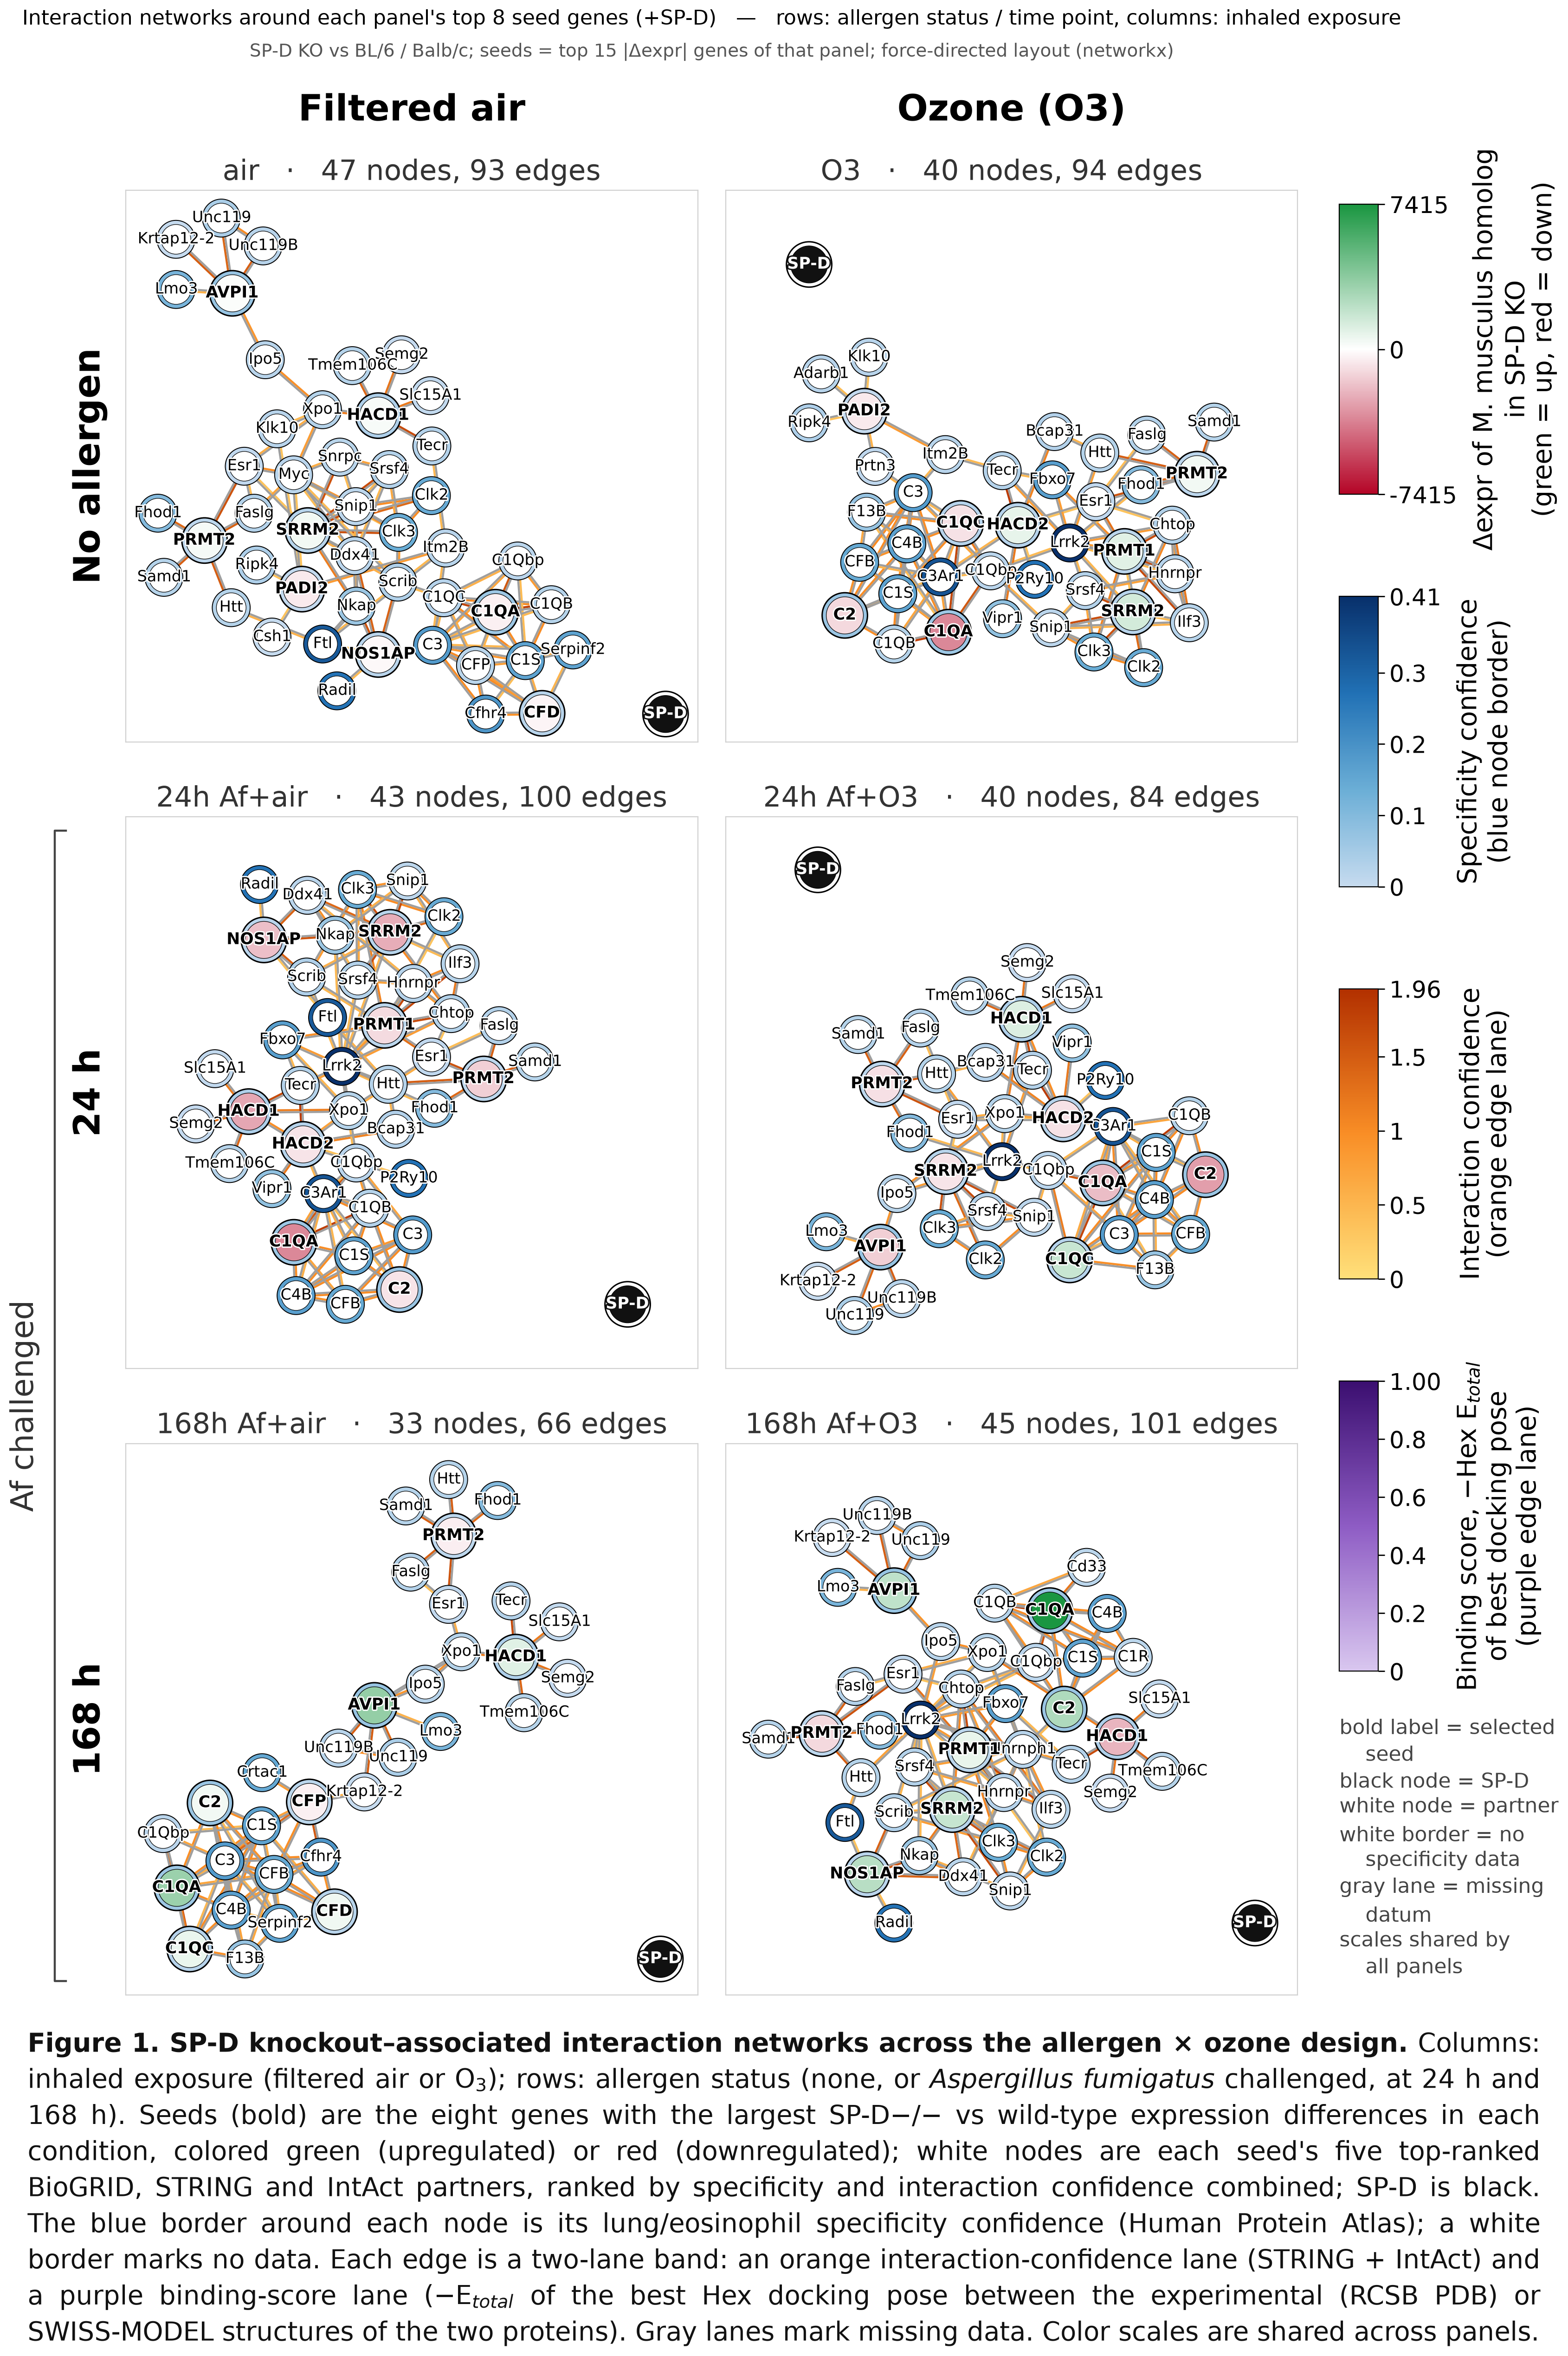

In [7]:
for _req in ("panel_networks", "panel_items", "PANELS", "PANEL_LABEL",
             "TIME_ROWS", "CONDITION_COLS", "hpa_specificity", "panel_selection"):
    if _req not in globals():
        raise RuntimeError(f"'{_req}' missing -- run CELLS 0-3 before this cell.")
if any("spec_conf" not in d for _G in panel_networks.values() for _, d in _G.nodes(data=True)):
    raise RuntimeError("Panel graphs carry no specificity scores -- run CELL 3 first.")
_HAS_BINDING = any("binding_conf" in d for _G in panel_networks.values()
                   for _, _, d in _G.edges(data=True))
if not _HAS_BINDING:
    print("NOTE: no Hex binding scores on the graphs (CELL 4 has not run since CELL 2) -- "
          "the purple binding lane will be gray.\n")

import os
import re
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_hex
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import MaxNLocator

SPD_LABEL             = "SP-D"      # label drawn on the SP-D node (instead of its gene name)

FIGURE_SIZE_IN = (17.0, 25.8)       # (width, height) of the figure in inches = the poster's
PANEL_W, PANEL_H   = 7.5, 6.0       # size of ONE panel, inches -- used only when
DPI          = 200                  # on-screen resolution
PNG_DPI      = 300                  # resolution of the saved PNG (print quality at 100 %)
LAYOUT_ITERS = 450                  # force-directed (networkx spring_layout) iterations
LAYOUT_SEED  = 7                    # RNG seed -> reproducible layout
SHARED_PANEL_SCALE = True           # True -> identical drawing scale in every panel, so
SAVE_PATH    = "network_grid.png"   # raster copy at PNG_DPI (None = skip)
PDF_PATH     = "network_grid.pdf"   # vector copy (None = skip)

FIGURE_ANNOTATION = """
**Figure 1. SP-D knockout–associated interaction networks across the allergen × ozone design.**
Columns: inhaled exposure (filtered air or O$_3$); rows: allergen status (none, or *Aspergillus
fumigatus* challenged, at 24 h and 168 h). Seeds (bold) are the eight genes with the
largest SP-D−/− vs wild-type expression differences in each condition, colored green (upregulated) or
red (downregulated); white nodes are each seed's five top-ranked BioGRID, STRING and IntAct partners, ranked by
specificity and interaction confidence combined; SP-D is black. The blue border around each node is
its lung/eosinophil specificity confidence (Human Protein Atlas); a white border marks no data. Each edge
is a two-lane band: an orange interaction-confidence lane (STRING + IntAct) and a purple binding-score lane
(−E$_{total}$ of the best Hex docking pose between the experimental (RCSB PDB) or SWISS-MODEL structures of the
two proteins). Gray lanes mark missing data. Color scales are shared across panels.
"""
ANNOTATION_JUSTIFY = True           # True -> justified lines; False -> ragged right

FONT_SCALE     = 1.0                # multiplies EVERY text size below -- one knob to make all
LABEL_FS       = 12.0               # node labels (seeds +0.5 pt, bold)
HEADER_FS      = 28.0               # column (exposure) and row (allergen / time) headers
PANEL_TITLE_FS = 22.0               # title above each panel (condition · nodes, edges)
SUPTITLE_FS    = 18.0               # title line at the top of the figure (shrunk to fit)
SUBTITLE_FS    = 14.0               # small line under it
CBAR_LABEL_FS  = 20.0               # colour-bar titles
CBAR_TICK_FS   = 18.0               # colour-bar tick values
CBAR_NOTE_FS   = 16.0               # key under the colour bars
ANNOTATION_FS  = 20.0               # figure legend under the grid

COL_PARTNER = "#ffffff"                             # partner node fill: white
COL_GRAY  = "#9e9e9e"                               # missing-data lanes
COL_NO_SPEC = "#ffffff"                             # node border when there is no specificity data
COL_SPD   = "#111111"                               # SP-D node: black (purple = binding lane)
COL_SPD_LABEL = "#ffffff"                           # SP-D label: white, with a dark outline
EXPR_COLORS = ["#b40426", "#ffffff", "#1a9641"]     # down (red) - none (white) - up (green)
SPEC_COLORS = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]   # pale blue -> sky -> blue -> navy
INT_COLORS  = ["#ffe07a", "#f98e26", "#b23000"]     # pale yellow -> orange -> burnt orange
BIND_COLORS = ["#d9c7ef", "#8e5cc4", "#3b0f70"]     # lavender -> purple -> deep violet

EDGE_WIDTH   = 1.6                  # width of EACH lane in points; a connection is 2x this wide
RING_WIDTH   = 3.2                  # width of the specificity border around each node, points
R_PART, R_SEED = 0.24, 0.30         # node radii (layout units)
CBAR_WIDTH     = 0.42               # colour-bar thickness, inches
NODE_SPACING = 4.0                  # typical nearest-neighbour distance, in partner radii

(LABEL_FS, HEADER_FS, PANEL_TITLE_FS, SUPTITLE_FS, SUBTITLE_FS, CBAR_LABEL_FS, CBAR_TICK_FS,
 CBAR_NOTE_FS, ANNOTATION_FS) = (v * FONT_SCALE for v in (
    LABEL_FS, HEADER_FS, PANEL_TITLE_FS, SUPTITLE_FS, SUBTITLE_FS, CBAR_LABEL_FS, CBAR_TICK_FS,
    CBAR_NOTE_FS, ANNOTATION_FS))

cmap_expr = LinearSegmentedColormap.from_list("expr", EXPR_COLORS)
cmap_spec = LinearSegmentedColormap.from_list("spec", SPEC_COLORS)
cmap_int  = LinearSegmentedColormap.from_list("intr", INT_COLORS)
cmap_bind = LinearSegmentedColormap.from_list("bind", BIND_COLORS)


def _fmt(v):
    return f"{v:.0f}" if abs(v) >= 10 else f"{v:.2f}"


def _disp(G, u):
    if u in G:
        return G.nodes[u].get("display") or u.title()
    return disp(u) if "disp" in globals() else u.title()


def _has_spec(attrs):
    """True if CELL 3 found specificity data for this node. CELL 3 writes this flag as
    'has_spec_data'; this cell used to look for 'in_hpa' -- an attribute nothing ever
    sets -- so every node looked data-less and every specificity border was drawn blank."""
    return bool(attrs.get("has_spec_data", attrs.get("in_hpa", False)))


def select_display_graph(panel):
    """The subgraph drawn in one panel, as a new networkx.Graph, built from CELL 3's
    panel_selection (seeds + SP-D, the top proxy candidates, and the chosen edges)."""
    G = panel_networks[panel]
    sel = panel_selection[panel]
    edges = sorted(tuple(sorted(e)) for e in sel["edges"])
    D = nx.Graph()
    D.add_nodes_from((u, G.nodes[u]) for u in sorted({n for e in edges for n in e}))
    D.add_edges_from((u, v, G.edges[u, v]) for u, v in edges)
    for s in sel["nodes"]:
        if s not in D:
            attrs = dict(G.nodes[s]) if s in G else {"display": _disp(G, s), "role": "seed",
                                                     "spec_conf": 0.0, "has_spec_data": False}
            D.add_node(s, **attrs)
    return {"panel": panel, "D": D, "seeds": set(sel["anchors"]), "spd": set(sel["spd"]),
            "spd_added": sel["spd_added"], "seed_expr": sel["seed_expr"],
            "proxies": list(sel["proxies"])}


def _remove_overlaps(P, rad, sep=1.7, iters=260):
    """Push apart any two nodes closer than sep x (sum of radii)."""
    if len(P) < 2:
        return P
    min_d = (rad[:, None] + rad[None, :]) * sep
    for _ in range(iters):
        delta = P[:, None, :] - P[None, :, :]
        dist = np.sqrt(np.sum(delta ** 2, axis=2)) + 1e-9
        np.fill_diagonal(dist, np.inf)
        ov = np.clip(min_d - dist, 0.0, None)
        if not ov.any():
            break
        P = P + 0.5 * np.sum((ov / dist)[:, :, None] * delta, axis=1)
        P += -(P - P.mean(axis=0)) * 0.004
    return P


def _component_layout(C, radius, seed):
    """Force-directed layout of ONE connected component -> {node: (x, y)} at 0."""
    nodes = sorted(C)                    # fixed node order -> reproducible layout
    if len(nodes) == 1:
        return {nodes[0]: (0.0, 0.0)}
    S = nx.Graph()
    S.add_nodes_from(nodes)
    S.add_edges_from(C.edges())
    raw = nx.spring_layout(S, iterations=LAYOUT_ITERS, seed=seed, weight=None)
    P = np.array([raw[u] for u in nodes], dtype=float)
    dist = np.sqrt(np.sum((P[:, None, :] - P[None, :, :]) ** 2, axis=2))
    np.fill_diagonal(dist, np.inf)
    nn = float(np.median(dist.min(axis=1)))
    if nn > 0:
        P *= (NODE_SPACING * R_PART) / nn
    P = _remove_overlaps(P, np.array([radius[u] for u in nodes]))
    P -= P.mean(axis=0)
    return {u: (float(P[i, 0]), float(P[i, 1])) for i, u in enumerate(nodes)}


def _pack(layouts, radius, target_aspect, pad):
    """Shelf-pack component boxes; search the row width whose resulting aspect
    best matches target_aspect, so the packed drawing fills the panel."""
    boxes = []
    for cl in layouts:
        xs = [p[0] for p in cl.values()]; ys = [p[1] for p in cl.values()]
        rm = max(radius[u] for u in cl)
        minx, miny = min(xs) - rm, min(ys) - rm
        maxx, maxy = max(xs) + rm, max(ys) + rm
        boxes.append((maxx - minx, maxy - miny,
                      {u: (p[0] - minx, p[1] - miny) for u, p in cl.items()}))

    def _shelf(row_w):
        x = y = row_h = 0.0; placed = {}; used_w = 0.0
        for w, h, shifted in boxes:              # components arrive large -> small
            if x > 0 and x + w > row_w:
                x = 0.0; y += row_h + pad; row_h = 0.0
            for u, p in shifted.items():
                placed[u] = (x + p[0], y + p[1])
            x += w + pad; row_h = max(row_h, h); used_w = max(used_w, x - pad)
        return placed, used_w, (y + row_h)

    widths = [w for w, _, _ in boxes]
    lo, hi = max(widths), sum(widths) + pad * len(boxes)
    best = None
    for row_w in np.linspace(lo, hi, 28):
        placed, W, H = _shelf(row_w)
        score = abs(np.log((W / max(H, 1e-9)) / target_aspect))
        if best is None or score < best[0]:
            best = (score, placed)
    return best[1]


def layout_panel(prep, seed_offset):
    D, seeds = prep["D"], prep["seeds"]
    radius = {u: (R_SEED if u in seeds else R_PART) for u in D}
    comps = sorted(nx.connected_components(D), key=lambda c: (-len(c), min(c)))
    layouts = [_component_layout(D.subgraph(c), radius, LAYOUT_SEED + seed_offset + i)
               for i, c in enumerate(comps)]
    pos = _pack(layouts, radius, PANEL_W / PANEL_H, pad=R_SEED * 3.0)
    pad = R_SEED + 0.15                          # room for labels at the panel edge
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    prep.update(radius=radius, pos=pos,
                bounds=(min(xs) - pad, max(xs) + pad, min(ys) - pad, max(ys) + pad))


def _norm_from(vals):
    """Scale for a metric: always starts at 0 (so the bar has a 0 tick)."""
    vals = [v for v in vals if v is not None]
    top = max(vals) if vals else 1.0
    return Normalize(0.0, top if top > 0 else 1.0)


def _zero_ticks(norm):
    """Nice ticks from 0..vmax that always include 0 AND the top of the scale (vmax).
    A nice tick sitting too close under the top is dropped so the labels don't collide."""
    top = float(norm.vmax)
    ticks = list(MaxNLocator(nbins=5, steps=[1, 2, 2.5, 5, 10]).tick_values(0.0, top))
    ticks = [t for t in ticks if -1e-9 <= t < top - 0.12 * top]
    if not any(abs(t) < 1e-9 for t in ticks):
        ticks = [0.0] + ticks
    return sorted({round(t, 6) for t in ticks}) + [top]


def _zero_ticklabels(ticks):
    """Labels for _zero_ticks: plain for the round ticks, _fmt() for the top value."""
    return [f"{t:g}" for t in ticks[:-1]] + [_fmt(ticks[-1])]


_M = max((abs(v) for p in PANELS if p in panel_selection
          for u, v in panel_selection[p]["seed_expr"].items()
          if u not in panel_selection[p]["spd"]), default=1.0) or 1.0
norm_expr = Normalize(-_M, _M)
norm_spec = _norm_from([d["spec_conf"] for G in panel_networks.values()
                        for _, d in G.nodes(data=True) if _has_spec(d)])
norm_int = _norm_from([c for G in panel_networks.values()
                       for _, _, c in G.edges(data="interaction_conf")])
norm_bind = _norm_from([c for G in panel_networks.values()
                        for _, _, c in G.edges(data="binding_conf")])

_bars = [
    (cmap_expr, norm_expr, f"Δexpr of M. musculus homolog\nin {TARGET_STRAIN}\n(green = up, red = down)",
     [-_M, 0, _M], [_fmt(-_M), "0", _fmt(_M)]),
    (cmap_spec, norm_spec, "Specificity confidence\n(blue node border)",
     _zero_ticks(norm_spec), _zero_ticklabels(_zero_ticks(norm_spec))),
    (cmap_int, norm_int, "Interaction confidence\n(orange edge lane)",
     _zero_ticks(norm_int), _zero_ticklabels(_zero_ticks(norm_int))),
    (cmap_bind, norm_bind, "Binding score, −Hex E$_{total}$\nof best docking pose\n(purple edge lane)",
     _zero_ticks(norm_bind), _zero_ticklabels(_zero_ticks(norm_bind))),
]
_KEY = ("bold label = selected\n    seed\nblack node = SP-D\nwhite node = partner\n"
        "white border = no\n    specificity data\ngray lane = missing\n    datum\n"
        "scales shared by\n    all panels")     # short lines keep the colour-bar column narrow


nrows, ncols = len(TIME_ROWS), len(CONDITION_COLS)
_scratch = plt.figure(dpi=DPI)
_renderer = _scratch.canvas.get_renderer()


def _text_in(s, fs, **kw):
    """(width, height) in inches of a piece of text, as matplotlib will draw it."""
    t = _scratch.text(0, 0, s, fontsize=fs, **kw)
    bb = t.get_window_extent(_renderer)
    t.remove()
    return bb.width / _scratch.dpi, bb.height / _scratch.dpi


def _parse_annotation(text):
    """Markup -> paragraphs -> words; a word is a list of (text, bold, italic) pieces."""
    paragraphs = []
    for para in re.split(r"\n\s*\n", (text or "").strip()):
        para = " ".join(para.split())
        if not para:
            continue
        words, cur, bold, ital = [], [], False, False
        for piece in re.split(r"(\*\*|\*)", para):
            if piece == "**":
                bold = not bold; continue
            if piece == "*":
                ital = not ital; continue
            for k, chunk in enumerate(piece.split(" ")):
                if k > 0 and cur:                 # a space ends the current word
                    words.append(cur); cur = []
                if chunk:
                    cur.append((chunk, bold, ital))
        if cur:
            words.append(cur)
        paragraphs.append(words)
    return paragraphs


def _layout_annotation(text, width_in, fs):
    """Wrap the legend to width_in inches using real text measurements.
    Returns (lines, line_height_in); each line is (words, word_widths, space_w, justify)."""
    paragraphs = _parse_annotation(text)
    if not paragraphs:
        return [], 0.0
    cache = {}

    def seg_w(t, bold, ital):
        key = (t, bold, ital)
        if key not in cache:
            cache[key] = _text_in(t, fs, weight="bold" if bold else "normal",
                                  style="italic" if ital else "normal")[0]
        return cache[key]

    space_w = seg_w("a a", False, False) - seg_w("aa", False, False)
    lines = []
    for words in paragraphs:
        words = [[(t, bo, it, seg_w(t, bo, it)) for t, bo, it in w] for w in words]
        widths = [sum(seg[3] for seg in w) for w in words]
        line, lw = [], []
        for w, wd in zip(words, widths):
            if line and sum(lw) + space_w * len(line) + wd > width_in:
                lines.append((line, lw, space_w, True))
                line, lw = [], []
            line.append(w); lw.append(wd)
        if line:
            lines.append((line, lw, space_w, False))   # a paragraph's last line is never justified
        lines.append(None)                             # paragraph gap
    return lines[:-1], fs * 1.4 / 72.0


_hdr_in, _grp_fs = HEADER_FS / 72.0, HEADER_FS - 4.0
_grp_in = _grp_fs / 72.0
ROW_CX_OFF = 0.15 + 0.6 * _hdr_in                  # LEFT - this = centre of the row headers
BRACKET_OFF = ROW_CX_OFF + 0.6 * _hdr_in + 0.15     # LEFT - this = the bracket's spine
GROUP_CX_OFF = BRACKET_OFF + 0.12 + 0.6 * _grp_in   # LEFT - this = centre of the group label
LEFT = GROUP_CX_OFF + 0.6 * _grp_in + 0.12

Y_SUP = 0.15                                        # inches below the top edge (text top)
Y_SUB = Y_SUP + SUPTITLE_FS * 1.3 / 72.0 + 0.04
Y_HDR = Y_SUB + SUBTITLE_FS * 1.3 / 72.0 + 0.25 + HEADER_FS * 1.1 / 72.0   # header bottom
_title_in = (PANEL_TITLE_FS * 1.3 + 8.0) / 72.0     # a panel title + its 8 pt pad
TOP = Y_HDR + 0.15 + _title_in
BOTTOM = 0.3
HGAP, VGAP = 0.3, _title_in + 0.3                  # gaps between panels (VGAP holds panel titles)

_tick_w = max(_text_in(t, CBAR_TICK_FS)[0] for *_, tl in _bars for t in tl)
_lab_h = max(_text_in(lab, CBAR_LABEL_FS, linespacing=1.15)[1] for _, _, lab, _, _ in _bars)
_key_w, _key_h_txt = _text_in(_KEY, CBAR_NOTE_FS, linespacing=1.3)
CBAR_GAP = 0.45
CBAR_AREA = max(CBAR_WIDTH + (5 + 3.5 + 10) / 72.0 + _tick_w + _lab_h, _key_w) + 0.15

ANNOT_X0 = 0.35                                    # legend left / right margin (inches)
if FIGURE_SIZE_IN:
    fig_w, fig_h = (float(v) for v in FIGURE_SIZE_IN)
    PANEL_W = (fig_w - LEFT - (ncols - 1) * HGAP - CBAR_GAP - CBAR_AREA) / ncols
else:
    fig_w = LEFT + ncols * PANEL_W + (ncols - 1) * HGAP + CBAR_GAP + CBAR_AREA
_annot_w = fig_w - 2 * ANNOT_X0
_annot_lines, _annot_lh = _layout_annotation(FIGURE_ANNOTATION, _annot_w, ANNOTATION_FS)
ANNOT_H = (len(_annot_lines) * _annot_lh + 0.45) if _annot_lines else 0.0
if FIGURE_SIZE_IN:
    PANEL_H = (fig_h - TOP - (nrows - 1) * VGAP - BOTTOM - ANNOT_H) / nrows
else:
    fig_h = TOP + nrows * PANEL_H + (nrows - 1) * VGAP + BOTTOM + ANNOT_H
if min(PANEL_W, PANEL_H) < 1.0:
    raise ValueError(f"FIGURE_SIZE_IN {FIGURE_SIZE_IN} leaves panels of only "
                     f"{PANEL_W:.2f} x {PANEL_H:.2f} in -- lower FONT_SCALE or shorten "
                     f"FIGURE_ANNOTATION.")

_grid_cx = LEFT + (fig_w - LEFT - CBAR_GAP - CBAR_AREA) / 2
_sup_room = 2 * min(_grid_cx, fig_w - _grid_cx) - 0.3
_any_spd = any(panel_selection[p]["spd_added"] for p in PANELS if p in panel_selection)
_sup_txt = (f"Interaction networks around each panel's top {TOP_N_SEEDS} seed genes"
            f"{' (+SP-D)' if _any_spd else ''}   —   rows: allergen status / time point, "
            f"columns: inhaled exposure")
_sub_txt = (f"{TARGET_STRAIN} vs {REF_A} / {REF_B}; seeds = top {TOP_N} |Δexpr| genes of that "
            f"panel; force-directed layout (networkx)")
_sup_fs = min(SUPTITLE_FS, SUPTITLE_FS * _sup_room / _text_in(_sup_txt, SUPTITLE_FS)[0])
_sub_fs = min(SUBTITLE_FS, SUBTITLE_FS * _sup_room / _text_in(_sub_txt, SUBTITLE_FS)[0])
plt.close(_scratch)


def _panel_rect(i, j):
    x0 = LEFT + j * (PANEL_W + HGAP)
    y0 = fig_h - TOP - (i + 1) * PANEL_H - i * VGAP
    return [x0 / fig_w, y0 / fig_h, PANEL_W / fig_w, PANEL_H / fig_h]


panel_preps = {}
for _k, _panel in enumerate(PANELS):
    _prep = select_display_graph(_panel)
    layout_panel(_prep, seed_offset=100 * _k)
    panel_preps[_panel] = _prep
panel_display_graphs = {p: q["D"] for p, q in panel_preps.items()}
panel_positions = {p: q["pos"] for p, q in panel_preps.items()}

print("SP-D in each panel:")
for _panel, _prep in panel_preps.items():
    _shown = [u for u in _prep["D"] if u in _prep["spd"]]
    if _shown:
        _txt = ", ".join(f"{SPD_LABEL} ({_disp(_prep['D'], u)}) [{_prep['D'].degree(u)} partner(s)]"
                         for u in _shown)
    elif ALWAYS_INCLUDE_SPD:
        _txt = "WARNING: not drawn -- check SPD_NODE_SYMBOLS / SPD_MOUSE_GENES in CELL 3"
    else:
        _txt = "not drawn (ALWAYS_INCLUDE_SPD = False and not among the panel's nodes)"
    print(f"  {panel_title(_panel):<28} {_txt}")

print("\nDrawn nodes with a specificity border, and drawn edges with data per lane "
      "(the rest are drawn white / gray):")
print(f"  {'panel':<28} {'nodes':>5} {'specificity':>12} {'edges':>6} {'interaction':>12} {'binding':>8}")
_missing_binding = set()
for _panel, _prep in panel_preps.items():
    _D = _prep["D"]
    _E = list(_D.edges(data=True))
    _n_s = sum(_has_spec(d) for _, d in _D.nodes(data=True))
    _n_i = sum(d.get("interaction_conf") is not None for _, _, d in _E)
    _n_b = sum(d.get("binding_conf") is not None for _, _, d in _E)
    _missing_binding |= {tuple(sorted((u, v))) for u, v, d in _E if d.get("binding_conf") is None}
    print(f"  {panel_title(_panel):<28} {_D.number_of_nodes():>5} {_n_s:>12} {len(_E):>6} "
          f"{_n_i:>12} {_n_b:>8}")
if _HAS_BINDING and _missing_binding:
    print(f"  {len(_missing_binding)} drawn protein pair(s) have no Hex binding score (not docked "
          f"yet, no structure, or docking failed -- see hex_binding_df in CELL 4).")


def _node_face(prep, u):
    if u in prep["spd"]:
        return COL_SPD
    if prep["D"].nodes[u].get("role") == "seed" and u in prep["seed_expr"]:
        return to_hex(cmap_expr(norm_expr(prep["seed_expr"][u])))
    return COL_PARTNER


def _node_ring(prep, u):
    """Border colour = the node's own specificity confidence (white if no data)."""
    d = prep["D"].nodes[u]
    if not _has_spec(d):
        return COL_NO_SPEC
    return to_hex(cmap_spec(norm_spec(d.get("spec_conf", 0.0))))


def _scale(b):
    return max((b[1] - b[0]) / PANEL_W, (b[3] - b[2]) / PANEL_H)

_scales = {p: _scale(q["bounds"]) for p, q in panel_preps.items()}
_shared = max(_scales.values(), default=1.0)
if SHARED_PANEL_SCALE:
    _scales = {p: _shared for p in _scales}


def _draw_lane_edges(ax, prep):
    """Each edge = two parallel lanes (interaction | binding), offset by half a line
    width each side IN POINTS, so the lanes touch exactly at any zoom, DPI or
    panel scale."""
    D, pos = prep["D"], prep["pos"]
    segs, normals, int_cols, bind_cols = [], [], [], []
    for u, v, d in D.edges(data=True):
        p1, p2 = np.asarray(pos[u]), np.asarray(pos[v])
        vec = p2 - p1
        L = float(np.hypot(*vec))
        if L == 0:
            continue
        segs.append([p1, p2])
        normals.append((-vec[1] / L, vec[0] / L))       # unit normal (data == display, aspect 1)
        ic = d.get("interaction_conf")
        bc = d.get("binding_conf")
        int_cols.append(cmap_int(norm_int(ic)) if ic is not None else COL_GRAY)
        bind_cols.append(cmap_bind(norm_bind(bc)) if bc is not None else COL_GRAY)
    if not segs:
        return
    lane_in = EDGE_WIDTH / 72.0                         # one lane width, in inches
    normals = np.asarray(normals) * lane_in
    for k, cols in ((+0.5, int_cols), (-0.5, bind_cols)):
        ax.add_collection(LineCollection(
            segs, colors=cols, linewidths=EDGE_WIDTH, capstyle="butt", zorder=1,
            offsets=k * normals, offset_transform=ax.figure.dpi_scale_trans),
            autolim=False)


def _draw_panel(ax, prep, s):
    D, pos, radius, seeds = prep["D"], prep["pos"], prep["radius"], prep["seeds"]
    _draw_lane_edges(ax, prep)

    pts_per_unit = 72.0 / s                             # layout units -> points
    for group, lw, z in (([u for u in D if u not in seeds], 0.7, 3.0),
                         ([u for u in D if u in seeds], 1.1, 3.5)):
        if not group:
            continue
        ring = nx.draw_networkx_nodes(
            D, pos, nodelist=group, ax=ax,
            node_size=[(2 * radius[u] * pts_per_unit + 2 * RING_WIDTH) ** 2 for u in group],
            node_color=[_node_ring(prep, u) for u in group],
            edgecolors="black", linewidths=lw)
        ring.set_zorder(z)
        fill = nx.draw_networkx_nodes(
            D, pos, nodelist=group, ax=ax,
            node_size=[(2 * radius[u] * pts_per_unit) ** 2 for u in group],
            node_color=[_node_face(prep, u) for u in group],
            edgecolors="black", linewidths=0.45)
        fill.set_zorder(z + 0.1)

    spd = prep["spd"]
    for group, fs, weight in (([u for u in D if u not in seeds and u not in spd], LABEL_FS, "normal"),
                              ([u for u in D if u in seeds and u not in spd], LABEL_FS + 0.5, "bold")):
        texts = nx.draw_networkx_labels(D, pos, labels={u: _disp(D, u) for u in group},
                                        font_size=fs, font_weight=weight, ax=ax)
        for t in texts.values():
            t.set_zorder(4)
            t.set_path_effects([pe.withStroke(linewidth=2.0, foreground="white")])
    for u in (u for u in D if u in spd):
        texts = nx.draw_networkx_labels(D, pos, labels={u: SPD_LABEL},
                                        font_size=LABEL_FS + (0.5 if u in seeds else 0),
                                        font_weight="bold" if u in seeds else "normal",
                                        font_color=COL_SPD_LABEL, ax=ax)
        for t in texts.values():
            t.set_zorder(4.5)
            t.set_path_effects([pe.withStroke(linewidth=2.2, foreground=COL_SPD)])

    x0, x1, y0, y1 = prep["bounds"]
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    ax.set_xlim(cx - s * PANEL_W / 2, cx + s * PANEL_W / 2)
    ax.set_ylim(cy - s * PANEL_H / 2, cy + s * PANEL_H / 2)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_color("#d0d0d0")
    n_n, n_e = D.number_of_nodes(), D.number_of_edges()
    ax.set_title(f"{PANEL_LABEL[prep['panel']]}   ·   {n_n} node{'s' * (n_n != 1)}, "
                 f"{n_e} edge{'s' * (n_e != 1)}", fontsize=PANEL_TITLE_FS, color="#333333", pad=8)
    if not panel_networks[prep["panel"]].graph.get("seeds"):
        ax.text(0.5, 0.06, "no selected gene in this panel has a human ortholog",
                ha="center", va="bottom", fontsize=CBAR_NOTE_FS, color="#888888", transform=ax.transAxes)


fig = plt.figure(figsize=(fig_w, fig_h), dpi=DPI)
for i, t in enumerate(TIME_ROWS):
    for j, c in enumerate(CONDITION_COLS):
        ax = fig.add_axes(_panel_rect(i, j))
        if (t, c) in panel_preps:
            _draw_panel(ax, panel_preps[(t, c)], _scales[(t, c)])
        else:
            ax.axis("off")
            ax.text(0.5, 0.5, "(not measured)", ha="center", va="center",
                    fontsize=CBAR_NOTE_FS, color="#888888", transform=ax.transAxes)

for j, c in enumerate(CONDITION_COLS):
    r = _panel_rect(0, j)
    fig.text(r[0] + r[2] / 2, (fig_h - Y_HDR) / fig_h, c,
             ha="center", va="bottom", fontsize=HEADER_FS, weight="bold")
_untimed = globals().get("UNTIMED_TIME_LABEL")
for i, t in enumerate(TIME_ROWS):
    r = _panel_rect(i, 0)
    fig.text((LEFT - ROW_CX_OFF) / fig_w, r[1] + r[3] / 2, t, ha="center", va="center",
             rotation=90, fontsize=HEADER_FS, weight="bold")

_group_label = globals().get("ALLERGEN_GROUP_LABEL")
_timed = [i for i, t in enumerate(TIME_ROWS) if t != _untimed]
if _group_label and _timed:
    _top = _panel_rect(_timed[0], 0); _bot = _panel_rect(_timed[-1], 0)
    _y1, _y0 = _top[1] + _top[3] - 0.15 / fig_h, _bot[1] + 0.15 / fig_h
    _xb, _tick = (LEFT - BRACKET_OFF) / fig_w, 0.12 / fig_w
    fig.add_artist(plt.Line2D([_xb + _tick, _xb, _xb, _xb + _tick], [_y1, _y1, _y0, _y0],
                              transform=fig.transFigure, color="#444444", lw=1.6))
    fig.text((LEFT - GROUP_CX_OFF) / fig_w, (_y0 + _y1) / 2, _group_label, ha="center",
             va="center", rotation=90, fontsize=_grp_fs, color="#333333")

fig.text(_grid_cx / fig_w, 1 - Y_SUP / fig_h, _sup_txt,
         ha="center", va="top", fontsize=_sup_fs)
fig.text(_grid_cx / fig_w, 1 - Y_SUB / fig_h, _sub_txt,
         ha="center", va="top", fontsize=_sub_fs, color="#555555")


def _cbar(rect, cmap, norm, label, ticks=None, ticklabels=None):
    cax = fig.add_axes(rect)
    sm = ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
    cb = fig.colorbar(sm, cax=cax)
    if ticks is not None:
        cb.set_ticks(ticks)
    if ticklabels is not None:
        cb.set_ticklabels(ticklabels)
    cb.ax.tick_params(labelsize=CBAR_TICK_FS, length=5, width=1.0)
    cb.outline.set_linewidth(0.8)
    cb.set_label(label, fontsize=CBAR_LABEL_FS, labelpad=10, linespacing=1.15)

_nb = len(_bars)
_key_h = 0.45 + _key_h_txt                                       # key height, inches
_grid_bottom, _grid_top = BOTTOM + ANNOT_H, fig_h - TOP
_bar_gap = 1.1
_bar_h = max(0.5, min(3.6, (_grid_top - _grid_bottom - _key_h - 0.3 - (_nb - 1) * _bar_gap) / _nb))
_block_h = _nb * _bar_h + (_nb - 1) * _bar_gap + _key_h
_stack_top = (_grid_top + _grid_bottom) / 2 + _block_h / 2
_bx = (fig_w - CBAR_AREA) / fig_w
_bw = CBAR_WIDTH / fig_w
for k, (cm, nm, lab, tk, tl) in enumerate(_bars):
    _y = _stack_top - (k + 1) * _bar_h - k * _bar_gap
    _cbar([_bx, _y / fig_h, _bw, _bar_h / fig_h], cm, nm, lab, ticks=tk, ticklabels=tl)
fig.text(_bx, (_stack_top - _nb * _bar_h - (_nb - 1) * _bar_gap - 0.45) / fig_h, _KEY,
         fontsize=CBAR_NOTE_FS, color="#444444", va="top", linespacing=1.3)

if _annot_lines:
    _y = BOTTOM + ANNOT_H - 0.3 - _annot_lh * 0.8     # first baseline, inches from bottom
    for _line in _annot_lines:
        if _line is None:                             # blank line between paragraphs
            _y -= _annot_lh; continue
        _words, _widths, _space, _justify = _line
        _gap = _space
        if ANNOTATION_JUSTIFY and _justify and len(_words) > 1:
            _gap = (_annot_w - sum(_widths)) / (len(_words) - 1)
        _x = ANNOT_X0
        for _word, _wd in zip(_words, _widths):
            _xs = _x
            for _t, _b, _i, _sw in _word:              # styled pieces of one word
                fig.text(_xs / fig_w, _y / fig_h, _t, fontsize=ANNOTATION_FS,
                         weight="bold" if _b else "normal",
                         style="italic" if _i else "normal",
                         ha="left", va="baseline", color="#111111")
                _xs += _sw
            _x += _wd + _gap
        _y -= _annot_lh

_save_kw = {} if FIGURE_SIZE_IN else {"bbox_inches": "tight"}
_size_note = f"  ({fig_w:g} x {fig_h:g} in -- place at 100 %)" if FIGURE_SIZE_IN else ""
print(f"\nPanels {PANEL_W:.2f} x {PANEL_H:.2f} in; node labels {LABEL_FS:g} pt, "
      f"headers {HEADER_FS:g} pt, legend {ANNOTATION_FS:g} pt (FONT_SCALE {FONT_SCALE:g}).")
if PDF_PATH:
    fig.savefig(PDF_PATH, format="pdf", facecolor="white", **_save_kw)
    print(f"Saved {os.path.abspath(PDF_PATH)}{_size_note}")
if SAVE_PATH:
    fig.savefig(SAVE_PATH, dpi=PNG_DPI, facecolor="white", **_save_kw)
    print(f"Saved {os.path.abspath(SAVE_PATH)}{_size_note}")
plt.show()
